In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("cs1090a_hw3.ipynb")

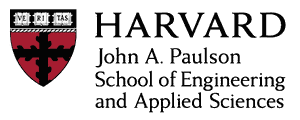

# CS1090A Introduction to Data Science
## Homework 3: How much should you trust the model?
### Regularization, bootstrap inference, missing data, and principal components

**Harvard University**<br/>
**Fall 2026**<br/>
**Instructors**: Pavlos Protopapas, Kevin Rader, and Chris Gumb

<hr style="height:2.4pt">

## Instructions

CS1090A is graded out of 100 points. AC209A students complete the two marked extensions and are graded out of 110.

Run the import cell before beginning, then run each supplied data or settings cell when you reach it. These cells appear beside the questions that use them. Your submitted notebook must run in order after restarting the kernel, using the supplied local files. Include visible outputs, labeled plots, and written answers, and follow the Canvas submission instructions.

Use the supplied partitions and keep test data reserved until the final evaluation questions.

**Use of AI tools**

You may use AI tools. You are accountable for everything you submit: you must understand it and be able to explain it.

- Written answers must be your own words.
- Quizzes and midterms ask you to explain and apply these methods without a tool.

All plots must have axis labels, a descriptive title, and a legend when colors, symbols, or reference lines distinguish information. Include units where applicable.

Written-response requests under **Constraints** are required parts of your answer, as are those listed under **Task** and **Artifacts**.


In [2]:
import os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso, lasso_path
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import norm
from threadpoolctl import threadpool_limits
from hw3_support import (
    CORE,
    FrontageImputer,
    AmesPreprocessor,
    reference_pipeline,
    load_ames,
    fixed_folds,
    bootstrap_folds,
    support_checkpoint,
    checked_ols,
    bootstrap_coefficient_maps,
    load_cookie,
    load_cookie_test,
)

from hw3_cache import cached_bootstrap_results

thread_limit = threadpool_limits(limits=1)
notebook_start = time.time()


# Part 1. Missingness and imputation

We return to the Ames housing data from Homework 2 to predict the natural logarithm of sale price. Before fitting regression models, investigate the missing measurements and decide how to replace them. The supplied loading and preparation code lets you begin with that investigation without repeating the earlier data-cleaning exercises.

We will use three fixed, disjoint groups of houses throughout the Ames questions. The supplied cell below loads the data and creates the variables listed here; run it before Q1.1.

| Group | Variables | Houses | Purpose |
|---|---|---:|---|
| Selection | `X_selection`, `y_selection` | 1,318 | Investigate missingness, tune models using cross-validation, and select predictors. Use these houses for Part 1. |
| Inference | `X_inference`, `y_inference` | 879 | Estimate the selected coefficients and assess uncertainty and predictive importance in Part 3. Keep these outcomes out of predictor selection. |
| Test | `partitions['test']` | 733 | Evaluate the frozen final procedures in Q3.8. Do not inspect or use these houses in the earlier analyses. |

Each `X_...` table contains recorded predictors; its matching `y_...` array contains the natural logarithm of sale price, in the same row order. The selection and inference groups together form the non-test training data. Reserving fresh inference outcomes lets us assess coefficients without reusing the price evidence that selected their predictors; Part 3 explains that distinction in more detail.

`raw_ames` preserves the source records, including recorded zeros. `ames_x` contains the predictor columns prepared by the loader, with unknown frontage marked as missing. `selection_ids` contains the row labels of the houses in the selection partition; `inference_ids` does the same for the inference partition. These labels let us retrieve the corresponding original records from `raw_ames`. In Q1.1, use `raw_ames.loc[selection_ids]` for recorded-zero counts and `X_selection` for missing-value counts. Later Part 1 questions also use the selection houses. The fixed splits and helper definitions ensure everyone can work from the same starting data.


<details>
<summary><b>Column descriptions</b> (click to expand)</summary>

| Column | What it records |
|---|---|
| `Gr_Liv_Area` | above-ground living area, square feet |
| `Total_Bsmt_SF` | basement area, square feet (0 if no basement) |
| `First_Flr_SF` | first-floor area, square feet |
| `Garage_Cars` | garage capacity, in cars (0 if no garage) |
| `Garage_Area` | garage area, square feet (0 if no garage) |
| `Year_Built` | year the house was built |
| `Year_Remod_Add` | year of the last remodel (equals `Year_Built` if never remodelled) |
| `Full_Bath` | full bathrooms above ground |
| `TotRms_AbvGrd` | rooms above ground, not counting bathrooms |
| `Lot_Area` | lot size, square feet |
| `Lot_Frontage` | feet of street connected to the lot; recorded zeros in this file indicate unknown frontage |
| `Mas_Vnr_Area` | masonry veneer area, square feet |
| `Year_Sold` | year of the sale, 2006 to 2010 |
| `Neighborhood` | the named area of Ames where the house is located |
| `Overall_Qual` | rating of the house's material and finish, 10 levels from `Very_Poor` to `Very_Excellent` |
| `House_Style` | e.g. one storey, two storeys, split level |
| `Sale_Condition` | e.g. `Normal`, `Partial` (a new house sold before completion), `Abnorml` (a foreclosure or short sale) |
| `Kitchen_Qual` | kitchen quality, 5 levels |
| `Bldg_Type` | single-family, townhouse, duplex, and so on |
| `Misc_Feature` | a shed, tennis court or similar; `None` means the amenity is absent |
| `Exter_Qual` | exterior material quality, 4 levels |
| `Mas_Vnr_Type` | type of masonry veneer; `None` means the amenity is absent |
| `Central_Air` | `Y` or `N` |
| `Sale_Price` | **the target**, in dollars |

For descriptions of the remaining fields and category codes, see the [complete Ames data dictionary](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt) and the [column names in the supplied version](https://modeldata.tidymodels.org/reference/ames.html).

</details>


In [3]:
# Supplied Ames loading and fixed partitions; see the table above.
raw_ames, ames_x, partitions, prep_template = load_ames()
selection_ids = partitions["selection"]
inference_ids = partitions["inference"]
X_selection = ames_x.loc[selection_ids].copy()
y_selection = np.log(raw_ames.loc[selection_ids, "Sale_Price"].to_numpy())
X_inference = ames_x.loc[inference_ids].copy()
y_inference = np.log(raw_ames.loc[inference_ids, "Sale_Price"].to_numpy())
# Cross-validation indices are positions within the selection tables, not row labels.
selection_folds = fixed_folds(len(X_selection))
print({name: len(ids) for name, ids in partitions.items()})


{'selection': 1318, 'inference': 879, 'test': 733}


## Q1.1. Audit recorded measurements

**3 points**

Before we begin modeling prices, we need to understand what information is available about each house. A recorded zero can describe an absent amenity, such as a pool, or stand in for an unknown measurement. These meanings call for different treatment: replacing a genuine zero would change the recorded characteristics of the house.

**Task:** Use `raw_ames.loc[selection_ids]` to count recorded zeros, and `X_selection` to count missing predictor values. Report predictors with at least one blank or zero. Confirm the meanings of zeros in `Lot_Frontage`, `Garage_Area`, and `Pool_Area` using related columns and the [Ames data documentation](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt). Calculate how many selection houses remain if every row with a missing predictor is deleted.

**Artifacts:** A table showing missing-value and zero counts by predictor; the number and proportion of selection houses retained by complete-case deletion; and a short explanation of which values represent unknown measurements versus absent amenities.

**Constraints:** Preserve raw missingness; distinguish unknown frontage from genuine zeros. Do not repeat Homework 2 encoding or feature engineering.

**Output names for the guided checks:** `audit` (a missingness table) and `complete_rows` (the retained-row count).

The supplied loader preserves literal `None` amenity categories and marks zero frontage as unknown in `X_selection`. In the supplied selection rows, frontage is the only predictor with missing values; this does not make zeros in other predictors missing.

The supplied CSV has basement-type codes in `BsmtFin_SF_1`, rather than area measurements. The loader excludes this mislabeled duplicate; other basement measurements remain.


In [4]:
# Q1.1: recorded zeros come from the raw records; blanks come from the prepared predictors.
raw_selection = raw_ames.loc[selection_ids]
raw_numeric = raw_selection.drop(columns="Sale_Price").select_dtypes("number")
audit = pd.DataFrame(
    {
        "missing": X_selection.isna().sum(),
        "zeros": (raw_numeric == 0).sum().reindex(X_selection.columns),
    }
).fillna(0).astype(int)
audit["missing_share"] = (audit["missing"] / len(X_selection)).round(3)
audit["zero_share"] = (audit["zeros"] / len(X_selection)).round(3)
audit = audit[(audit["missing"] > 0) | (audit["zeros"] > 0)].sort_values(
    ["missing", "zeros"], ascending=False
)
audit.index.name = "predictor"
display(audit)

# Check what a zero means for three columns, using related recorded columns.
print("Garage_Area == 0 versus Garage_Cars == 0 and Garage_Type:")
display(
    pd.crosstab(
        raw_selection["Garage_Area"] == 0,
        raw_selection["Garage_Type"],
        rownames=["Garage_Area == 0"],
    )
)
print(
    "Houses with Garage_Area == 0 but Garage_Cars > 0:",
    int(((raw_selection.Garage_Area == 0) & (raw_selection.Garage_Cars > 0)).sum()),
)
print("Pool_Area == 0 versus Pool_QC:")
display(
    pd.crosstab(
        raw_selection["Pool_Area"] == 0,
        raw_selection["Pool_QC"],
        rownames=["Pool_Area == 0"],
    )
)
frontage_zero = raw_selection["Lot_Frontage"] == 0
print(
    "Lot_Frontage == 0:", int(frontage_zero.sum()),
    "| of these, lots with Lot_Area > 0:", int((raw_selection.loc[frontage_zero, "Lot_Area"] > 0).sum()),
    "| marked missing in X_selection:", int(X_selection.Lot_Frontage.isna().sum()),
)
print("Lot_Config of houses with zero frontage:")
display(raw_selection.loc[frontage_zero, "Lot_Config"].value_counts().to_frame("houses"))

# Complete-case deletion: drop every row with any missing predictor.
complete_rows = int(X_selection.dropna().shape[0])
print(
    f"Complete-case deletion keeps {complete_rows} of {len(X_selection)} selection houses "
    f"({complete_rows / len(X_selection):.1%}); it drops {len(X_selection) - complete_rows}."
)

,missing,zeros,missing_share,zero_share
predictor,,,,
Lot_Frontage,206,206,0.156,0.156
Pool_Area,0,1310,0.000,0.994
Low_Qual_Fin_SF,0,1302,0.000,0.988
Three_season_porch,0,1301,0.000,0.987
Misc_Val,0,1277,0.000,0.969
Bsmt_Half_Bath,0,1241,0.000,0.942
Screen_Porch,0,1196,0.000,0.907
BsmtFin_SF_2,0,1159,0.000,0.879
Enclosed_Porch,0,1122,0.000,0.851


Garage_Area == 0 versus Garage_Cars == 0 and Garage_Type:


Garage_Type,Attchd,Basment,BuiltIn,CarPort,Detchd,More_Than_Two_Types,No_Garage
Garage_Area == 0,,,,,,,
False,786,14,80,6,343,8,0
True,0,0,0,0,0,0,81


Houses with Garage_Area == 0 but Garage_Cars > 0: 0
Pool_Area == 0 versus Pool_QC:


Pool_QC,Excellent,Fair,Good,No_Pool,Typical
Pool_Area == 0,,,,,
False,2,2,2,0,2
True,0,0,0,1310,0


Lot_Frontage == 0: 206 | of these, lots with Lot_Area > 0: 206 | marked missing in X_selection: 206
Lot_Config of houses with zero frontage:


,houses
Lot_Config,
Inside,126
Corner,41
CulDSac,35
FR2,4


Complete-case deletion keeps 1112 of 1318 selection houses (84.4%); it drops 206.


In [5]:
grader.check("q1_1")

q1_1 results: All test cases passed!

**Written response — Q1.1**

Lot frontage is the only predictor with blanks: 206 selection houses (15.6%) record a frontage of 0 and the loader marks them missing. Complete-case deletion would keep 1,112 of 1,318 houses (84.4%).

**Unknown, not zero.** All 206 zero-frontage lots have positive lot area, and 80 of them are corner, cul-de-sac or FR2 (frontage on two sides) lots, which by definition touch a street, so a recorded 0 is a placeholder, not a measurement. We treat these zeros as unknown and impute them.

**Absent, not unknown.** All 81 houses with `Garage_Area == 0` also have `Garage_Cars == 0` and `Garage_Type == "No_Garage"`, and no house with cars has zero area. All 1,310 houses with `Pool_Area == 0` have `Pool_QC == "No_Pool"`, and the 8 pools have positive area. These zeros record that the amenity does not exist, so replacing them would invent amenities. Zeros in other amenity columns (porches, second floors, veneer, basement baths) most plausibly mean the same.

## Q1.2. Investigate the consequences of deletion

**3 points**

The audit shows which houses we would lose if we simply dropped rows with missing measurements. Deletion reduces the sample size, but it can also change which kinds of houses are represented. If missingness is more common in particular neighborhoods or types of properties, the remaining data may give a distorted picture of the population we want to model.

**Task:** Relate missing-frontage indicators to neighborhood and other recorded lot characteristics, displaying group sizes. Interpret evidence relevant to complete-case deletion.

**Artifacts:** A neighborhood summary showing group sizes and missing-frontage rates; one comparison with a recorded lot characteristic; and a short explanation of whether deleting incomplete houses would change the represented population.

**Constraints:** Use selection data. Patterns can challenge MCAR but do not conclusively distinguish MAR from MNAR.

Overall missing-frontage rate: 0.156


,houses,missing,missing_rate
Neighborhood,,,
Green_Hills,2,2,1.000
Clear_Creek,20,10,0.500
Sawyer,68,25,0.368
Northwest_Ames,59,20,0.339
Bloomington_Heights,13,4,0.308
Veenker,11,3,0.273
Gilbert,74,19,0.257
Northridge,32,8,0.250
Greens,4,1,0.250


,count,25%,50%,75%,mean
frontage,,,,,
recorded,1112.0,7314.0,9255.0,11220.0,9693.0
unknown,206.0,8002.0,9984.0,12698.0,11593.0


,houses,missing_rate
Lot_Config,,
Corner,225,0.182
CulDSac,75,0.467
FR2,31,0.129
FR3,2,0.000
Inside,985,0.128


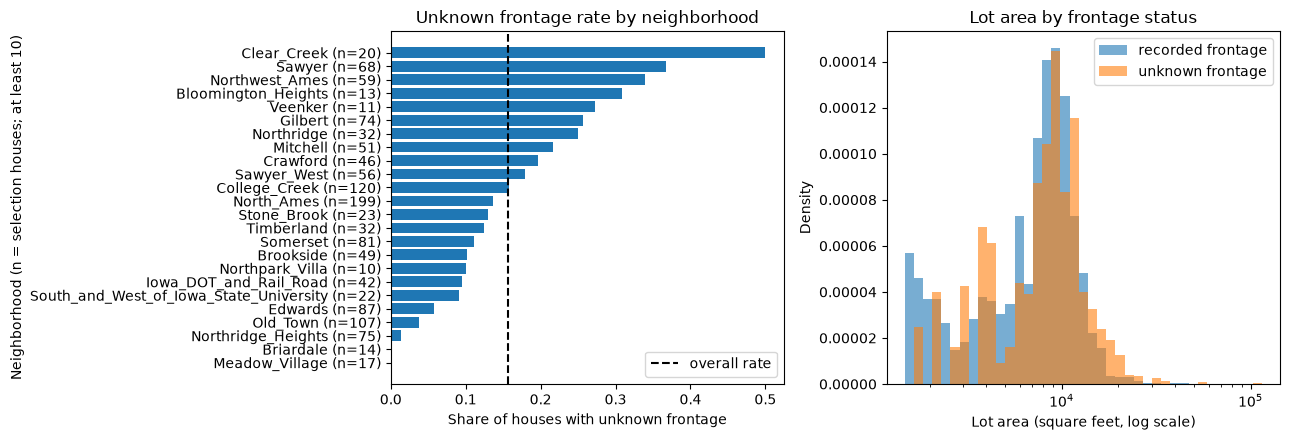

In [6]:
# Q1.2: does unknown frontage cluster in certain neighborhoods or lot types?
frontage_missing = X_selection["Lot_Frontage"].isna()
neighborhood_missing = (
    pd.DataFrame({"Neighborhood": X_selection["Neighborhood"], "missing": frontage_missing})
    .groupby("Neighborhood")["missing"]
    .agg(houses="size", missing="sum", missing_rate="mean")
    .sort_values("missing_rate", ascending=False)
)
neighborhood_missing["missing_rate"] = neighborhood_missing["missing_rate"].round(3)
print(f"Overall missing-frontage rate: {frontage_missing.mean():.3f}")
display(neighborhood_missing)

# Lot characteristics of houses with unknown versus recorded frontage.
lot_comparison = (
    X_selection.assign(frontage=np.where(frontage_missing, "unknown", "recorded"))
    .groupby("frontage")["Lot_Area"]
    .describe()[["count", "25%", "50%", "75%", "mean"]]
)
display(lot_comparison.round(0))
config_rates = (
    pd.DataFrame({"Lot_Config": X_selection["Lot_Config"], "missing": frontage_missing})
    .groupby("Lot_Config")["missing"]
    .agg(houses="size", missing_rate="mean")
)
display(config_rates.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
shown = neighborhood_missing[neighborhood_missing["houses"] >= 10]
axes[0].barh([f"{name} (n={n})" for name, n in zip(shown.index, shown["houses"])], shown["missing_rate"],
             color="tab:blue")
axes[0].axvline(frontage_missing.mean(), color="black", ls="--", label="overall rate")
axes[0].invert_yaxis()
axes[0].set_xlabel("Share of houses with unknown frontage")
axes[0].set_ylabel("Neighborhood (n = selection houses; at least 10)")
axes[0].set_title("Unknown frontage rate by neighborhood")
axes[0].legend()
bins = np.logspace(np.log10(X_selection.Lot_Area.min()), np.log10(X_selection.Lot_Area.max()), 40)
axes[1].hist(X_selection.loc[~frontage_missing, "Lot_Area"], bins=bins, density=True, alpha=0.6, label="recorded frontage")
axes[1].hist(X_selection.loc[frontage_missing, "Lot_Area"], bins=bins, density=True, alpha=0.6, label="unknown frontage")
axes[1].set_xscale("log")
axes[1].set_xlabel("Lot area (square feet, log scale)")
axes[1].set_ylabel("Density")
axes[1].set_title("Lot area by frontage status")
axes[1].legend()
plt.tight_layout()
plt.show()


**Written response — Q1.2**

Unknown frontage is far from uniform. The overall rate is 15.6%, but it is 50% in Clear Creek (10 of 20), 37% in Sawyer (25 of 68) and 34% in Northwest Ames (20 of 59), against 3.7% in Old Town (4 of 107), 1.3% in Northridge Heights (1 of 75) and none in Briardale and Meadow Village (0 of 31). It is 47% for cul-de-sac lots against 13% for inside lots, and lots with unknown frontage are larger (median 9,984 against 9,255 sq ft).

Deleting incomplete houses would therefore change the population we model: we would lose half of Clear Creek and a third of Sawyer and Northwest Ames, keep almost all of Old Town, Briardale and Meadow Village, and end up with slightly smaller lots and fewer cul-de-sacs than Ames overall. Missingness depends on recorded neighborhood and lot type, which is evidence against MCAR. It is consistent with MAR given those variables but cannot rule out MNAR (frontage may be missing more often when it is unusual).


## Q1.3. Establish a simple imputation baseline

**2 points**

Imputation offers a way to retain houses whose measurements are incomplete. A simple rule, such as replacing unknown frontage with the observed median, gives us a useful reference before we try more elaborate methods. Its simplicity also makes its limitations visible: every house with unknown frontage receives the same replacement, regardless of its other characteristics.

**Task:** Use `FrontageImputer('median')` to fit an overall median replacement rule on the selection data. Apply it to unknown frontage values and compare the replacement distribution with the observed frontage distribution.

**Artifacts:** The filled selection predictors, a distribution comparison, and a short explanation of what the median rule preserves and what it does not capture.

**Constraints:** Fit using observed fitting-sample values; replace only unknown frontage; no sale-price inputs.

**Output names for the guided checks:** `median_filled` (the selection predictors after applying the baseline).


Replacement value: 68.0 ft for 206 houses
Observed values unchanged: True


,observed only,after median fill
count,1112.0,1318.0
mean,69.2,69.0
std,24.4,22.4
min,21.0,21.0
25%,59.0,60.0
50%,68.0,68.0
75%,80.0,78.0
max,313.0,313.0


Houses with frontage exactly 68 ft after the fill: 229 of 1318 (17.4%)


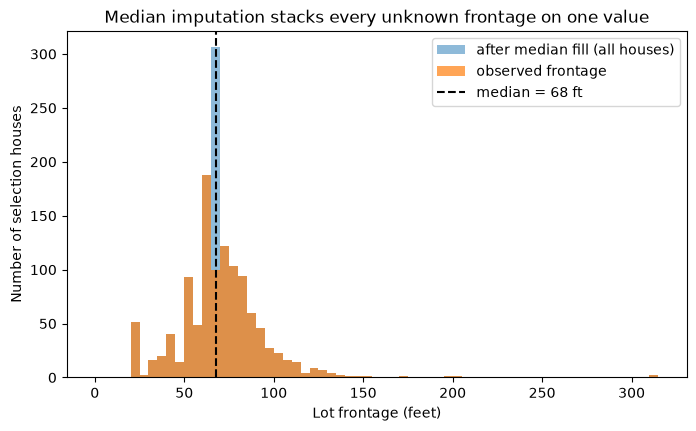

In [7]:
# Q1.3: one overall median, learned from the observed selection frontages only.
median_imputer = FrontageImputer("median").fit(X_selection)
median_filled = median_imputer.transform(X_selection)
print(f"Replacement value: {median_imputer.median_:.1f} ft for {int(frontage_missing.sum())} houses")
print("Observed values unchanged:",
      bool((median_filled.loc[~frontage_missing, "Lot_Frontage"] == X_selection.loc[~frontage_missing, "Lot_Frontage"]).all()))

frontage_summary = pd.DataFrame(
    {
        "observed only": X_selection["Lot_Frontage"].dropna().describe(),
        "after median fill": median_filled["Lot_Frontage"].describe(),
    }
)
display(frontage_summary.round(1))
n_at_median = int(np.isclose(median_filled["Lot_Frontage"], median_imputer.median_).sum())
print(
    f"Houses with frontage exactly {median_imputer.median_:.0f} ft after the fill: "
    f"{n_at_median} of {len(median_filled)} ({n_at_median / len(median_filled):.1%})"
)

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(0, 320, 5)
ax.hist(median_filled["Lot_Frontage"], bins=bins, alpha=0.5, label="after median fill (all houses)")
ax.hist(X_selection["Lot_Frontage"].dropna(), bins=bins, alpha=0.7, label="observed frontage")
ax.axvline(median_imputer.median_, color="black", ls="--", label=f"median = {median_imputer.median_:.0f} ft")
ax.set_xlabel("Lot frontage (feet)")
ax.set_ylabel("Number of selection houses")
ax.set_title("Median imputation stacks every unknown frontage on one value")
ax.legend()
plt.show()


In [8]:
grader.check("q1_3")

q1_3 results: All test cases passed!

**Written response — Q1.3**

The median rule, fitted on the 1,112 observed frontages, sets all 206 unknown values to 68 ft. It keeps every observed value and the center (median 68 ft; mean 69.2 to 69.0 ft) but distorts the spread: 229 of 1,318 selection houses (17.4%) now share exactly 68 ft, the standard deviation falls from 24.4 to 22.4 ft and the interquartile range narrows from 59–80 to 60–78 ft. It also ignores everything else we know: a large Clear Creek cul-de-sac lot and a small Northpark Villa townhouse lot both get 68 ft, although Q1.2 showed unknown frontage concentrates on larger lots in particular neighborhoods. The filled column therefore understates variability and weakens frontage's link to lot area and location.


## Q1.4. Use recorded characteristics for imputation

**4 points**

The median baseline ignores information we already have about each house. Street frontage may differ across neighborhoods and may be related to lot size, so these recorded characteristics could help us choose more plausible replacements. Comparing these approaches lets us investigate what additional information contributes before deciding whether the extra complexity is worthwhile.

**Task:** Fit and apply `FrontageImputer('neighborhood')` and `FrontageImputer('regression')`. The neighborhood rule uses an overall median when a fitting sample has no observed frontage for a neighborhood. The regression rule uses square-root lot area. Compare their replacement values with the median baseline, and assess whether their ranges and variation are plausible.

Note any neighborhoods with few or no observed frontages available to fit their replacement rule.

**Artifacts:** Replacement-value summaries for all three methods, a distribution plot, and a short comparison. Keep the method names for Q1.5, where each rule must be refitted within the relevant fold; do not reuse the rules fitted here on all selection rows.

**Constraints:** Fit only on observed frontage; exclude sale price; retain measurements actually observed.

,count,mean,std,min,25%,50%,75%,max,distinct values
median,206.0,68.0,0.0,68.0,68.0,68.0,68.0,68.0,1
neighborhood,206.0,71.2,9.5,24.0,64.5,70.0,75.0,94.5,17
regression,206.0,74.8,21.8,29.9,64.7,72.3,81.5,245.4,190


Observed frontage for reference: {'count': 1112.0, 'mean': 69.2, 'std': 24.4, 'min': 21.0, '25%': 59.0, '50%': 68.0, '75%': 80.0, 'max': 313.0}
Regression rule: frontage = 0.05 + 0.723 * sqrt(Lot_Area)
Neighborhoods with fewer than 5 observed frontages:


,houses,observed,unknown
Neighborhood,,,
Blueste,4,4,0
Green_Hills,2,0,2
Greens,4,3,1


Schema neighborhoods with no selection houses: []


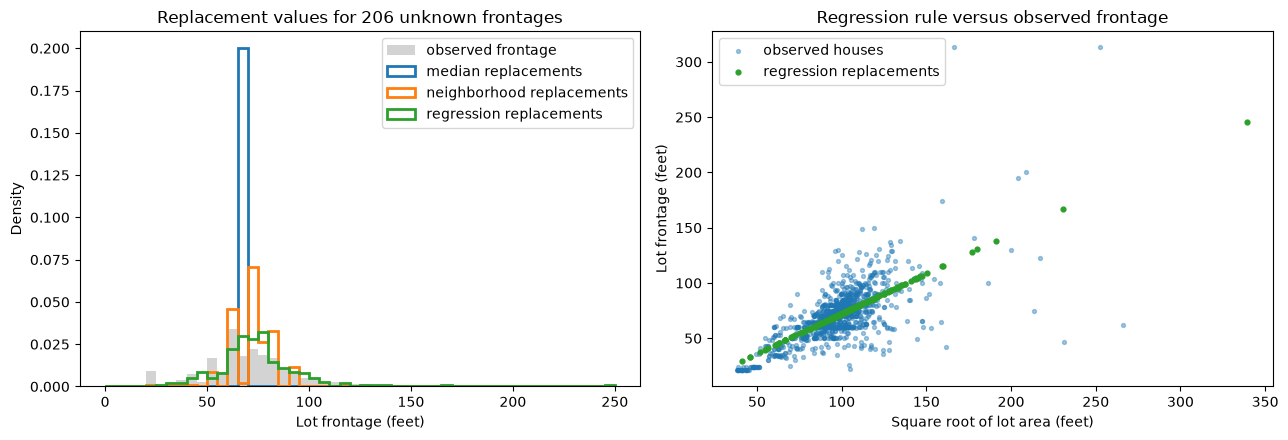

In [9]:
# Q1.4: conditional rules. Each is fitted on the selection rows for description only;
# Q1.5 refits them inside folds.
fitted_imputers = {m: FrontageImputer(m).fit(X_selection) for m in ["median", "neighborhood", "regression"]}
replacements = pd.DataFrame(
    {m: imp.transform(X_selection).loc[frontage_missing, "Lot_Frontage"] for m, imp in fitted_imputers.items()}
)
replacement_summary = replacements.describe().T
replacement_summary["distinct values"] = replacements.nunique()
display(replacement_summary.round(1))
observed_summary = X_selection["Lot_Frontage"].dropna().describe()
print("Observed frontage for reference:", observed_summary.round(1).to_dict())

reg = fitted_imputers["regression"].regression_
print(f"Regression rule: frontage = {reg.intercept_:.2f} + {reg.coef_[0]:.3f} * sqrt(Lot_Area)")

# Neighborhoods with little observed frontage to learn from.
observed_counts = (
    X_selection.assign(observed=X_selection.Lot_Frontage.notna())
    .groupby("Neighborhood")["observed"].agg(houses="size", observed="sum")
)
observed_counts["unknown"] = observed_counts["houses"] - observed_counts["observed"]
sparse = observed_counts[(observed_counts["observed"] < 5)]
print("Neighborhoods with fewer than 5 observed frontages:")
display(sparse)
in_schema = set(prep_template.categories[prep_template.categorical.index("Neighborhood")])
print("Schema neighborhoods with no selection houses:", sorted(in_schema - set(observed_counts.index)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.arange(0, 255, 5)
axes[0].hist(X_selection["Lot_Frontage"].dropna(), bins=bins, density=True, color="lightgray", label="observed frontage")
for m, color in zip(replacements, ["tab:blue", "tab:orange", "tab:green"]):
    axes[0].hist(replacements[m], bins=bins, density=True, histtype="step", lw=2, color=color, label=f"{m} replacements")
axes[0].set_xlabel("Lot frontage (feet)")
axes[0].set_ylabel("Density")
axes[0].set_title(f"Replacement values for {int(frontage_missing.sum())} unknown frontages")
axes[0].legend()
obs = X_selection.Lot_Frontage.notna()
axes[1].scatter(np.sqrt(X_selection.loc[obs, "Lot_Area"]), X_selection.loc[obs, "Lot_Frontage"], s=8, alpha=0.4, label="observed houses")
axes[1].scatter(np.sqrt(X_selection.loc[~obs, "Lot_Area"]), replacements["regression"], s=12, color="tab:green", label="regression replacements")
axes[1].set_xlabel("Square root of lot area (feet)")
axes[1].set_ylabel("Lot frontage (feet)")
axes[1].set_title("Regression rule versus observed frontage")
axes[1].legend()
plt.tight_layout()
plt.show()

**Written response — Q1.4**

Both conditional rules give house-specific replacements, unlike the single median value. The neighborhood rule takes 17 distinct values (24 ft in Northpark Villa to 94.5 ft in Veenker; SD 9.5 ft), far below the observed SD of 24.4 ft because every house in a neighborhood gets one value. The regression rule, frontage ≈ 0.05 + 0.723·√(lot area), takes 190 values (29.9 to 245.4 ft; SD 21.8 ft), close to the observed spread. Their means (71.2 and 74.8 ft) exceed the median rule's 68 ft, consistent with Q1.2: unknown frontage sits on larger lots.

The regression rule extrapolates at the extreme: the 115,149 sq ft Clear Creek lot gets 245 ft, where observed frontages scatter widely. The neighborhood rule suffers in sparse neighborhoods: Green Hills has no observed frontage, so its 2 unknown houses fall back to the overall median (68 ft); Greens has 3 observed and Blueste 4 (no unknowns). Replacements resting on 0–3 houses are unreliable, and inside CV folds these groups shrink further.

## Q1.5. Validate replacements and use the shared pipeline

**6 points**

The replacement distributions show whether an imputation method produces plausible values, but plausibility alone does not establish accuracy. Hiding measurements we actually know lets us compare replacements with their recorded values. When we then evaluate price predictions, we also need to consider when the imputer was fitted: held-out houses should not help determine the preprocessing used to predict them.

**Task:**
1. Restrict the reconstruction exercise to selection houses with observed frontage. Define `observed_positions` as their positional indices within `X_selection`. Use `fixed_folds(len(observed_positions), seed=109)` Each fold’s index arrays point into `observed_positions`; for example, its held-out houses are `X_selection.iloc[observed_positions[va]]`. In each fold, hide the held-out frontage, fit each `FrontageImputer` method on the remaining observed houses, and predict the hidden measurements. Use identical folds and hidden values for all three methods. Report mean absolute error and RMSE in feet, then justify your preferred rule.
2. On `selection_folds`, compare OLS from `reference_pipeline(prep_template)` under two procedures. First fill frontage using `FrontageImputer('neighborhood')` fitted once on all selection rows, then cross-validate on those filled predictors. Second cross-validate directly on `X_selection`, so the pipeline fits its imputer within each training fold. Keep the model and all other preprocessing the same. Record paired fold RMSEs in log-price units. For fold 0, count held-out observed frontage measurements that contributed to each procedure's imputer and compare replacements for the fold-0 held-out houses with unknown frontage.
3. Explain what held-out information affected each procedure and which evaluation matches prediction on new houses. For later Ames questions, use the supplied `shared_preprocessor` defined below.

**Artifacts:** `imputation_results`, with columns `fold`, `method`, `mae`, and `rmse`, using method labels `'median'`, `'neighborhood'`, and `'regression'`; `leakage_results`, with columns `fold`, `procedure`, and `rmse`, using procedure labels `impute_before_cv` and `impute_in_fold`; `replacement_comparison`, indexed by the IDs of the fold-0 held-out houses with unknown frontage with columns `before_cv` and `within_fold` for the two replacement values in feet; and your choice and leakage explanation.

**Constraints:** Use selection data only and exclude sale price from all imputers. The score difference may be small or favor either procedure; identify the information used regardless of the scores. Explain one limitation of hiding observed values as a proxy for genuinely missing frontage.

The shared preprocessing uses neighborhood medians, chosen in advance as a simple conditional rule with an overall-median fallback. It is not a claim that this method wins your reconstruction comparison. Your evaluation and justified choice are graded separately. The common pipeline prevents an earlier imputation error from affecting every later question, and it relearns replacements within each fitting fold rather than using a permanently imputed dataset.

In [10]:
# Supplied utility: prediction errors use the log-price scale in Ames.
def rmse(y, prediction):
    """Return root mean squared error in the same units as the response y."""
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(prediction)) ** 2)))


In [11]:
# Q1.5 part 1: hide known frontages and see how well each rule recovers them.
METHODS = ["median", "neighborhood", "regression"]
observed_positions = np.flatnonzero(X_selection["Lot_Frontage"].notna().to_numpy())
reconstruction_folds = fixed_folds(len(observed_positions), seed=109)
imputation_rows = []
for fold, (tr, va) in enumerate(reconstruction_folds):
    fit_rows = X_selection.iloc[observed_positions[tr]]
    held_out = X_selection.iloc[observed_positions[va]]
    truth = held_out["Lot_Frontage"].to_numpy()
    hidden = held_out.assign(Lot_Frontage=np.nan)  # same hidden values for every method
    for method in METHODS:
        guess = FrontageImputer(method).fit(fit_rows).transform(hidden)["Lot_Frontage"].to_numpy()
        error = guess - truth
        imputation_rows.append(
            {"fold": fold, "method": method,
             "mae": float(np.mean(np.abs(error))), "rmse": float(np.sqrt(np.mean(error**2)))}
        )
imputation_results = pd.DataFrame(imputation_rows)
display(imputation_results.groupby("method")[["mae", "rmse"]].agg(["mean", "std"]).round(2))
display(imputation_results.pivot(index="fold", columns="method", values="rmse").round(2))

# Q1.5 part 2: imputer fitted once on all selection rows, versus refitted in each fold.
prefilled = FrontageImputer("neighborhood").fit(X_selection).transform(X_selection)
leakage_rows = []
fold_pipelines = {}
for fold, (tr, va) in enumerate(selection_folds):
    for procedure, x in [("impute_before_cv", prefilled), ("impute_in_fold", X_selection)]:
        pipe = reference_pipeline(prep_template).fit(x.iloc[tr], y_selection[tr])
        leakage_rows.append(
            {"fold": fold, "procedure": procedure, "rmse": rmse(y_selection[va], pipe.predict(x.iloc[va]))}
        )
        fold_pipelines[(fold, procedure)] = pipe
leakage_results = pd.DataFrame(leakage_rows)
leakage_wide = leakage_results.pivot(index="fold", columns="procedure", values="rmse")
leakage_wide["difference (before - in fold)"] = leakage_wide["impute_before_cv"] - leakage_wide["impute_in_fold"]
display(leakage_wide.round(5))
print("Mean fold RMSE (log price):", leakage_results.groupby("procedure")["rmse"].mean().round(5).to_dict())

# Fold 0: which held-out frontages reached each imputer, and what it filled in.
tr0, va0 = selection_folds[0]
held_out0 = X_selection.iloc[va0]
observed_held_out0 = int(held_out0["Lot_Frontage"].notna().sum())
print(f"Fold 0 held-out houses: {len(va0)}; with observed frontage: {observed_held_out0}")
print(f"  impute_before_cv: imputer used {observed_held_out0} held-out observed frontages "
      f"(all {int(X_selection.Lot_Frontage.notna().sum())} observed selection frontages)")
within_imputer = fold_pipelines[(0, "impute_in_fold")].named_steps["prep"].frontage_
print(f"  impute_in_fold: imputer used {len(set(tr0) & set(va0))} held-out observed frontages "
      f"({int(X_selection.iloc[tr0].Lot_Frontage.notna().sum())} training-fold frontages)")
unknown_ids = held_out0.index[held_out0["Lot_Frontage"].isna()]
replacement_comparison = pd.DataFrame(
    {
        "before_cv": prefilled.loc[unknown_ids, "Lot_Frontage"],
        "within_fold": within_imputer.transform(X_selection.loc[unknown_ids])["Lot_Frontage"],
    },
    index=unknown_ids,
)
replacement_comparison.index.name = "row_id"
replacement_difference = replacement_comparison["before_cv"] - replacement_comparison["within_fold"]
print(f"Fold-0 held-out houses with unknown frontage: {len(unknown_ids)}; "
      f"replacements that differ: {int((replacement_difference.abs() > 1e-9).sum())}; "
      f"largest absolute difference: {replacement_difference.abs().max():.1f} ft")
display(replacement_comparison.assign(
    Neighborhood=X_selection.loc[unknown_ids, "Neighborhood"], difference=replacement_difference))

mae         rmse      
               mean   std   mean   std
method                                
median        16.66  1.06  24.28  2.70
neighborhood  12.34  1.10  21.26  2.73
regression    11.55  0.98  17.87  3.13

method,median,neighborhood,regression
fold,,,
0,21.87,19.13,15.16
1,28.01,25.43,17.36
2,26.09,22.52,19.56
3,23.51,20.29,22.35
4,21.91,18.93,14.94


procedure,impute_before_cv,impute_in_fold,difference (before - in fold)
fold,,,
0,0.20360,0.20360,-0.00000
1,0.20561,0.20556,0.00005
2,0.29461,0.29504,-0.00043
3,0.26959,0.26958,0.00001
4,0.23542,0.23536,0.00006


Mean fold RMSE (log price): {'impute_before_cv': 0.24177, 'impute_in_fold': 0.24183}
Fold 0 held-out houses: 264; with observed frontage: 225
  impute_before_cv: imputer used 225 held-out observed frontages (all 1112 observed selection frontages)
  impute_in_fold: imputer used 0 held-out observed frontages (887 training-fold frontages)
Fold-0 held-out houses with unknown frontage: 39; replacements that differ: 25; largest absolute difference: 3.0 ft


,before_cv,within_fold,Neighborhood,difference
row_id,,,,
2894,81.5,83.0,Timberland,-1.5
391,80.0,80.0,Northwest_Ames,0.0
312,73.0,74.0,Mitchell,-1.0
2723,70.0,71.0,Sawyer,-1.0
2725,80.0,80.0,Clear_Creek,0.0
2512,71.0,68.0,Somerset,3.0
1530,74.0,74.5,Crawford,-0.5
780,70.0,71.0,Sawyer,-1.0
2892,68.0,68.0,Green_Hills,0.0


In [12]:
# Supplied common checkpoint for subsequent Ames questions.
shared_preprocessor = clone(prep_template)


In [13]:
grader.check("q1_5")

q1_5 results: All test cases passed!

**Written response — Q1.5**

**Reconstruction.** On the same five folds, regression is most accurate: fold-mean MAE 11.5 ft and RMSE 17.9 ft, clearly ahead of the median rule (16.7 and 24.3 ft) but only 0.8 ft MAE ahead of the neighborhood rule (12.3 and 21.3 ft). It has the lowest RMSE in 4 of 5 folds (fold 3 favors the neighborhood rule, 20.3 against 22.4 ft). We prefer it because lot area tracks frontage better than neighborhood does and gives each house its own value; its weakness is extrapolation for very large lots (Q1.4). The shared pipeline's neighborhood medians were fixed in advance and are not the most accurate rule here.

**Leakage.** In `impute_before_cv` the imputer saw all 1,112 observed selection frontages, so in fold 0 the 225 held-out houses with observed frontage helped set the medians that fill the unknown houses; in `impute_in_fold` it saw only the 887 training-fold frontages. The leak is small here (it involves predictors, not prices, and only 206 of 1,318 houses are imputed): 25 of the 39 fold-0 unknown replacements differ, by at most 3 ft (Somerset: 71 against 68 ft), and mean fold RMSE is 0.24177 for `impute_before_cv` against 0.24183 for `impute_in_fold` (no fold differs by 0.0005 or more). Only `impute_in_fold` matches prediction for new houses, whose frontage cannot have shaped the imputer.

**Limitation.** Hiding observed values makes them missing at random, but real unknown frontage is not (Q1.2), so these errors may understate those on the houses we actually impute.

# Part 2. Regularization

## Q2.1. Assess the supplied unregularized baseline

**3 points**

With missing measurements addressed, we can return to predicting log sale price. The supplied least-squares models provide a starting point without repeating the modeling exercises from Homework 2. Comparing their training and cross-validation errors helps us assess whether fitting the training houses closely translates into accurate predictions for houses not used in fitting, and whether regularization is worth investigating.

**Task:** Run the supplied baseline calculation. Compare training and CV log-price errors for the modest model and the model using all original predictors, including the fold-to-fold variation in `ols_fold_results`. Describe the observed difference between fitting the training houses and predicting held-out houses, and explain whether this evidence motivates trying regularization.

**Artifacts:** Compact prediction-error comparison and short motivation.

**Constraints:** Use the supplied code and partitions; you do not need to rebuild the Homework 2 baseline. Use original predictors without polynomial expansion. Base your explanation on the observed errors, rather than assuming that more predictors always produce harmful overfitting.

**Output names for the guided checks:** The supplied `baseline_comparison` table; add your interpretation.

The supplied modest model uses the 13 numeric predictors in `CORE`, plus `Neighborhood` and `Overall_Qual`. In `baseline_comparison`, `terms` counts encoded predictor columns and `rank` includes the intercept. A rank below `terms + 1` indicates linear dependence. Read the overall errors and the fold-to-fold variation in `ols_fold_results`; no additional baseline implementation is required.


**Supplied baseline calculation**

In [14]:
# Supplied baseline calculation; interpret the resulting tables in Q2.1.
def baseline_cv(template, x, y, folds, columns=None):
    """Compare training and held-out errors for a fixed OLS predictor design.

    Clone and fit preprocessing separately in each fold, so imputation and
    scaling use only that fold's training houses. `columns` optionally selects
    encoded predictor positions; None keeps all predictors. Return an overall
    summary and a table of fold errors. RMSE is on the log-price scale.
    """
    held_out_predictions = np.empty(len(y))
    fold_rows = []
    for fold, (train_positions, validation_positions) in enumerate(folds):
        preprocessing = clone(template).fit(x.iloc[train_positions])
        train_predictors = preprocessing.transform(x.iloc[train_positions])
        validation_predictors = preprocessing.transform(x.iloc[validation_positions])
        if columns is not None:
            train_predictors = train_predictors[:, columns]
            validation_predictors = validation_predictors[:, columns]
        # Add an intercept column to both designs, then fit only on training outcomes.
        train_design = np.column_stack(
            [np.ones(len(train_predictors)), train_predictors]
        )
        validation_design = np.column_stack(
            [np.ones(len(validation_predictors)), validation_predictors]
        )
        coefficients = np.linalg.lstsq(train_design, y[train_positions], rcond=1e-10)[0]
        held_out_predictions[validation_positions] = validation_design @ coefficients
        fold_rows.append(
            {
                "fold": fold,
                "train_rmse": rmse(y[train_positions], train_design @ coefficients),
                "cv_rmse": rmse(
                    y[validation_positions], validation_design @ coefficients
                ),
            }
        )

    # Refit on all selection houses to report the full-sample training error.
    preprocessing = clone(template).fit(x)
    predictors = preprocessing.transform(x)
    if columns is not None:
        predictors = predictors[:, columns]
    design = np.column_stack([np.ones(len(predictors)), predictors])
    coefficients = np.linalg.lstsq(design, y, rcond=1e-10)[0]
    summary = {
        "train_rmse": rmse(y, design @ coefficients),
        "cv_rmse": rmse(y, held_out_predictions),
        "terms": predictors.shape[1],
        "rank": np.linalg.matrix_rank(design),
    }
    return summary, pd.DataFrame(fold_rows)


# The smaller design reuses the familiar numeric predictors and two categorical inputs.
reference_prep = clone(shared_preprocessor).fit(X_selection)
feature_names = reference_prep.feature_names_
feature_sources = reference_prep.sources_
small_indices = np.array(
    [
        j
        for j, source in enumerate(feature_sources)
        if source in CORE + ["Neighborhood", "Overall_Qual"]
    ]
)
modest_summary, _ = baseline_cv(
    shared_preprocessor, X_selection, y_selection, selection_folds, small_indices
)
ols_summary, ols_fold_results = baseline_cv(
    shared_preprocessor, X_selection, y_selection, selection_folds
)
baseline_comparison = pd.DataFrame(
    [modest_summary, ols_summary], index=["modest OLS", "all-original OLS"]
)
display(baseline_comparison)
display(ols_fold_results)


,train_rmse,cv_rmse,terms,rank
modest OLS,0.150329,0.166752,48,49
all-original OLS,0.088413,0.279732,285,273


,fold,train_rmse,cv_rmse
0,0,0.085005,0.182490
1,1,0.088307,0.239442
2,2,0.075987,0.402850
3,3,0.081763,0.269579
4,4,0.082672,0.256095


In [15]:
grader.check("q2_1")

q2_1 results: All test cases passed!

**Written response — Q2.1**

| model | encoded terms | rank | train RMSE | CV RMSE |
|---|---:|---:|---:|---:|
| modest OLS (`CORE` + `Neighborhood` + `Overall_Qual`) | 48 | 49 | 0.150 | 0.167 |
| all-original OLS | 285 | 273 | 0.088 | 0.280 |

The modest model generalizes well: CV RMSE is only 0.016 above training RMSE. The all-original model fits the training houses far more closely (0.088 against 0.150) but predicts held-out houses much worse (0.280 against 0.167): its training RMSE is steady across folds (0.076–0.088) while held-out RMSE ranges from 0.182 to 0.403, with fold 2 far worse. Its rank is 273, not 286 (terms + intercept), so 13 coefficients are unidentified, and with about 1,050 training houses per fold many of the 285 coefficients rest on a few houses with rare levels, so they can fit noise and give extreme predictions for held-out houses with those levels.

This motivates regularization: the extra predictors are not useless, but unconstrained least squares estimates them with too much variance, and shrinkage can keep their information while reducing sensitivity to which houses are in the fit.

## Q2.2. Compare ridge and lasso

**8 points**

The baseline comparison gives us evidence about how the unregularized models generalize. Ridge and lasso offer two ways to constrain coefficient estimates, potentially reducing sensitivity to the fitting sample. Their coefficient trajectories show how those constraints operate, while cross-validation helps us assess which penalty strengths predict well; an improvement over least squares is something to investigate rather than assume.

**Task:** Tune ridge on `RIDGE_ALPHAS` and lasso on `LASSO_ALPHAS`, using `selection_folds` and `shared_preprocessor`. For each penalty, pool squared prediction errors over all held-out houses and divide by the number of houses; choose the penalty with the smallest pooled mean squared error. Report its square root as CV RMSE. Use this minimum-error rule whenever the guided Ames questions ask you to retune lasso. Compute coefficient paths on all selection rows, show the same eight features in both panels, and explain how you chose them. Plot both CV-error curves with their selected penalties marked.

**Artifacts:** Performance table, readable trajectory panels, CV-error curves, and interpretation.

**Constraints:** Use selection data and the supplied common folds and penalty grids. Fit preprocessing within each training fold. Display the same features in both coefficient-path panels and state their coefficient units. Ridge and lasso have different penalty scales, so equal numerical penalties are not equivalent. Report the observed comparison; neither method is required to outperform the other.

**Output names for the guided checks:** `regularization_comparison`, with rows `'OLS'` (the all-original-predictor baseline), `'ridge'`, and `'lasso'`, and columns `cv_rmse` and `alpha` (use `NaN` for the OLS penalty), plus the required plots. Save the fitted tuned models for Q2.3 and a reusable tuning routine for Q3.1 and Q3.8.


In [16]:
# Supplied penalty grids for the ridge/lasso comparison.
LASSO_ALPHAS = np.logspace(-0.5, -5, 27)
RIDGE_ALPHAS = np.logspace(-2, 5, 25)


Solver warnings during tuning: 0


,cv_rmse,alpha
OLS,0.279732,NaN
ridge,0.150751,4.216965
lasso,0.153196,0.001194


ridge: penalties with CV RMSE within 0.005 of the minimum span 1.1 to 16.2 (5 grid values)
lasso: penalties with CV RMSE within 0.005 of the minimum span 0.000361 to 0.00178 (5 grid values)
Nonzero lasso coefficients at the selected penalty: 90 of 285


Path features (largest |tuned lasso coefficient|):


,term,type,tuned lasso,tuned ridge
0,Overall_Qual_Poor,indicator (0/1),-0.3236,-0.3015
1,Overall_Qual_Excellent,indicator (0/1),0.1883,0.1570
2,Overall_Cond_Fair,indicator (0/1),-0.1496,-0.1858
3,Overall_Cond_Poor,indicator (0/1),-0.1082,-0.1567
4,Central_Air_Y,indicator (0/1),0.1081,0.0768
5,Overall_Qual_Very_Good,indicator (0/1),0.0994,0.0889
6,Gr_Liv_Area,numeric (per SD),0.0975,0.0583
7,Neighborhood_Crawford,indicator (0/1),0.0914,0.0867


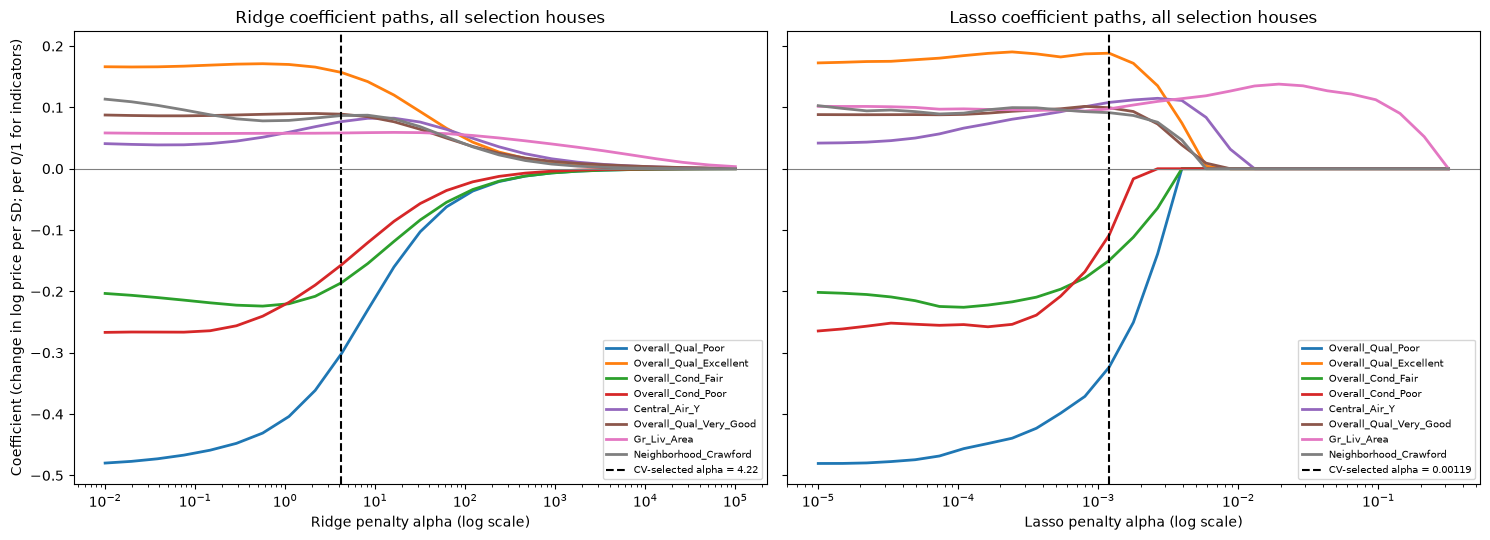

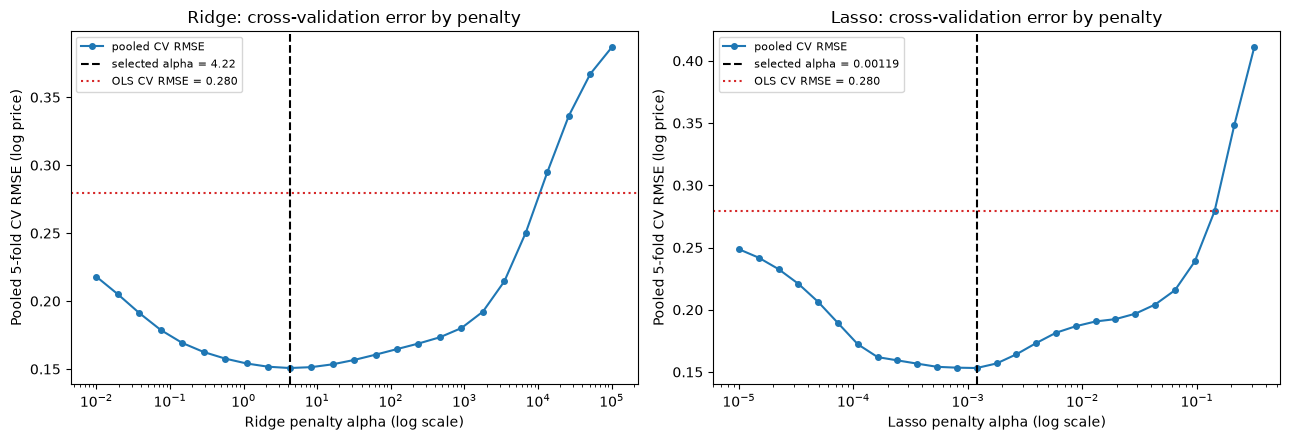

In [17]:
# Q2.2: one tuning routine for both penalties, reused in Q3.1 and Q3.8.
LASSO_SETTINGS = {"max_iter": 100_000, "tol": 1e-6}


def make_penalized(kind, alpha):
    """Return an unfitted ridge or lasso model with the course-wide solver settings."""
    if kind == "lasso":
        return Lasso(alpha=alpha, warm_start=True, **LASSO_SETTINGS)
    return Ridge(alpha=alpha)


def tune_penalty(kind, alphas, x, y, folds, template=None):
    """Pooled-CV tuning: refit preprocessing in each training fold, pool held-out squared errors.

    Returns the penalty with the smallest pooled MSE (sum of squared held-out errors
    divided by the number of held-out rows), its CV RMSE, and the whole MSE curve.
    """
    template = shared_preprocessor if template is None else template
    alphas = np.asarray(alphas, dtype=float)
    order = np.argsort(alphas)[::-1]  # large to small, so lasso can warm-start
    squared = np.zeros(len(alphas))
    held_out = 0
    for tr, va in folds:
        prep = clone(template).fit(x.iloc[tr])
        a_tr, a_va = prep.transform(x.iloc[tr]), prep.transform(x.iloc[va])
        model = make_penalized(kind, alphas[order[0]])
        for i in order:
            model.set_params(alpha=alphas[i])
            model.fit(a_tr, y[tr])
            squared[i] += np.sum((y[va] - model.predict(a_va)) ** 2)
        held_out += len(va)
    mse = squared / held_out
    best = int(np.argmin(mse))
    return {"alphas": alphas, "mse": mse, "alpha": float(alphas[best]), "cv_rmse": float(np.sqrt(mse[best]))}


with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    ridge_tuning = tune_penalty("ridge", RIDGE_ALPHAS, X_selection, y_selection, selection_folds)
    lasso_tuning = tune_penalty("lasso", LASSO_ALPHAS, X_selection, y_selection, selection_folds)
print("Solver warnings during tuning:", len(caught))

regularization_comparison = pd.DataFrame(
    {
        "cv_rmse": [ols_summary["cv_rmse"], ridge_tuning["cv_rmse"], lasso_tuning["cv_rmse"]],
        "alpha": [np.nan, ridge_tuning["alpha"], lasso_tuning["alpha"]],
    },
    index=["OLS", "ridge", "lasso"],
)
display(regularization_comparison)
for name, tuning in [("ridge", ridge_tuning), ("lasso", lasso_tuning)]:
    curve = np.sqrt(tuning["mse"])
    near = tuning["alphas"][curve <= curve.min() + 0.005]
    print(f"{name}: penalties with CV RMSE within 0.005 of the minimum span "
          f"{near.min():.3g} to {near.max():.3g} ({len(near)} grid values)")

# Tuned models refitted on all selection rows (kept for Q2.3).
selection_prep = clone(shared_preprocessor).fit(X_selection)
A_selection = selection_prep.transform(X_selection)
ridge_model = make_penalized("ridge", ridge_tuning["alpha"]).fit(A_selection, y_selection)
lasso_model = make_penalized("lasso", lasso_tuning["alpha"]).fit(A_selection, y_selection)
print("Nonzero lasso coefficients at the selected penalty:", int((np.abs(lasso_model.coef_) > 1e-8).sum()),
      "of", len(feature_names))

# Coefficient paths on all selection rows, over the supplied grids.
ridge_path = np.array([Ridge(alpha=a).fit(A_selection, y_selection).coef_ for a in RIDGE_ALPHAS])
path_model = make_penalized("lasso", LASSO_ALPHAS[0])
lasso_path_coefs = []
for a in LASSO_ALPHAS:  # the grid runs from large to small penalties
    path_model.set_params(alpha=a)
    lasso_path_coefs.append(path_model.fit(A_selection, y_selection).coef_.copy())
lasso_path_coefs = np.array(lasso_path_coefs)

# Show the eight features with the largest absolute coefficient in the tuned lasso.
path_features = np.argsort(-np.abs(lasso_model.coef_))[:8]
n_numeric = len(prep_template.numeric)
print("Path features (largest |tuned lasso coefficient|):")
display(pd.DataFrame({
    "term": [feature_names[j] for j in path_features],
    "type": ["numeric (per SD)" if j < n_numeric else "indicator (0/1)" for j in path_features],
    "tuned lasso": lasso_model.coef_[path_features],
    "tuned ridge": ridge_model.coef_[path_features],
}).round(4))

colors = plt.cm.tab10(np.arange(8))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, alphas, path, tuned, name in zip(
    axes,
    [RIDGE_ALPHAS, LASSO_ALPHAS],
    [ridge_path, lasso_path_coefs],
    [ridge_tuning["alpha"], lasso_tuning["alpha"]],
    ["Ridge", "Lasso"],
):
    for c, j in zip(colors, path_features):
        ax.plot(alphas, path[:, j], color=c, lw=2, label=feature_names[j])
    ax.axvline(tuned, color="black", ls="--", label=f"CV-selected alpha = {tuned:.3g}")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xscale("log")
    ax.set_xlabel(f"{name} penalty alpha (log scale)")
    ax.set_title(f"{name} coefficient paths, all selection houses")
    ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("Coefficient (change in log price per SD; per 0/1 for indicators)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, tuning, name in zip(axes, [ridge_tuning, lasso_tuning], ["Ridge", "Lasso"]):
    ax.plot(tuning["alphas"], np.sqrt(tuning["mse"]), marker="o", ms=4, label="pooled CV RMSE")
    ax.axvline(tuning["alpha"], color="black", ls="--", label=f"selected alpha = {tuning['alpha']:.3g}")
    ax.axhline(ols_summary["cv_rmse"], color="tab:red", ls=":", label=f"OLS CV RMSE = {ols_summary['cv_rmse']:.3f}")
    ax.set_xscale("log")
    ax.set_xlabel(f"{name} penalty alpha (log scale)")
    ax.set_ylabel("Pooled 5-fold CV RMSE (log price)")
    ax.set_title(f"{name}: cross-validation error by penalty")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [18]:
grader.check("q2_2")

q2_2 results: All test cases passed!

**Written response — Q2.2**

| model | selected α | pooled CV RMSE (log price) |
|---|---:|---:|
| all-original OLS | — | 0.280 |
| ridge | 4.22 | 0.151 |
| lasso | 0.00119 | 0.153 |

Both penalties nearly halve the all-original OLS error and beat the modest OLS (0.167). Ridge is lower by 0.002 on the pooled CV RMSE, and both curves are flat near the minimum: CV RMSE stays within 0.005 of its best for ridge α from 1.1 to 16 and lasso α from 3.6×10⁻⁴ to 1.8×10⁻³ (5 grid values each). We therefore do not call ridge clearly better. The α scales differ: scikit-learn's ridge penalizes the *sum* of squared errors plus α‖β‖², lasso the *mean* squared error over 2 plus α‖β‖₁.

**Path features.** Both panels show the same eight features, those with the largest absolute tuned-lasso coefficient, in log-price units per selection-sample SD (numeric) or per 0/1 (indicators). At the selected penalties the largest is `Overall_Qual_Poor` (−0.32 lasso, −0.30 ridge); `Gr_Liv_Area` is 0.098. Ridge shrinks the eight toward zero without setting them to zero. The lasso paths drive the indicator coefficients to zero as the penalty grows. The Q2.3 table prints that path for `Overall_Qual_Poor` and `Overall_Cond_Poor`.


## Q2.3. Examine the tuned lasso selection

**3 points**

The trajectory plots show that lasso can set some coefficients exactly to zero. After choosing a penalty by cross-validation, its fitted nonzero features describe which inputs this particular model retained. This gives us an interpretable starting point for the next section, where we will ask whether the same features would be selected if the fitting data were different.

**Task:** Use the CV-selected penalty to fit lasso once on all selection data. Report which encoded features have nonzero coefficients and which are zero. Relate two examples to the coefficient trajectories in Q2.2.

**Artifacts:** A coefficient table for all encoded features, with retained features flagged, counts of retained and zero features, and concise interpretation.

**Constraints:**  Selection unit is an individual encoded feature; nonzero does not establish significance or reproducibility.

**Output names for the guided checks:** `retained_terms`, with columns `term`, `coefficient`, and `nonzero`, and one row per column in `feature_names`. Use `abs(coefficient) > 1e-8` as the numerical nonzero rule.


In [19]:
# Q2.3: the tuned lasso refitted on all selection rows (fitted in Q2.2).
retained_terms = pd.DataFrame({"term": feature_names, "coefficient": lasso_model.coef_})
retained_terms["nonzero"] = retained_terms["coefficient"].abs() > 1e-8
print(f"Penalty alpha = {lasso_tuning['alpha']:.4g}: {int(retained_terms.nonzero.sum())} retained, "
      f"{int((~retained_terms.nonzero).sum())} set to zero, of {len(retained_terms)} encoded features.")
path_terms = ["Overall_Qual_Poor", "Overall_Cond_Poor"]
path_cols = [feature_names.index(term) for term in path_terms]
near_selected = (LASSO_ALPHAS >= lasso_tuning["alpha"]) & (LASSO_ALPHAS <= 0.01)
print("Lasso coefficients for two Q2.2 path features, from the selected penalty up to alpha = 0.01:")
display(
    pd.DataFrame(
        lasso_path_coefs[near_selected][:, path_cols],
        index=pd.Index(LASSO_ALPHAS[near_selected], name="alpha"),
        columns=path_terms,
    ).round(4)
)
with pd.option_context("display.max_rows", 400):
    display(retained_terms.assign(source=feature_sources)
            .sort_values("coefficient", key=np.abs, ascending=False).round(5))

by_source = retained_terms.assign(source=feature_sources).groupby("source", sort=False)["nonzero"].agg(retained="sum", features="size")
print("Retained encoded features by original predictor (predictors with any feature retained):")
display(by_source[by_source.retained > 0].sort_values("retained", ascending=False).T)
print("Original predictors with every encoded feature set to zero:",
      sorted(by_source.index[by_source.retained == 0]))


Penalty alpha = 0.001194: 90 retained, 195 set to zero, of 285 encoded features.
Lasso coefficients for two Q2.2 path features, from the selected penalty up to alpha = 0.01:


,Overall_Qual_Poor,Overall_Cond_Poor
alpha,,
0.008756,0.0000,0.0000
0.005878,-0.0000,-0.0000
0.003946,-0.0000,-0.0000
0.002649,-0.1390,-0.0000
0.001778,-0.2505,-0.0165
0.001194,-0.3236,-0.1082


,term,coefficient,nonzero,source
124,Overall_Qual_Poor,-0.32355,True,Overall_Qual
121,Overall_Qual_Excellent,0.18832,True,Overall_Qual
131,Overall_Cond_Fair,-0.14964,True,Overall_Cond
133,Overall_Cond_Poor,-0.10825,True,Overall_Cond
221,Central_Air_Y,0.10812,True,Central_Air
126,Overall_Qual_Very_Good,0.09942,True,Overall_Qual
11,Gr_Liv_Area,0.09751,True,Gr_Liv_Area
74,Neighborhood_Crawford,0.09137,True,Neighborhood
283,Sale_Condition_Normal,0.08260,True,Sale_Condition
85,Neighborhood_Northridge_Heights,0.08151,True,Neighborhood


Retained encoded features by original predictor (predictors with any feature retained):


source,Neighborhood,Overall_Qual,Overall_Cond,MS_SubClass,BsmtFin_Type_1,Exterior_1st,Bldg_Type,Land_Contour,Bsmt_Qual,Sale_Type,...,Exter_Qual,Exter_Cond,Central_Air,Heating_QC,Fireplace_Qu,Functional,Garage_Finish,Garage_Cond,Paved_Drive,Sale_Condition
retained,10,7,6,4,3,2,2,2,2,2,...,1,1,1,1,1,1,1,1,1,1
features,26,9,8,15,6,12,4,3,4,7,...,3,4,1,4,5,6,3,5,2,5


Original predictors with every encoded feature set to zero: ['Alley', 'BsmtFin_SF_2', 'BsmtFin_Type_2', 'Condition_2', 'Electrical', 'Fence', 'Foundation', 'Garage_Area', 'Garage_Qual', 'Garage_Type', 'Heating', 'House_Style', 'Land_Slope', 'Lot_Config', 'Mas_Vnr_Type', 'Misc_Feature', 'Pool_QC', 'Roof_Matl', 'Roof_Style', 'Second_Flr_SF', 'Street', 'Utilities']


In [20]:
grader.check("q2_3")

q2_3 results: All test cases passed!

**Written response — Q2.3**

At the CV-selected α = 0.00119 the lasso refitted on all selection houses keeps **90** of 285 encoded features and sets **195** to zero. The 90 include 30 numeric measurements (for example `Gr_Liv_Area`, `Year_Built`, `Total_Bsmt_SF`, `Garage_Cars`) and indicators from many categorical predictors (10 of 26 neighborhood, 7 of 9 `Overall_Qual` and 6 of 8 `Overall_Cond`). Twenty-two original predictors lose every feature, among them `Garage_Area`, `Second_Flr_SF`, `House_Style`, `Foundation` and `Lot_Config`.

The path table above follows two of those features from the selected penalty up to α = 0.01. `Overall_Cond_Poor` is −0.108 at the selected α, −0.016 at the next grid value (α = 0.00178), and zero from α = 0.00265. `Overall_Qual_Poor` is −0.324 at the selected α, still −0.139 at α = 0.00265, and zero from α = 0.00395. A slightly larger penalty on the flat part of the CV curve would drop the first and shrink the second.

A nonzero coefficient only means this fit, at this penalty, on these houses used the feature; it is neither significance nor reproducibility (Q3.1 tests the latter).


# Part 3. Stability, uncertainty, and interpretation

### Reusing saved bootstrap results

The supplied `cached_bootstrap_results` helper can save numerical bootstrap results and reload them on later runs. It checks the supplied data, settings, fitting-function code, listed code dependencies, and package versions before reuse. Keep plotting code separate from the computation so revising a figure does not require rerunning the fits.

**If you change your model or fitting implementation, delete the corresponding cache file or set `REFRESH_BOOTSTRAP_CACHE = True` and rerun.** Update the `implementation_version` setting as well. The checks cannot discover every external dependency of your code. Pass all fitting settings and relevant dependencies; do not rely on the presence of a saved file alone. After refreshing, set the flag back to `False` to permit reuse.

A fresh run still performs all required bootstrap fits. Cached results must come from your own current implementation. The autograder must be able to run without a preexisting cache.

Run `help(cached_bootstrap_results)` for the full interface. Pass a no-argument computation function, `cache_path`, the input `X` and `y`, a `settings` dictionary, and any fitting-function `dependencies`; `force=True` requests a fresh computation. Include a string `implementation_version` in `settings`. Use numeric values, strings, lists, dictionaries, or arrays for settings, rather than fitted model objects. The computation must return a dictionary of numerical or string arrays.


## Q3.1. Assess selection stability

**7 points**

The tuned lasso retained a particular set of features, but those choices were learned from one sample of houses. Another sample could lead to a different penalty and a different subset. Repeating both tuning and fitting on bootstrap samples lets us investigate the reproducibility of the selection procedure we actually used, rather than treating the original penalty as known.

**Task:** Bootstrap selection houses and retune by CV within each resample, then record feature selection frequencies. Apply the staff-specified stability/support rule to freeze an estimable subset. Explain why retuning assesses the entire selection procedure.

**Artifacts:** Frequency bars/table and frozen encoded-feature list.

**Constraints:** Use the supplied CV helper to keep every copy of a resampled house in the same fold. Refit preprocessing within each fitting fold and compare the same encoded features across resamples. Use the supplied 80% selection-frequency threshold and support checkpoint. Do not use inference outcomes to choose features. The frequency threshold is a selection rule, not a significance level.

Repeated selection does not guarantee adequate support in independent inference rows. A very rare predictor value can disappear from bootstrap fitting samples, leaving its coefficient unidentified. The supplied predictor-only support/rank helper reports exclusions and freezes an estimable design. Exclusion does not establish no association or no predictive value.


**Output names for the guided checks:** `selection_bootstrap_results`, with one row per bootstrap and columns `replicate`, `alpha`, and `nonzero` (the number of nonzero coefficients in that refit); `selection_frequencies`, an array in `feature_names` order; `frozen_indices`, the retained column indices; and the exclusion report, with an explanation of any exclusions. Save the penalties and counts now: Q3.2 reuses them without another bootstrap run.

Use `B_SELECTION` draws from `np.random.default_rng(SELECTION_BOOTSTRAP_SEED)`. For draw `b`, pass `selection_ids[idx]` to `bootstrap_folds(..., seed=109+b)`, retune with the Q2.2 rule, and refit on that entire resample. Record nonzero coefficients using the Q2.3 numerical rule. The supplied category schema keeps column order fixed. Candidates have frequencies at least `STABILITY_CUTOFF`. Call `support_checkpoint(shared_preprocessor, X_inference, candidates, selection_frequencies, MIN_SUPPORT)` to obtain `frozen_indices` and its report. The helper excludes inadequate predictor support or linear dependence. This list is frozen: later inference results must not change it.


In [21]:
# Supplied settings for retuned lasso selection stability.
B_SELECTION = 100
SELECTION_BOOTSTRAP_SEED = 2109
STABILITY_CUTOFF = 0.80
MIN_SUPPORT = 10
# Refresh after changing the fitting implementation; see the cache instructions above.
REFRESH_BOOTSTRAP_CACHE = False


Saved fresh bootstrap results to cache.
71 encoded features selected in at least 80% of 100 resamples.
Frozen design: 68 encoded features.


,term,frequency,nonmodal_support,decision
19,Overall_Qual_Poor,1.00,2,inadequate predictor support
41,Pool_Area,0.96,1,inadequate predictor support
69,Overall_Cond_Poor,0.80,3,inadequate predictor support


Excluded candidates: ['Overall_Qual_Poor', 'Pool_Area', 'Overall_Cond_Poor']
Frozen encoded features: ['Bldg_Type_Twnhs', 'Bsmt_Full_Bath', 'Central_Air_Y', 'Condition_1_Norm', 'Enclosed_Porch', 'Fireplaces', 'Full_Bath', 'Garage_Cars', 'Gr_Liv_Area', 'Heating_QC_Typical', 'MS_SubClass_Two_Story_1945_and_Older', 'Neighborhood_Crawford', 'Neighborhood_Edwards', 'Neighborhood_Northridge_Heights', 'Overall_Cond_Fair', 'Overall_Cond_Good', 'Overall_Qual_Below_Average', 'Overall_Qual_Excellent', 'Overall_Qual_Good', 'Overall_Qual_Very_Good', 'Sale_Condition_Normal', 'Screen_Porch', 'Total_Bsmt_SF', 'Wood_Deck_SF', 'Year_Built', 'Year_Remod_Add', 'Year_Sold', 'BsmtFin_Type_1_GLQ', 'Bsmt_Exposure_Gd', 'BsmtFin_Type_1_Unf', 'Functional_Typ', 'Kitchen_AbvGr', 'Kitchen_Qual_Typical', 'Latitude', 'Open_Porch_SF', 'Bldg_Type_OneFam', 'Land_Contour_HLS', 'Longitude', 'Bsmt_Unf_SF', 'Exterior_1st_BrkFace', 'Exter_Qual_Typical', 'MS_SubClass_One_Story_1945_and_Older', 'Overall_Cond_Average', 'Overall

,features
0,20
"(0, 0.2]",78
"(0.2, 0.5]",81
"(0.5, 0.8)",35
"[0.8, 1]",71


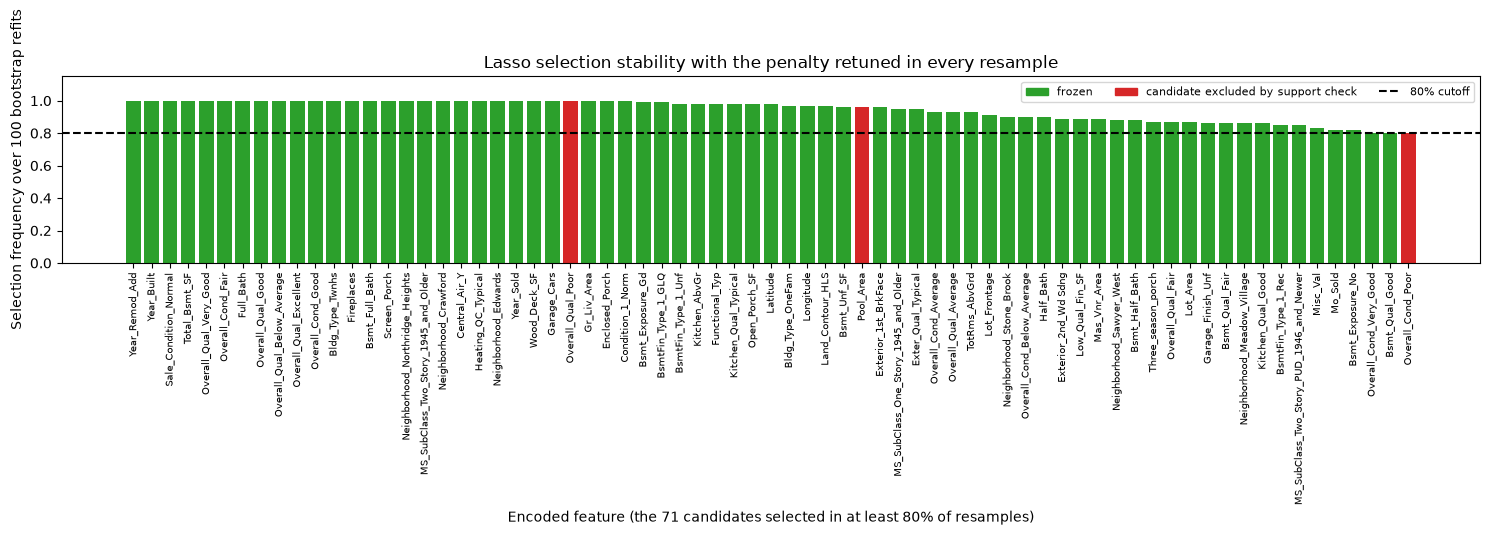

In [22]:
# Q3.1: bootstrap the whole lasso procedure (resample, retune by grouped CV, refit).
NONZERO_TOL = 1e-8


def selection_bootstrap():
    """Return per-replicate penalties, nonzero counts and the selected-feature matrix."""
    rng = np.random.default_rng(SELECTION_BOOTSTRAP_SEED)
    n = len(X_selection)
    alphas = np.empty(B_SELECTION)
    nonzero = np.empty(B_SELECTION, dtype=int)
    selected = np.zeros((B_SELECTION, len(feature_names)), dtype=bool)
    for b in range(B_SELECTION):
        idx = rng.integers(0, n, size=n)
        x_b, y_b = X_selection.iloc[idx], y_selection[idx]
        # Copies of the same house always share a fold.
        folds_b = bootstrap_folds(selection_ids[idx], seed=109 + b)
        tuning_b = tune_penalty("lasso", LASSO_ALPHAS, x_b, y_b, folds_b)
        prep_b = clone(shared_preprocessor).fit(x_b)
        model_b = make_penalized("lasso", tuning_b["alpha"]).fit(prep_b.transform(x_b), y_b)
        alphas[b] = tuning_b["alpha"]
        selected[b] = np.abs(model_b.coef_) > NONZERO_TOL
        nonzero[b] = selected[b].sum()
    return {"alpha": alphas, "nonzero": nonzero, "selected": selected}


selection_cache = cached_bootstrap_results(
    selection_bootstrap,
    cache_path="cache/q3_1_selection_bootstrap.npz",
    X=X_selection,
    y=y_selection,
    settings={
        "implementation_version": "q3_1-v1",
        "B_SELECTION": B_SELECTION,
        "SELECTION_BOOTSTRAP_SEED": SELECTION_BOOTSTRAP_SEED,
        "fold_seed_base": 109,
        "LASSO_ALPHAS": LASSO_ALPHAS,
        "LASSO_SETTINGS": LASSO_SETTINGS,
        "NONZERO_TOL": NONZERO_TOL,
        "preprocessor": repr(shared_preprocessor.get_params()),
    },
    dependencies=[tune_penalty, make_penalized, AmesPreprocessor, FrontageImputer, bootstrap_folds],
    force=REFRESH_BOOTSTRAP_CACHE,
)

selection_bootstrap_results = pd.DataFrame(
    {
        "replicate": np.arange(B_SELECTION),
        "alpha": selection_cache["alpha"],
        "nonzero": selection_cache["nonzero"].astype(int),
    }
)
selection_frequencies = selection_cache["selected"].mean(axis=0)
candidates = np.flatnonzero(selection_frequencies >= STABILITY_CUTOFF)
print(f"{len(candidates)} encoded features selected in at least {STABILITY_CUTOFF:.0%} of {B_SELECTION} resamples.")

# Predictor-only support and rank check on the inference rows (no outcomes used).
frozen_indices, support_report = support_checkpoint(
    shared_preprocessor, X_inference, candidates, selection_frequencies, MIN_SUPPORT
)
print(f"Frozen design: {len(frozen_indices)} encoded features.")
excluded = support_report[support_report.decision != "retained"]
display(excluded)
print("Excluded candidates:", "none" if excluded.empty else excluded["term"].tolist())
frozen_terms = [feature_names[j] for j in frozen_indices]
print("Frozen encoded features:", frozen_terms)

frequency_table = pd.DataFrame({"term": feature_names, "source": feature_sources, "frequency": selection_frequencies})
frequency_table["status"] = np.where(
    np.isin(np.arange(len(feature_names)), frozen_indices), "frozen",
    np.where(selection_frequencies >= STABILITY_CUTOFF, "candidate excluded by support check", "below cutoff"),
)
frequency_table = frequency_table.sort_values("frequency", ascending=False)
print("Distribution of selection frequencies over all", len(feature_names), "encoded features:")
display(pd.cut(selection_frequencies, [-0.001, 0, 0.2, 0.5, 0.8 - 1e-9, 1.0],
               labels=["0", "(0, 0.2]", "(0.2, 0.5]", "(0.5, 0.8)", "[0.8, 1]"]).value_counts().sort_index().to_frame("features"))

shown = frequency_table[frequency_table["frequency"] >= STABILITY_CUTOFF]
color_map = {"frozen": "tab:green", "candidate excluded by support check": "tab:red", "below cutoff": "tab:gray"}
fig, ax = plt.subplots(figsize=(15, 5))
ax.bar(np.arange(len(shown)), shown["frequency"], color=shown["status"].map(color_map))
ax.axhline(STABILITY_CUTOFF, color="black", ls="--")
ax.set_ylim(0, 1.15)
ax.set_xticks(np.arange(len(shown)), shown["term"], rotation=90, fontsize=7)
ax.set_ylabel(f"Selection frequency over {B_SELECTION} bootstrap refits")
ax.set_xlabel(f"Encoded feature (the {len(shown)} candidates selected in at least {STABILITY_CUTOFF:.0%} of resamples)")
ax.set_title("Lasso selection stability with the penalty retuned in every resample")
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
ax.legend(handles=[Patch(color=c, label=l) for l, c in color_map.items() if l in set(shown["status"])]
          + [Line2D([], [], color="black", ls="--", label=f"{STABILITY_CUTOFF:.0%} cutoff")],
          fontsize=8, loc="upper right", ncol=3)
plt.tight_layout()
plt.show()

In [23]:
grader.check("q3_1")

q3_1 results: All test cases passed!

**Written response — Q3.1**

In each of 100 resamples of the 1,318 selection houses we retuned the lasso penalty with the Q2.2 pooled-MSE rule on `bootstrap_folds` folds (copies of a house stay together), then refitted on the whole resample. Frequencies are widely spread: 20 of 285 encoded features were never selected, 78 were selected in (0, 20%] of resamples, 81 in (20%, 50%], 35 in (50%, 80%) and **71 reached the 80% cutoff** (for example `Gr_Liv_Area`, `Total_Bsmt_SF`, `Year_Built`, the main `Overall_Qual` and `Overall_Cond` levels).

The predictor-only support check on the inference rows excluded 3 candidates for **inadequate support**: `Overall_Qual_Poor` (frequency 1.00; 2 inference houses), `Overall_Cond_Poor` (0.80; 3) and `Pool_Area` (0.96; 1 house with a pool). Their coefficients could not be estimated reliably, and bootstrap resamples could lose them entirely. This says only that the design cannot support inference on them, not that they are unrelated to price. The frozen design has **68 encoded features**, fixed before any inference outcome was used.

Retuning matters because the procedure we use chooses its penalty from the data; a fixed α would ignore the instability of tuning itself (the selected penalty ranges from 1.1×10⁻⁴ to 1.8×10⁻³, moving the number of selected features from about 70 to 199; Q3.2). Grouped folds are needed because copies of a house in both fitting and validation folds would reward memorizing houses and push the penalty too low. The 80% cutoff is a reproducibility rule, not a significance level.

## Q3.2. Examine penalty variability

**3 points**

Each bootstrap fit made a tuning decision as well as a selection decision. Variation in the selected penalties can help explain why features enter or leave the model, especially when the cross-validation error curve is nearly flat around its minimum. The recorded penalties therefore provide useful context for the selection frequencies, even when different penalties give similar predictive performance.

**Task:** Reuse recorded bootstrap penalties and selected-set sizes. Relate their distribution to the earlier CV-error curve and describe how flat the CV curve is near its minimum and what that implies.

**Artifacts:** A distribution plot of the selected penalties on a logarithmic axis, a comparison with the number of nonzero features, and a short explanation relating the observed variability to the CV-error curve.

**Constraints:** No extra bootstrap runs. Descriptive tuning variability is not a confidence interval for a uniquely true penalty. Do not automatically use the bootstrap-average penalty for final fitting.

**Output names for the guided checks:** Use the `alpha` column of `selection_bootstrap_results`.


,count,mean,std,min,10%,25%,50%,75%,90%,max
bootstrap selected alpha,100.0,0.000665,0.000413,0.000109,0.000242,0.000361,0.000538,0.000801,0.001194,0.001778


Full-sample selected alpha (Q2.2): 0.001194; distinct grid values chosen by bootstrap: 8


,size,mean,min,max
alpha,,,,
0.000109,1,199.0,199,199
0.000163,2,176.0,171,181
0.000242,18,160.9,148,184
0.000361,12,140.8,133,155
0.000538,30,125.2,112,135
0.000801,15,108.7,98,120
0.001194,17,89.6,80,101
0.001778,5,75.0,69,81


Correlation of log alpha with nonzero count: -0.978
Q2.2 CV RMSE within 0.002 of its minimum for alpha in [0.000538, 0.00119]; 62% of bootstrap penalties fall in that range.
Q2.2 CV RMSE within 0.005 of its minimum for alpha in [0.000361, 0.00178]; 79% of bootstrap penalties fall in that range.


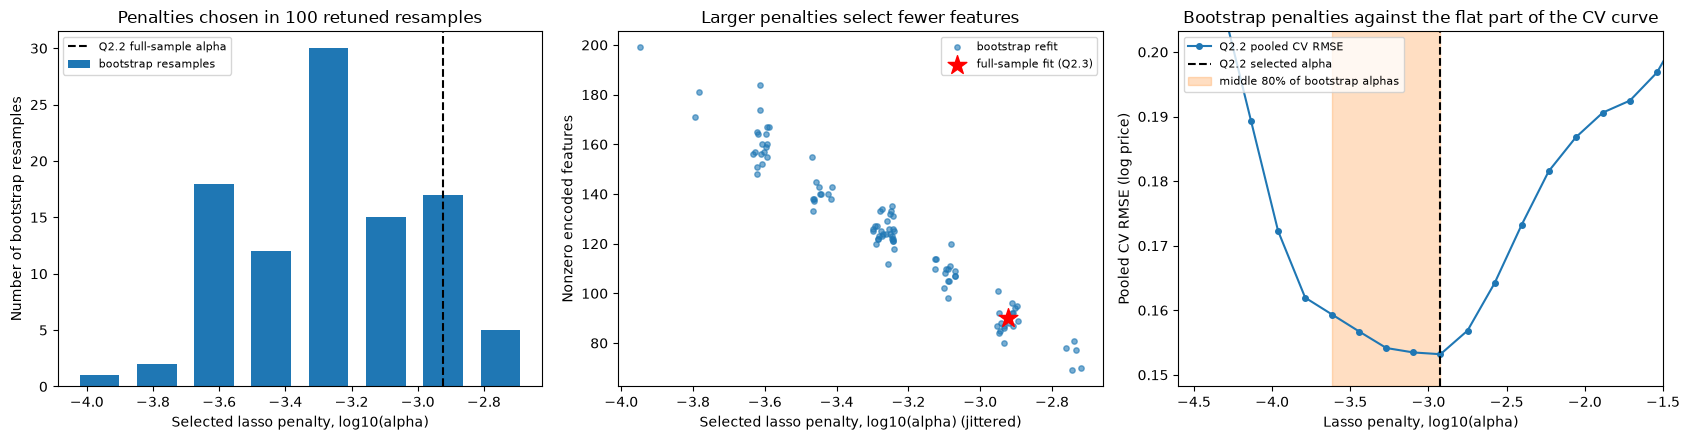

In [24]:
# Q3.2: tuning variability, reusing the Q3.1 penalties (no new fits).
alpha_counts = selection_bootstrap_results["alpha"].round(12).value_counts().sort_index()
alpha_summary = selection_bootstrap_results["alpha"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
display(alpha_summary.to_frame("bootstrap selected alpha").T)
print(f"Full-sample selected alpha (Q2.2): {lasso_tuning['alpha']:.4g}; "
      f"distinct grid values chosen by bootstrap: {len(alpha_counts)}")
display(selection_bootstrap_results.groupby("alpha")["nonzero"].agg(["size", "mean", "min", "max"]).round(1))
print("Correlation of log alpha with nonzero count:",
      round(np.corrcoef(np.log(selection_bootstrap_results.alpha), selection_bootstrap_results.nonzero)[0, 1], 3))

curve = np.sqrt(lasso_tuning["mse"])
for tol in [0.002, 0.005]:
    near = LASSO_ALPHAS[curve <= curve.min() + tol]
    share = selection_bootstrap_results["alpha"].between(near.min() - 1e-15, near.max() + 1e-15).mean()
    print(f"Q2.2 CV RMSE within {tol} of its minimum for alpha in [{near.min():.3g}, {near.max():.3g}]; "
          f"{share:.0%} of bootstrap penalties fall in that range.")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].bar(np.log10(alpha_counts.index), alpha_counts.values, width=0.12, color="tab:blue", label="bootstrap resamples")
axes[0].axvline(np.log10(lasso_tuning["alpha"]), color="black", ls="--", label="Q2.2 full-sample alpha")
axes[0].set_xlabel("Selected lasso penalty, log10(alpha)")
axes[0].set_ylabel("Number of bootstrap resamples")
axes[0].set_title(f"Penalties chosen in {B_SELECTION} retuned resamples")
axes[0].legend(fontsize=8)

jitter = np.random.default_rng(0).uniform(-0.03, 0.03, len(selection_bootstrap_results))
axes[1].scatter(np.log10(selection_bootstrap_results.alpha) + jitter, selection_bootstrap_results.nonzero, s=15, alpha=0.6, label="bootstrap refit")
axes[1].scatter(np.log10(lasso_tuning["alpha"]), int((np.abs(lasso_model.coef_) > NONZERO_TOL).sum()), color="red", marker="*", s=200, label="full-sample fit (Q2.3)")
axes[1].set_xlabel("Selected lasso penalty, log10(alpha) (jittered)")
axes[1].set_ylabel("Nonzero encoded features")
axes[1].set_title("Larger penalties select fewer features")
axes[1].legend(fontsize=8)

axes[2].plot(np.log10(LASSO_ALPHAS), curve, marker="o", ms=4, label="Q2.2 pooled CV RMSE")
axes[2].axvline(np.log10(lasso_tuning["alpha"]), color="black", ls="--", label="Q2.2 selected alpha")
lo, hi = np.log10(selection_bootstrap_results.alpha.quantile([0.1, 0.9]))
axes[2].axvspan(lo, hi, color="tab:orange", alpha=0.25, label="middle 80% of bootstrap alphas")
axes[2].set_xlim(-4.6, -1.5)
axes[2].set_ylim(curve.min() - 0.005, curve.min() + 0.05)
axes[2].set_xlabel("Lasso penalty, log10(alpha)")
axes[2].set_ylabel("Pooled CV RMSE (log price)")
axes[2].set_title("Bootstrap penalties against the flat part of the CV curve")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [25]:
grader.check("q3_2")

q3_2 results: All test cases passed!

**Written response — Q3.2**

The 100 retuned resamples chose 8 different grid penalties, from 1.1×10⁻⁴ to 1.8×10⁻³ (median 5.4×10⁻⁴, below the full-sample 1.19×10⁻³; only 22 chose the full-sample value or larger). The penalty almost fixes the number of features kept (correlation of log α with the nonzero count −0.98): about 75 at 1.8×10⁻³, 125 at 5.4×10⁻⁴ and 199 at 1.1×10⁻⁴.

This matches the flat Q2.2 CV curve: pooled CV RMSE is within 0.002 of its minimum for α from 5.4×10⁻⁴ to 1.19×10⁻³ and within 0.005 from 3.6×10⁻⁴ to 1.8×10⁻³, a factor-of-five range holding 79% of the bootstrap penalties. Predictions are almost equally good across it while the selected sets differ greatly, so features that enter only at smaller penalties get intermediate frequencies, and the 80% rule keeps those that survive across most of the range. The spread describes unstable tuning, not a confidence interval for a "true" penalty, and we would not refit with the bootstrap-average penalty.

## Q3.3. Quantify coefficient uncertainty

**6 points**

A feature can be selected frequently without its coefficient being estimated precisely. We now move from reproducibility of selection to uncertainty about the size and direction of the retained associations. Because prices in the selection sample helped determine which features survived, the independent inference sample gives us fresh outcomes for estimating the frozen model and assessing its coefficient uncertainty.

**Task:** Fit OLS with the frozen features on the independent inference rows and bootstrap those coefficient estimates. Express numeric effects per one selection-data standard deviation throughout the analysis, even when each bootstrap fitting sample has its own scaler. Leave encoded indicator effects in their 0/1 units. Use the supplied preprocessing and fitting helpers.

**Artifacts:** A table for every frozen feature containing its coefficient estimate, bootstrap mean, standard deviation, and 95% percentile interval; a coefficient-interval plot with zero marked; and histograms for two coefficients you choose, with zero marked. Explain what these results support about the estimated associations.

**Constraints:** Use only the independent inference rows for coefficient estimation and its bootstrap. Apply the supplied support and rank checks, and state the assumptions of the imputation and regression procedure. These intervals describe this independent fit; they do not automatically apply to the later model refitted on all training rows.

In Section 5 the predictors were prescribed before coefficient analysis. Here they were selected using prices, so using the same outcomes for ordinary fixed-model intervals would ignore the selection step. Reserving independent inference outcomes addresses that reuse; it does not remove the imputation and regression assumptions.

When only some indicators from a categorical predictor are retained, an included indicator compares that level with the levels whose indicators were omitted, collectively. For example, retaining only one neighborhood indicator compares that neighborhood with the other neighborhoods, rather than with the original encoding reference alone. Other included predictors also enter the comparison.


**Output names for the guided checks:** `coefficient_summary`, one row per frozen feature with columns `term`, `coefficient` (the independent-fit estimate), `mean`, `sd`, `lower`, and `upper`, and `coefficient_draws`, one row per bootstrap.

Use `B_COEFFICIENT` resamples with `INFERENCE_BOOTSTRAP_SEED`, and save their positional index arrays as `bootstrap_indices`. Refit preprocessing on each sample. The supplied cell below defines `reference_sd` in the numeric-column order. For each retained numeric column `j`, multiply the fitted coefficient by `reference_sd[j] / fitted_prep.scaler_.scale_[j]`; use a multiplier of one for indicators. Apply the same conversion to the independent-fit point estimate. You may use `bootstrap_coefficient_maps(shared_preprocessor, X_inference, frozen_indices, reference_sd, bootstrap_indices)` to construct `coefficient_operators`; `coefficient_operators @ y_inference` gives the bootstrap coefficients. Keep those maps for Q3.6. Create the coefficient-interval plot yourself: show point estimates and their 95% bootstrap percentile intervals, label the predictors, and include a zero reference line. Use a descriptive title, a labeled effect axis, and a legend distinguishing the estimates from the intervals. If displaying a subset for readability, state how you chose it; the table must still include every frozen feature.

`checked_ols(shared_preprocessor, X_inference, y_inference, frozen_indices)` returns the fitted preprocessing, checked design, coefficients including the intercept, residuals, and residual standard error. The returned dictionary uses keys `prep`, `design`, `coef`, `residuals`, and `sigma`.

With `evaluation=`, `checked_ols` also returns `prediction` and `evaluation_design` for those held-out rows.


In [26]:
# Supplied settings for coefficient uncertainty on the inference sample.
B_COEFFICIENT = 300
INFERENCE_BOOTSTRAP_SEED = 3109
# Express numeric coefficients per selection-sample SD; keep indicators on their 0/1 scale.
reference_sd = (
    X_selection[prep_template.numeric].std(ddof=0).fillna(1).replace(0, 1).to_numpy()
)


Inference fit: n = 879, design columns = 69, residual SE = 0.1410 log price


,term,coefficient,mean,sd,lower,upper,units,interval_excludes_zero
0,Bldg_Type_Twnhs,-0.0540,-0.0510,0.0251,-0.1014,-0.0037,indicator 0/1,True
1,Bsmt_Full_Bath,0.0346,0.0309,0.0085,0.0148,0.0480,per selection SD,True
2,Central_Air_Y,0.1019,0.1016,0.0477,0.0207,0.2032,indicator 0/1,True
3,Condition_1_Norm,0.0377,0.0364,0.0150,0.0033,0.0645,indicator 0/1,True
4,Enclosed_Porch,0.0018,0.0021,0.0076,-0.0127,0.0157,per selection SD,False
5,Fireplaces,0.0353,0.0333,0.0067,0.0206,0.0462,per selection SD,True
6,Full_Bath,0.0152,0.0123,0.0105,-0.0068,0.0335,per selection SD,False
7,Garage_Cars,0.0378,0.0366,0.0075,0.0218,0.0506,per selection SD,True
8,Gr_Liv_Area,0.1399,0.1441,0.0182,0.1078,0.1788,per selection SD,True
9,Heating_QC_Typical,-0.0025,-0.0041,0.0133,-0.0272,0.0210,indicator 0/1,False


29 of 68 95% bootstrap percentile intervals exclude zero.


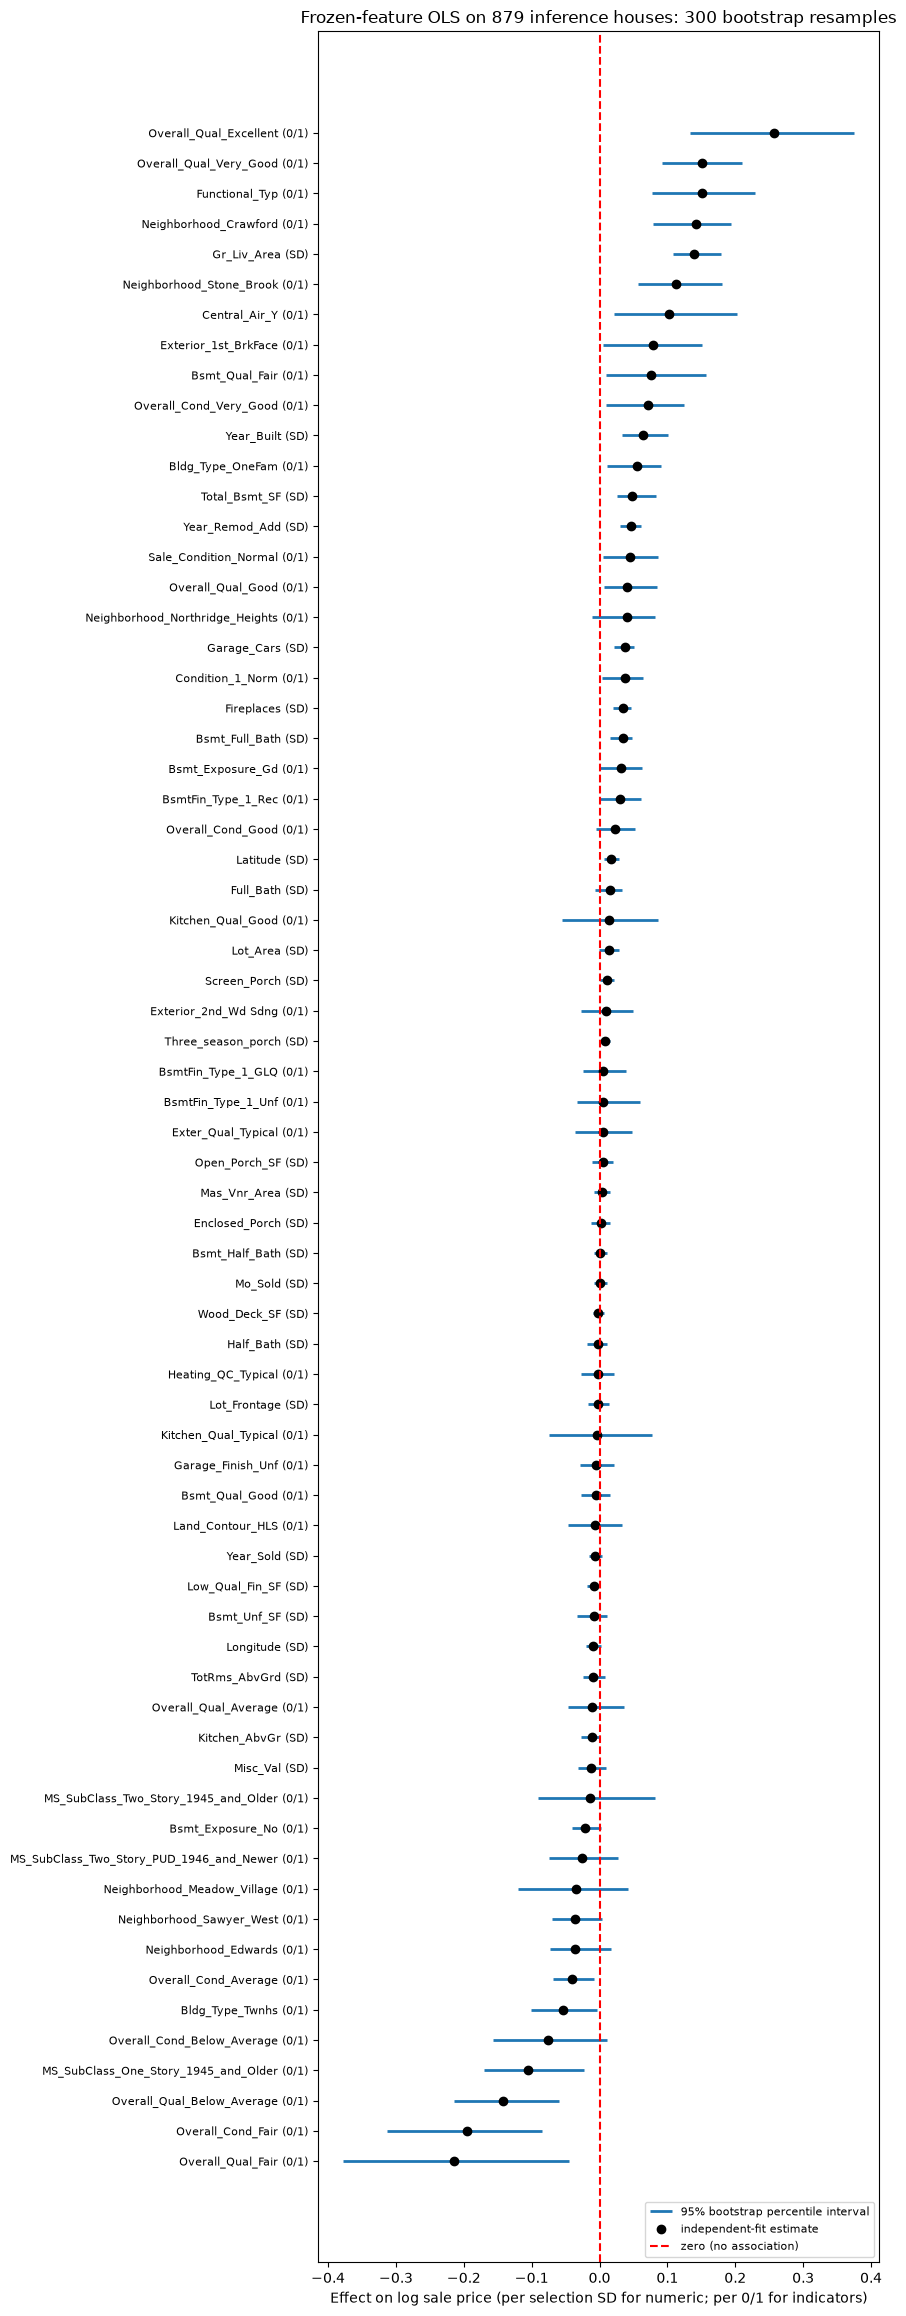

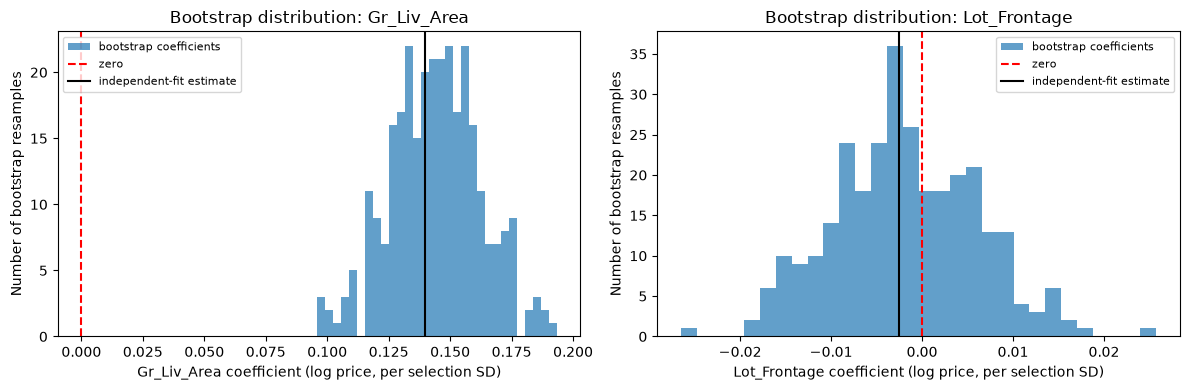

In [27]:
# Q3.3: OLS on the frozen features, fitted and bootstrapped on the independent inference rows.
rng_coef = np.random.default_rng(INFERENCE_BOOTSTRAP_SEED)
n_inference = len(X_inference)
bootstrap_indices = rng_coef.integers(0, n_inference, size=(B_COEFFICIENT, n_inference))
# Each map refits preprocessing on its resample and rescales numeric effects to reference_sd units.
coefficient_operators = bootstrap_coefficient_maps(
    shared_preprocessor, X_inference, frozen_indices, reference_sd, bootstrap_indices
)
coefficient_draws = coefficient_operators @ y_inference  # (B_COEFFICIENT, number of frozen features)

inference_fit = checked_ols(shared_preprocessor, X_inference, y_inference, frozen_indices)
n_numeric = len(prep_template.numeric)
reference_multiplier = np.array(
    [reference_sd[j] / inference_fit["prep"].scaler_.scale_[j] if j < n_numeric else 1.0 for j in frozen_indices]
)
inference_estimate = inference_fit["coef"][1:] * reference_multiplier

coefficient_summary = pd.DataFrame(
    {
        "term": frozen_terms,
        "coefficient": inference_estimate,
        "mean": coefficient_draws.mean(axis=0),
        "sd": coefficient_draws.std(axis=0, ddof=1),
        "lower": np.percentile(coefficient_draws, 2.5, axis=0),
        "upper": np.percentile(coefficient_draws, 97.5, axis=0),
    }
)
coefficient_summary["units"] = ["per selection SD" if j < n_numeric else "indicator 0/1" for j in frozen_indices]
coefficient_summary["interval_excludes_zero"] = (coefficient_summary.lower > 0) | (coefficient_summary.upper < 0)
print(f"Inference fit: n = {n_inference}, design columns = {inference_fit['design'].shape[1]}, "
      f"residual SE = {inference_fit['sigma']:.4f} log price")
with pd.option_context("display.max_rows", 200, "display.width", 200):
    display(coefficient_summary.round(4))
print(f"{int(coefficient_summary.interval_excludes_zero.sum())} of {len(coefficient_summary)} "
      "95% bootstrap percentile intervals exclude zero.")

order = np.argsort(coefficient_summary["coefficient"].to_numpy())
ypos = np.arange(len(order))
cs = coefficient_summary.iloc[order]
fig, ax = plt.subplots(figsize=(9, 0.32 * len(order) + 1.5))
ax.hlines(ypos, cs["lower"], cs["upper"], color="tab:blue", lw=2, label="95% bootstrap percentile interval")
ax.plot(cs["coefficient"], ypos, "o", color="black", label="independent-fit estimate")
ax.axvline(0, color="red", ls="--", label="zero (no association)")
ax.set_yticks(ypos, [f"{t} ({'SD' if u.startswith('per') else '0/1'})" for t, u in zip(cs["term"], cs["units"])], fontsize=8)
ax.set_xlabel("Effect on log sale price (per selection SD for numeric; per 0/1 for indicators)")
ax.set_title(f"Frozen-feature OLS on {n_inference} inference houses: {B_COEFFICIENT} bootstrap resamples")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

hist_terms = ["Gr_Liv_Area", "Lot_Frontage"]  # one clearly nonzero, one straddling zero
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, term in zip(axes, hist_terms):
    k = frozen_terms.index(term)
    ax.hist(coefficient_draws[:, k], bins=30, color="tab:blue", alpha=0.7, label="bootstrap coefficients")
    ax.axvline(0, color="red", ls="--", label="zero")
    ax.axvline(inference_estimate[k], color="black", label="independent-fit estimate")
    ax.set_xlabel(f"{term} coefficient (log price, {coefficient_summary.units[k]})")
    ax.set_ylabel("Number of bootstrap resamples")
    ax.set_title(f"Bootstrap distribution: {term}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [28]:
grader.check("q3_3")

q3_3 results: All test cases passed!

**Written response — Q3.3**

We fitted OLS with the 68 frozen features on the 879 independent inference houses (residual SE 0.141 log-price units) and bootstrapped it 300 times, refitting preprocessing each time, with numeric effects per selection-sample SD. **29 of the 68 percentile intervals (95%) exclude zero**, for example `Overall_Qual_Excellent` +0.257 [0.134, 0.375] (about 30% higher price than the omitted levels), `Overall_Cond_Fair` −0.196, `Neighborhood_Crawford` +0.142 and `Gr_Liv_Area` +0.140 [0.108, 0.179] per SD (about 15% higher price; its histogram lies entirely right of zero). Many frequently selected features have intervals around zero: `Lot_Frontage` (−0.003 [−0.016, 0.014]; its histogram straddles zero), `Mo_Sold`, `Enclosed_Porch`, `Wood_Deck_SF`. Indicators compared with a small omitted group are imprecise (`Kitchen_Qual_Typical` spans about ±0.08).

These results support conditional associations: after adjusting for the other 67 features, larger living area, newer or remodeled houses, higher quality and condition, and certain neighborhoods go with higher log price. The inference prices played no part in selection, so the intervals are a fair assessment; none of this is causal. An included indicator compares its level with all omitted levels together, and correlated predictors share credit (`TotRms_AbvGrd` is slightly negative given living area).

**Assumptions.** Houses are independent draws from one population (rows resampled as pairs); log price is linear in the frozen features; neighborhood-median frontage imputation, relearned per resample, is adequate only if missingness is close to MAR given neighborhood; the percentile bootstrap is a large-sample approximation, weakest for rare indicators. The intervals describe this independent fit, not the Q3.8 refit.

## Q3.4. Measure predictive importance

**5 points**

The coefficient intervals describe uncertainty about associations within the fitted model. They do not directly tell us how much the model relies on each input to make accurate predictions, particularly when predictors carry overlapping information. Measuring changes in held-out prediction error gives us a separate way to investigate that predictive reliance.

**Task:** Use CV within the inference data to evaluate OLS with the frozen features. Use `inference_folds`; for each fold, record the error on its held-out rows. Repeatedly shuffle each original predictor represented in the model among the held-out houses, pass the changed inputs through the fitted preprocessing, and calculate the increase in prediction loss. Keep the fitted model fixed during shuffling.

**Artifacts:** `importance_baselines`, with columns `fold`, `held_out_mse`, and `held_out_count`; `importance_summary`, indexed by original predictor, with columns `mean` and `std` for the MSE increase of log price; and distributions of those increases. MSE of log price is measured in squared log-price units.

**Constraints:** Shuffle an original categorical column as a whole, rather than shuffling its encoded indicators independently. Discuss how correlated inputs affect interpretation. Variation across shuffles does not capture all uncertainty from fitting the model. Do not use these inference diagnostics to revise the frozen predictor set.

**Output names for the guided checks:** `importance_summary`, `importance_baselines`, and `importance_repeats` (fold, source, replicate, degradation).

Use `N_SHUFFLES` perturbations per predictor per fold. `checked_ols(..., evaluation=X_inference.iloc[va])` supplies held-out predictions. Assess original predictors supplying retained features. If `Lot_Frontage` is among the frozen features, also assess `Neighborhood`, even if no neighborhood indicator survives, because the shared preprocessor uses neighborhood to fill unknown frontage. Record the original predictor for every encoded feature using `feature_sources`.


In [29]:
# Supplied folds and shuffle count for held-out predictive importance.
inference_folds = fixed_folds(len(X_inference), seed=110)
N_SHUFFLES = 30


Original predictors assessed: ['Bldg_Type', 'Bsmt_Full_Bath', 'Central_Air', 'Condition_1', 'Enclosed_Porch', 'Fireplaces', 'Full_Bath', 'Garage_Cars', 'Gr_Liv_Area', 'Heating_QC', 'MS_SubClass', 'Neighborhood', 'Overall_Cond', 'Overall_Qual', 'Sale_Condition', 'Screen_Porch', 'Total_Bsmt_SF', 'Wood_Deck_SF', 'Year_Built', 'Year_Remod_Add', 'Year_Sold', 'BsmtFin_Type_1', 'Bsmt_Exposure', 'Functional', 'Kitchen_AbvGr', 'Kitchen_Qual', 'Latitude', 'Open_Porch_SF', 'Land_Contour', 'Longitude', 'Bsmt_Unf_SF', 'Exterior_1st', 'Exter_Qual', 'TotRms_AbvGrd', 'Lot_Frontage', 'Half_Bath', 'Exterior_2nd', 'Low_Qual_Fin_SF', 'Mas_Vnr_Area', 'Bsmt_Half_Bath', 'Lot_Area', 'Three_season_porch', 'Bsmt_Qual', 'Garage_Finish', 'Misc_Val', 'Mo_Sold']


,fold,held_out_mse,held_out_count
0,0,0.02885,176
1,1,0.01697,176
2,2,0.04117,176
3,3,0.02121,176
4,4,0.03903,175


Pooled held-out MSE: 0.02944


,mean,std,fold means (min to max)
original predictor,,,
Gr_Liv_Area,0.03349,0.00673,0.0247 to 0.0401
Overall_Qual,0.01495,0.00557,0.0068 to 0.0211
Year_Built,0.00863,0.00269,0.0061 to 0.0122
Year_Remod_Add,0.00419,0.00208,0.0026 to 0.0066
Overall_Cond,0.00341,0.00135,0.0026 to 0.0050
Total_Bsmt_SF,0.00312,0.00426,-0.0049 to 0.0061
Functional,0.00261,0.00167,0.0010 to 0.0045
Garage_Cars,0.00245,0.00177,0.0002 to 0.0042
Neighborhood,0.00222,0.00098,0.0015 to 0.0034


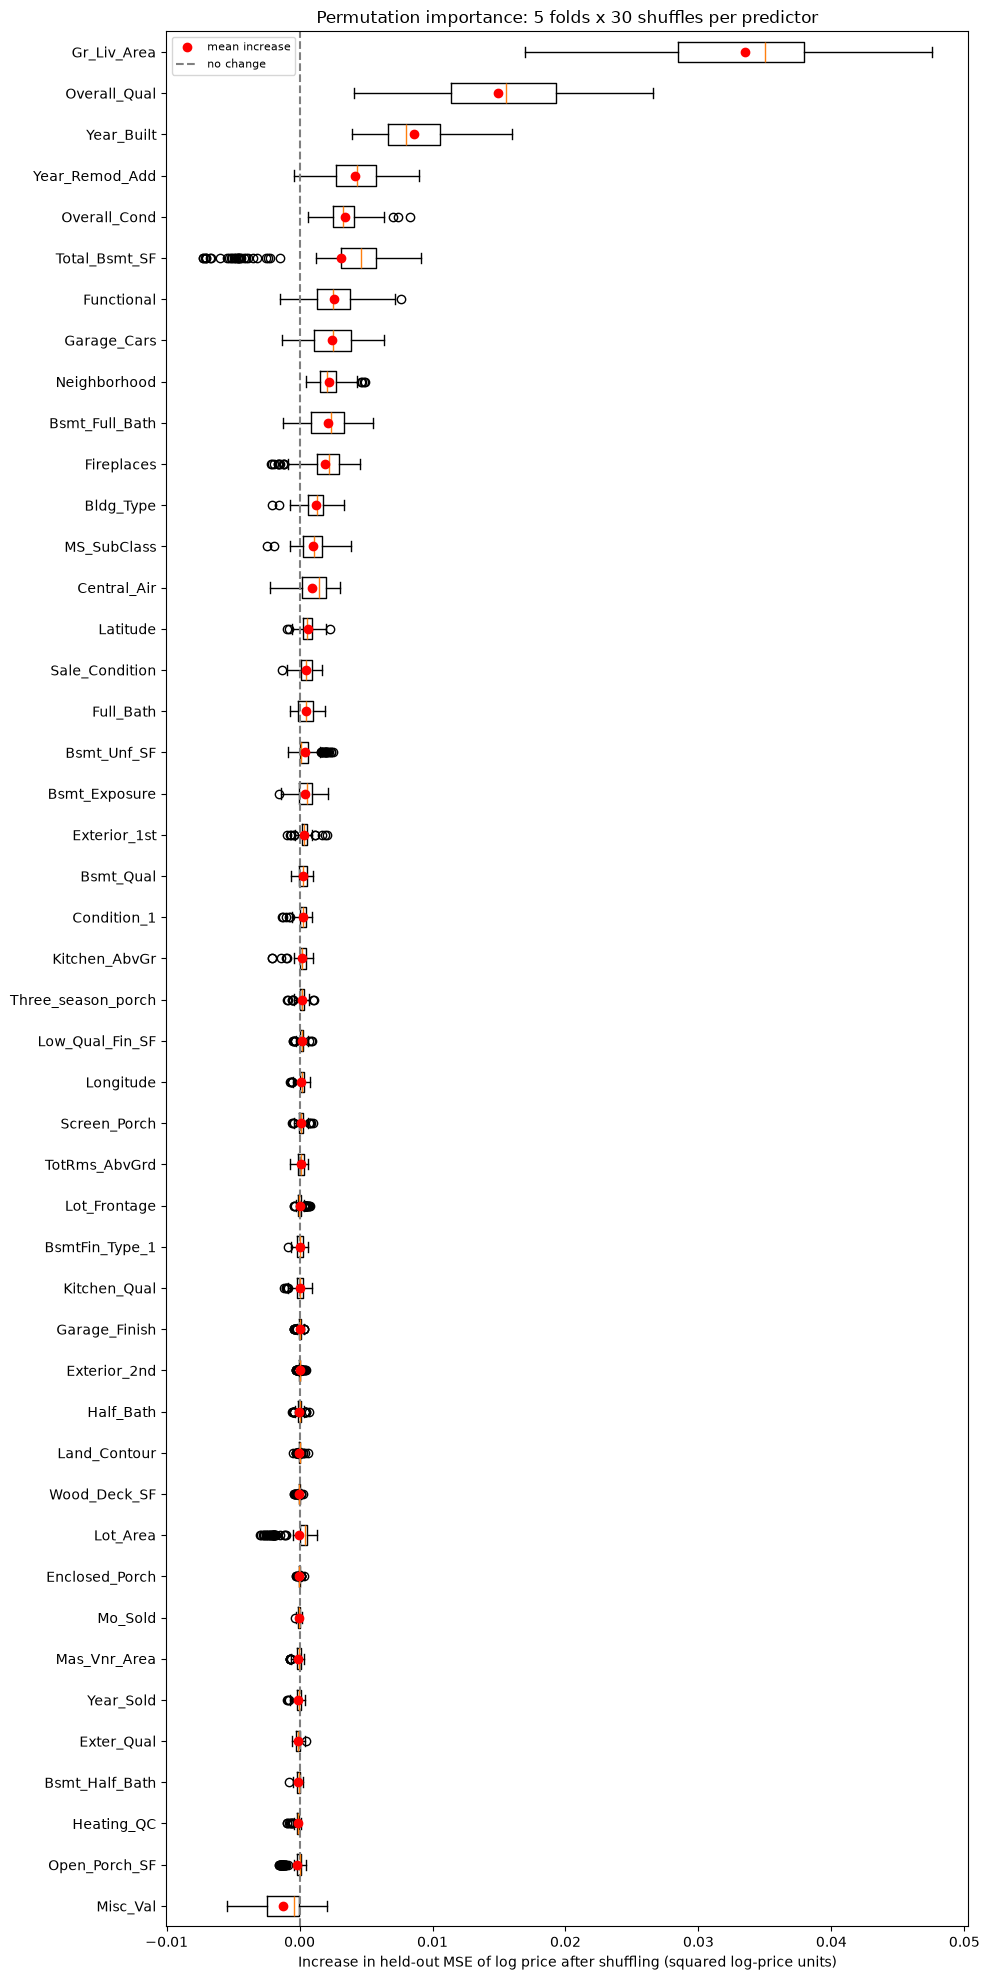

In [30]:
# Q3.4: held-out permutation importance of each original predictor behind the frozen features.
importance_sources = list(dict.fromkeys(feature_sources[j] for j in frozen_indices))
if "Lot_Frontage" in importance_sources and "Neighborhood" not in importance_sources:
    importance_sources.append("Neighborhood")  # neighborhood fills unknown frontage
print("Original predictors assessed:", importance_sources)

rng_importance = np.random.default_rng(4109)
baseline_rows, repeat_rows = [], []
for fold, (tr, va) in enumerate(inference_folds):
    x_va = X_inference.iloc[va]
    y_va = y_inference[va]
    fit = checked_ols(shared_preprocessor, X_inference.iloc[tr], y_inference[tr], frozen_indices, evaluation=x_va)
    base_mse = float(np.mean((y_va - fit["prediction"]) ** 2))
    baseline_rows.append({"fold": fold, "held_out_mse": base_mse, "held_out_count": len(va)})
    for source in importance_sources:
        for r in range(N_SHUFFLES):
            shuffled = x_va.copy()
            # Shuffle the raw column as a whole, then reuse the fitted preprocessing and coefficients.
            shuffled[source] = rng_importance.permutation(shuffled[source].to_numpy())
            design = np.column_stack([np.ones(len(va)), fit["prep"].transform(shuffled)[:, frozen_indices]])
            mse = float(np.mean((y_va - design @ fit["coef"]) ** 2))
            repeat_rows.append({"fold": fold, "source": source, "replicate": r, "degradation": mse - base_mse})

importance_baselines = pd.DataFrame(baseline_rows)
importance_repeats = pd.DataFrame(repeat_rows)
importance_summary = (
    importance_repeats.groupby("source")["degradation"].agg(["mean", "std"]).sort_values("mean", ascending=False)
)
importance_summary.index.name = "original predictor"
importance_summary["fold means (min to max)"] = (
    importance_repeats.groupby(["source", "fold"])["degradation"].mean().groupby("source")
    .agg(lambda s: f"{s.min():.4f} to {s.max():.4f}")
)
display(importance_baselines.round(5))
print(f"Pooled held-out MSE: {np.average(importance_baselines.held_out_mse, weights=importance_baselines.held_out_count):.5f}")
display(importance_summary.round(5))

order = importance_summary.index.tolist()
fig, ax = plt.subplots(figsize=(10, 0.4 * len(order) + 1.5))
ax.boxplot([importance_repeats.loc[importance_repeats.source == s, "degradation"] for s in order],
           orientation="horizontal", tick_labels=order, showfliers=True)
ax.scatter(importance_summary["mean"], np.arange(1, len(order) + 1), color="red", zorder=3, label="mean increase")
ax.axvline(0, color="gray", ls="--", label="no change")
ax.invert_yaxis()
ax.set_xlabel("Increase in held-out MSE of log price after shuffling (squared log-price units)")
ax.set_title(f"Permutation importance: {len(inference_folds)} folds x {N_SHUFFLES} shuffles per predictor")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [31]:
grader.check("q3_4")

q3_4 results: All test cases passed!

**Written response — Q3.4**

Pooled over the five inference folds, the frozen OLS model's held-out MSE is 0.0294 (RMSE ≈ 0.17; folds 0.017–0.041). Shuffling `Gr_Liv_Area` among held-out houses raises MSE by 0.0335 on average, more than doubling it, so the model relies on living area most; next come `Overall_Qual` (0.0150, all indicators shuffled together), `Year_Built` (0.0086), `Year_Remod_Add` (0.0042), `Overall_Cond` (0.0034) and `Neighborhood` (0.0022, including its role in filling frontage). Most other inputs barely matter given the rest of the model: 21 of the 46 assessed predictors change MSE by less than 0.0002 in absolute value, and some means are slightly negative (`Lot_Area` ≈ 0; `Misc_Val` −0.0012, negative in every fold, consistent with an overfit term, see Extension 1), which on small held-out folds is mostly noise.

Correlated inputs limit interpretation. Living area and rooms above ground overlap, as do `Year_Built` and `Year_Remod_Add`: the fitted model splits the weight, and shuffling one leaves the other carrying the information, so `TotRms_AbvGrd` scores near zero (0.0001) despite a clear price relationship. Conversely, shuffling one of a correlated pair creates unrealistic houses, which can inflate importance. These scores measure how much this fitted model relies on an input, not the input's own association with price. Spread across shuffles understates uncertainty because coefficients are fixed within a fold; fold spread shows some fitting variability (`Total_Bsmt_SF`: −0.005 to 0.006). None of this changed the frozen set.

## Q3.5. Quantify prediction uncertainty

**6 points**

We have examined the inputs used by the model, but a reported price prediction also needs a statement of uncertainty. Uncertainty in the fitted coefficients affects our estimate of the expected log price for a house with given characteristics. An individual sale can also differ from that expectation, so an interval for one future sale answers a different question from an interval for the conditional mean.

**Task:** Following Lecture 8, construct 95% intervals using `inference_folds` and `B_INTERVAL` bootstrap fits per training fold. The expected-response draws are bootstrap predictions of log price. For individual-outcome draws, add normal noise with mean zero and standard deviation equal to each bootstrap fit’s residual standard error; use `NOISE_DRAWS_PER_FIT` noise draws per fit. Compare both interval types and assess held-out individual-interval coverage and average width in log-price units. State the assumptions of this noise model.

**Artifacts:** A table of interval bounds for every held-out inference house; a plot comparing both interval types and observed prices for the eight inference houses with the smallest row IDs; distributions of expected-response and individual-outcome draws for one of those houses; and a summary of prediction-interval coverage and average width.

**Constraints:** Exclude each assessed house from all fits used to construct its intervals. Use residual degrees of freedom equal to the fitting-sample size minus the design-matrix rank, including the intercept. Observed sale-price coverage assesses individual prediction intervals, not confidence intervals for the conditional mean. If you exponentiate bounds for expected log price, do not label them as intervals for arithmetic mean price.

**Output names for the guided checks:** `interval_results`, one row per inference observation.

Use the smallest eight labels in `X_inference.index` for the comparison plot. `interval_results` should include `row_id`, `fold`, `actual`, `prediction`, `mean_low`, `mean_high`, `prediction_low`, and `prediction_high`. These bounds are on the log-price scale; label any exponentiated display accordingly.


In [32]:
# Supplied counts for prediction intervals; reuse inference_folds from Q3.4.
B_INTERVAL = 200
NOISE_DRAWS_PER_FIT = 20


Resamples redrawn because of an unidentified coefficient: 0


,row_id,fold,actual,prediction,mean_low,mean_high,prediction_low,prediction_high
0,6,0,12.2714,12.3448,12.2445,12.4321,12.0744,12.6144
1,8,2,12.3737,12.4883,12.4058,12.5760,12.2538,12.7260
2,17,0,12.8852,12.8134,12.7019,12.9337,12.5263,13.0946
3,23,3,11.9117,11.9345,11.8215,11.9978,11.6441,12.1878
4,24,4,11.9177,12.0476,11.9777,12.1023,11.7875,12.3135
5,29,1,11.4721,11.5339,11.4584,11.6150,11.2508,11.8105
6,31,4,11.3851,11.5212,11.4375,11.6026,11.2269,11.7876
7,37,3,12.6313,12.6078,12.5312,12.6679,12.3398,12.8632
8,40,1,12.3014,12.2736,12.1736,12.3540,11.9890,12.5469
9,42,4,12.4646,12.5592,12.4582,12.6642,12.2767,12.8286


,interval,observed-price coverage,average width (log price)
0,prediction (individual sale),0.9625,0.5457
1,confidence (expected log price),0.6121,0.1957


Prediction-interval coverage by fold: {0: 0.966, 1: 0.972, 2: 0.938, 3: 0.96, 4: 0.977}
Average prediction-interval width 0.546 log units is a factor of about 1.73 between the upper and lower price bounds.


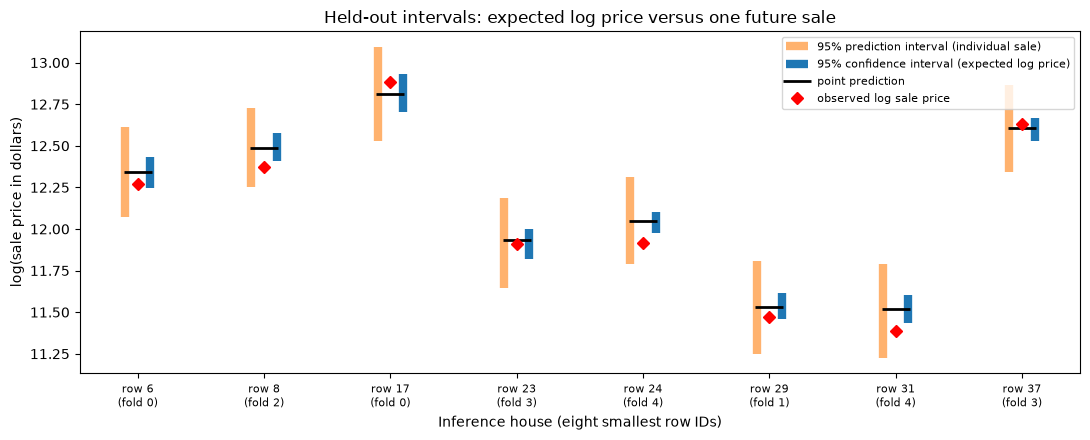

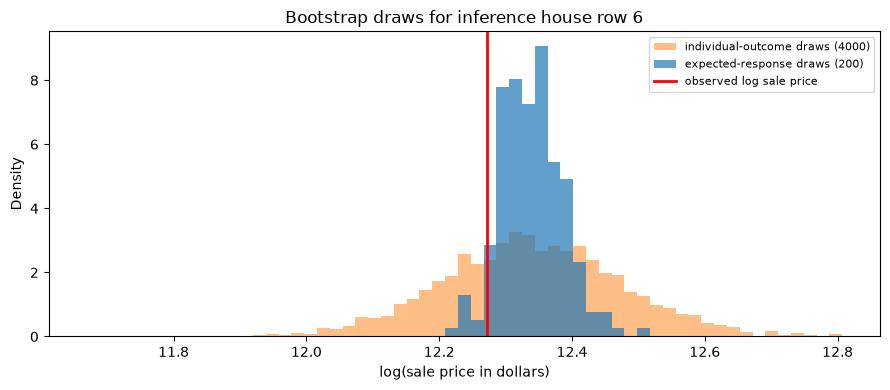

In [33]:
# Q3.5: bootstrap confidence and prediction intervals for every held-out inference house.
rng_interval = np.random.default_rng(5109)
interval_frames = []
draw_store = {}
redraws = 0
for fold, (tr, va) in enumerate(inference_folds):
    x_tr, y_tr = X_inference.iloc[tr], y_inference[tr]
    x_va = X_inference.iloc[va]
    point = checked_ols(shared_preprocessor, x_tr, y_tr, frozen_indices, evaluation=x_va)
    mean_draws = np.empty((B_INTERVAL, len(va)))
    sigmas = np.empty(B_INTERVAL)
    b = 0
    while b < B_INTERVAL:
        idx = rng_interval.integers(0, len(tr), size=len(tr))
        try:
            fit = checked_ols(shared_preprocessor, x_tr.iloc[idx], y_tr[idx], frozen_indices, evaluation=x_va)
        except ValueError:
            redraws += 1  # a rare indicator vanished from this resample; draw again
            continue
        mean_draws[b] = fit["prediction"]
        sigmas[b] = fit["sigma"]  # residual SE with df = resample size - design rank
        b += 1
    noise = rng_interval.normal(size=(B_INTERVAL, NOISE_DRAWS_PER_FIT, len(va))) * sigmas[:, None, None]
    outcome_draws = (mean_draws[:, None, :] + noise).reshape(-1, len(va))
    frame = pd.DataFrame(
        {
            "row_id": x_va.index,
            "fold": fold,
            "actual": y_inference[va],
            "prediction": point["prediction"],
            "mean_low": np.percentile(mean_draws, 2.5, axis=0),
            "mean_high": np.percentile(mean_draws, 97.5, axis=0),
            "prediction_low": np.percentile(outcome_draws, 2.5, axis=0),
            "prediction_high": np.percentile(outcome_draws, 97.5, axis=0),
        }
    )
    interval_frames.append(frame)
    for k, row_id in enumerate(x_va.index):
        draw_store[row_id] = (mean_draws[:, k], outcome_draws[:, k])

interval_results = pd.concat(interval_frames).sort_values("row_id").reset_index(drop=True)
print("Resamples redrawn because of an unidentified coefficient:", redraws)
display(interval_results.head(10).round(4))

covered = interval_results.actual.between(interval_results.prediction_low, interval_results.prediction_high)
mean_covered = interval_results.actual.between(interval_results.mean_low, interval_results.mean_high)
interval_summary = pd.DataFrame(
    {
        "interval": ["prediction (individual sale)", "confidence (expected log price)"],
        "observed-price coverage": [covered.mean(), mean_covered.mean()],
        "average width (log price)": [
            (interval_results.prediction_high - interval_results.prediction_low).mean(),
            (interval_results.mean_high - interval_results.mean_low).mean(),
        ],
    }
)
display(interval_summary.round(4))
print("Prediction-interval coverage by fold:", interval_results.assign(c=covered).groupby("fold")["c"].mean().round(3).to_dict())
print(f"Average prediction-interval width {interval_summary.iloc[0, 2]:.3f} log units "
      f"is a factor of about {np.exp(interval_summary.iloc[0, 2]):.2f} between the upper and lower price bounds.")

first8 = interval_results.nsmallest(8, "row_id")
x = np.arange(len(first8))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.vlines(x - 0.1, first8.prediction_low, first8.prediction_high, color="tab:orange", lw=6, alpha=0.6, label="95% prediction interval (individual sale)")
ax.vlines(x + 0.1, first8.mean_low, first8.mean_high, color="tab:blue", lw=6, label="95% confidence interval (expected log price)")
ax.plot(x, first8.prediction, "_", color="black", ms=20, mew=2, label="point prediction")
ax.plot(x, first8.actual, "D", color="red", label="observed log sale price")
ax.set_xticks(x, [f"row {r}\n(fold {f})" for r, f in zip(first8.row_id, first8.fold)], fontsize=8)
ax.set_xlabel("Inference house (eight smallest row IDs)")
ax.set_ylabel("log(sale price in dollars)")
ax.set_title("Held-out intervals: expected log price versus one future sale")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

example_id = int(first8.row_id.iloc[0])
mean_d, outcome_d = draw_store[example_id]
example = interval_results.set_index("row_id").loc[example_id]
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(outcome_d.min(), outcome_d.max(), 60)
ax.hist(outcome_d, bins=bins, density=True, alpha=0.5, color="tab:orange", label=f"individual-outcome draws ({len(outcome_d)})")
ax.hist(mean_d, bins=bins, density=True, alpha=0.7, color="tab:blue", label=f"expected-response draws ({len(mean_d)})")
ax.axvline(example.actual, color="red", lw=2, label="observed log sale price")
ax.set_xlabel("log(sale price in dollars)")
ax.set_ylabel("Density")
ax.set_title(f"Bootstrap draws for inference house row {example_id}")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [34]:
grader.check("q3_5")

q3_5 results: All test cases passed!

**Written response — Q3.5**

The two intervals answer different questions. The confidence interval for the **expected** log price reflects coefficient uncertainty only (average width 0.196 log-price units). The prediction interval for an **individual sale** adds house-to-house noise (average width 0.546: a factor of 1.73 between the upper and lower price bounds, about +31% / −24% around the prediction). Noise dominates. In the plot of the eight smallest row IDs every confidence interval sits inside a much longer prediction interval, and rows 8, 24 and 31 fall outside the confidence interval but inside the prediction interval; the row 6 histograms show concentrated expected-response draws against much wider individual-outcome draws.

**Coverage.** 96.2% of the 879 held-out log prices fall inside their 95% prediction intervals (folds 93.8–97.7%), close to nominal. The confidence intervals cover only 61%, as expected: they target the mean, not individual sales.

**Noise-model assumptions.** Each log price equals its expected value plus independent normal noise with mean zero and a constant SD for all houses, estimated by each bootstrap fit's residual standard error (df = resample size − design rank). The frozen model must also be correct on the log scale, frontage imputation adequate and houses independent. If expensive or abnormal sales have larger noise, their intervals are too narrow and others' too wide, which overall coverage can hide.

## Q3.6. Assess global statistical evidence

**4 points**

The preceding analyses describe selection stability, estimated associations, and predictive reliance. We can also ask how unusual the overall coefficient evidence would be if prices had no relationship with the predictor set. Permuting the responses provides a reference distribution for that global question, which differs from testing one coefficient conditional on the others.

**Task:** Reuse the Q3.3 bootstrap rows and `coefficient_operators`. Calculate observed coefficient draws as `coefficient_operators @ y_inference`, and compute each coefficient's bootstrap ratio using the lecture notation,
$$\hat{t}_j = \frac{\overline{\beta^*_j}}{\mathrm{SD}(\beta^*_j)}.$$
For our single global test, take the largest absolute ratio,
$$\hat{t}_{\max,\mathrm{obs}} = \max_j |\hat{t}_j|,$$
excluding the intercept. Shuffle `y_inference` using `N_PERMUTATIONS` permutations. For each shuffled response vector, use the same maps to recompute coefficient draws and the same maximum statistic. Report
$$p=\frac{1+\#\{\hat{t}_{\max,\mathrm{null}}\ge \hat{t}_{\max,\mathrm{obs}}\}}{1+N_{\mathrm{PERMUTATIONS}}}.$$

**Artifacts:** `null_statistics`, an array of permutation statistics; `global_pvalue`; a null-distribution plot with the observed statistic marked; and an explanation of the null, p-value, and minimum possible p-value, $1/(1+N_{\mathrm{PERMUTATIONS}})$.

**Constraints:** State the exchangeability assumption for response permutation. If a coefficient’s bootstrap standard deviation is zero or below `1e-12`, identify that feature and stop to investigate before calculating a ratio. Use the same maps and sample count for observed and null calculations. Their preprocessing is learned from predictors only, so the maps apply to every shuffled response without refitting tens of thousands of models. This global test does not test each coefficient conditional on the others.

In [35]:
# Supplied number of response permutations for the global-null test.
N_PERMUTATIONS = 199


Observed max |t| = 7.92, from Gr_Liv_Area


term,Gr_Liv_Area,Year_Remod_Add,Fireplaces,Garage_Cars,Neighborhood_Crawford,Overall_Qual_Very_Good,Overall_Qual_Excellent,Year_Built,Functional_Typ,Bsmt_Full_Bath
bootstrap_ratio,7.92,5.36,4.96,4.86,4.77,4.7,4.2,4.03,3.75,3.65


Null max |t|: median 2.60, 95th percentile 3.40, max 4.01
Permutation p-value = 0.0050 (smallest possible = 0.0050)


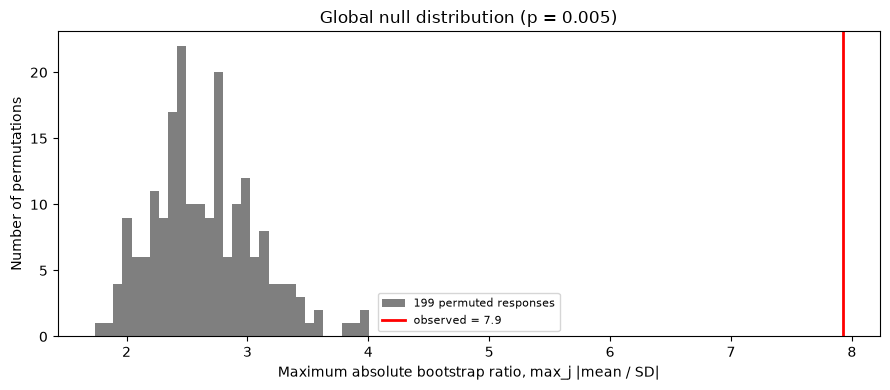

In [36]:
# Q3.6: global permutation test using the Q3.3 bootstrap maps.
def max_bootstrap_ratio(response):
    """Largest |mean/SD| of the bootstrap coefficient draws (intercept already excluded)."""
    draws = coefficient_operators @ response
    sd = draws.std(axis=0, ddof=1)
    if np.any(sd < 1e-12):
        bad = [frozen_terms[k] for k in np.flatnonzero(sd < 1e-12)]
        raise ValueError(f"Zero bootstrap SD for {bad}; investigate before computing ratios.")
    return float(np.max(np.abs(draws.mean(axis=0) / sd)))


observed_draws = coefficient_operators @ y_inference
bootstrap_ratio = observed_draws.mean(axis=0) / observed_draws.std(axis=0, ddof=1)
t_max_observed = max_bootstrap_ratio(y_inference)
print(f"Observed max |t| = {t_max_observed:.2f}, from {frozen_terms[int(np.argmax(np.abs(bootstrap_ratio)))]}")
display(pd.DataFrame({"term": frozen_terms, "bootstrap_ratio": bootstrap_ratio}).set_index("term")
        .sort_values("bootstrap_ratio", key=np.abs, ascending=False).round(2).head(10).T)

rng_perm = np.random.default_rng(6109)
null_statistics = np.array(
    [max_bootstrap_ratio(rng_perm.permutation(y_inference)) for _ in range(N_PERMUTATIONS)]
)
global_pvalue = (1 + np.sum(null_statistics >= t_max_observed)) / (1 + N_PERMUTATIONS)
print(f"Null max |t|: median {np.median(null_statistics):.2f}, 95th percentile {np.percentile(null_statistics, 95):.2f}, "
      f"max {null_statistics.max():.2f}")
print(f"Permutation p-value = {global_pvalue:.4f} (smallest possible = {1 / (1 + N_PERMUTATIONS):.4f})")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(null_statistics, bins=30, color="tab:gray", label=f"{N_PERMUTATIONS} permuted responses")
ax.axvline(t_max_observed, color="red", lw=2, label=f"observed = {t_max_observed:.1f}")
ax.set_xlabel("Maximum absolute bootstrap ratio, max_j |mean / SD|")
ax.set_ylabel("Number of permutations")
ax.set_title(f"Global null distribution (p = {global_pvalue:.3f})")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [37]:
grader.check("q3_6")

q3_6 results: All test cases passed!

**Written response — Q3.6**

The global null is that log price has no relationship with the frozen predictors: given the predictor values, every assignment of the observed prices to houses is equally likely, so permuting `y_inference` yields data as plausible as the observed. This requires exchangeable houses (independent and identically distributed, with no grouping such as sale year or block that makes some permutations unrealistic).

The observed statistic is 7.92 (the largest absolute bootstrap ratio, `Gr_Liv_Area`). The 199 permuted statistics have median 2.60, 95th percentile 3.40 and maximum 4.01, so none comes close, and p = (1 + 0)/(1 + 199) = **0.005**, the smallest possible with 199 permutations. We reject the global null: at least one frozen feature is associated with price in the independent sample (p ≤ 0.005; more permutations would be needed to measure the probably far smaller true tail probability). The test does not say which features and is not a conditional test of any single coefficient. Taking the maximum over all 68 ratios makes it one global question, but a large individual ratio still has no individual p-value here.

## Q3.7. Synthesize the model evidence

**3 points**

We now have several kinds of evidence about the model, and they need not give identical impressions of every predictor. A feature might be selected often but have an uncertain coefficient, or have a clear association while adding little predictive information beyond other inputs. Combining these results helps us distinguish conclusions supported by the analyses from conclusions that remain uncertain.

**Task:** Choose three features from `frozen_indices` and compare the evidence about their selection stability, coefficient uncertainty, and predictive importance. Explain what the overall permutation result adds to the model interpretation and what it does not establish about those individual features.

**Artifacts:** Compact synthesis table and qualified interpretation.

**Constraints:** Do not assign the global p-value to individual features or make causal claims. If the analyses suggest different conclusions, explain why their questions differ; do not assume their rankings must agree.

For each feature, report its Q3.1 selection frequency, Q3.3 coefficient and interval, and Q3.4 original-predictor importance. For an indicator, use the importance of its whole original categorical predictor and label that distinction; Q3.4 does not give a separate importance score for each encoded level.


In [38]:
# Q3.7: three frozen features compared across selection, coefficient and importance evidence.
synthesis_terms = ["Gr_Liv_Area", "Overall_Qual_Excellent", "Lot_Frontage"]
synthesis_rows = []
for term in synthesis_terms:
    j = feature_names.index(term)
    k = frozen_terms.index(term)
    source = feature_sources[j]
    cs_row = coefficient_summary.iloc[k]
    synthesis_rows.append({
        "feature": term,
        "type": "numeric (per SD)" if j < n_numeric else f"indicator of {source}",
        "Q3.1 selection frequency": selection_frequencies[j],
        "Q3.3 coefficient": cs_row["coefficient"],
        "Q3.3 95% interval": f"[{cs_row['lower']:.3f}, {cs_row['upper']:.3f}]",
        "Q3.4 importance of": source + (" (whole categorical predictor)" if j >= n_numeric else ""),
        "Q3.4 mean MSE increase": importance_summary.loc[source, "mean"],
        "Q3.4 importance rank": int(importance_summary.index.get_loc(source)) + 1,
    })
synthesis_table = pd.DataFrame(synthesis_rows).set_index("feature")
print(f"Global permutation p-value (Q3.6) for the whole frozen set: {global_pvalue:.3f}; "
      f"importance ranks out of {len(importance_summary)} original predictors.")
display(synthesis_table.round(4))

Global permutation p-value (Q3.6) for the whole frozen set: 0.005; importance ranks out of 46 original predictors.


,type,Q3.1 selection frequency,Q3.3 coefficient,Q3.3 95% interval,Q3.4 importance of,Q3.4 mean MSE increase,Q3.4 importance rank
feature,,,,,,,
Gr_Liv_Area,numeric (per SD),1.00,0.1399,"[0.108, 0.179]",Gr_Liv_Area,0.0335,1
Overall_Qual_Excellent,indicator of Overall_Qual,1.00,0.2575,"[0.134, 0.375]",Overall_Qual (whole categorical predictor),0.0150,2
Lot_Frontage,numeric (per SD),0.91,-0.0025,"[-0.016, 0.014]",Lot_Frontage,0.0000,29


**Written response — Q3.7**

| feature | Q3.1 selection frequency | Q3.3 coefficient [95% interval] | Q3.4 importance (MSE increase, rank of 46) |
|---|---:|---|---|
| `Gr_Liv_Area` (per SD) | 1.00 | +0.140 [0.108, 0.179] | 0.0335, rank 1 |
| `Overall_Qual_Excellent` (0/1) | 1.00 | +0.257 [0.134, 0.375] | 0.0150, rank 2, for **all of `Overall_Qual`** |
| `Lot_Frontage` (per SD) | 0.91 | −0.003 [−0.016, 0.014] | 0.00004, rank 29 |

**`Gr_Liv_Area`: all three agree.** Selected in every resample, precisely estimated away from zero in fresh data, and the most damaging input to shuffle.

**`Overall_Qual_Excellent`: stable and clearly positive, but imprecise** (only 38 inference houses carry it). Its rank-2 importance belongs to the whole `Overall_Qual` predictor (Q3.4 shuffles all levels together), so it shows reliance on overall quality, not on the Excellent level.

**`Lot_Frontage`: frequent selection is not association or predictive value.** Selected in 91% of resamples, yet its inference coefficient is indistinguishable from zero and shuffling it leaves held-out error unchanged. The analyses ask different questions (reproducibility of selection, size of a conditional association, reliance of this fit), so their rankings need not agree.

**Global test.** The p-value of 0.005 (the minimum for 199 permutations) is strong evidence that the frozen set as a whole is associated with log price in data that played no part in selection. It does not show that any individual feature, including `Lot_Frontage`, is associated with price, and nothing here is causal.

## AC209A Extension 1. Individual classical coefficient tests (AC209A only)

**6 points**

The global permutation result concerns the predictor set as a whole. Extend the interpretation to individual coefficients conditional on the other included features.

**Task:** Use statsmodels on the independent inference fit to obtain standard errors, t-statistics, p-values and intervals. Use $t_j=\hat\beta_j/\mathrm{SE}(\hat\beta_j)$, with $\nu=n-\mathrm{rank}(X)$ degrees of freedom and two-sided $p_j=2[1-F_{t_\nu}(|t_j|)]$. Interpret and compare with the global result. In this question's own answer cell, write an addendum explaining how these tests qualify or reinforce your Q3.7 synthesis.

**Artifacts:** Individual-test table, aligned classical/bootstrap intervals, and synthesis addendum.

**Constraints:** Explain classical model assumptions and individual rather than simultaneous testing. No mathematical derivation or custom t-distribution implementation required. Independent-fit inference does not transfer automatically to final refit coefficients.

Before comparing with Q3.3, convert numeric coefficient estimates, standard errors, and interval bounds to the same `reference_sd` units. The positive scaling factor does not change t-statistics or p-values. Indicators remain in 0/1 units. CS1090A students skip this extension.


n = 879, rank(X) = 69, residual df = 810 (= n - rank: 810)
Point estimates match Q3.3: True


,term,coefficient,se,t,p_value,classical_lower,classical_upper,bootstrap_sd,bootstrap_lower,bootstrap_upper,se_ratio (bootstrap/classical)
0,Bldg_Type_Twnhs,-0.0540,0.0348,-1.5501,0.1215,-0.1223,0.0144,0.0251,-0.1014,-0.0037,0.7223
1,Bsmt_Full_Bath,0.0346,0.0073,4.7592,0.0000,0.0203,0.0488,0.0085,0.0148,0.0480,1.1655
2,Central_Air_Y,0.1019,0.0241,4.2256,0.0000,0.0546,0.1493,0.0477,0.0207,0.2032,1.9783
3,Condition_1_Norm,0.0377,0.0150,2.5050,0.0124,0.0082,0.0672,0.0150,0.0033,0.0645,0.9984
4,Enclosed_Porch,0.0018,0.0063,0.2798,0.7797,-0.0106,0.0142,0.0076,-0.0127,0.0157,1.2056
5,Fireplaces,0.0353,0.0066,5.3774,0.0000,0.0224,0.0481,0.0067,0.0206,0.0462,1.0235
6,Full_Bath,0.0152,0.0083,1.8269,0.0681,-0.0011,0.0314,0.0105,-0.0068,0.0335,1.2651
7,Garage_Cars,0.0378,0.0073,5.1571,0.0000,0.0234,0.0522,0.0075,0.0218,0.0506,1.0265
8,Gr_Liv_Area,0.1399,0.0136,10.3029,0.0000,0.1132,0.1665,0.0182,0.1078,0.1788,1.3398
9,Heating_QC_Typical,-0.0025,0.0127,-0.1950,0.8454,-0.0274,0.0224,0.0133,-0.0272,0.0210,1.0506


p < 0.05 for 30 of 68 coefficients.
Inference houses with Overall_Qual_Excellent: 38
Classical and bootstrap 95% intervals agree on excluding zero for 63 of 68 features.
Features where they disagree:


,term,coefficient,p_value,classical_lower,classical_upper,bootstrap_lower,bootstrap_upper,se_ratio (bootstrap/classical)
0,Bldg_Type_Twnhs,-0.0540,0.1215,-0.1223,0.0144,-0.1014,-0.0037,0.7223
21,Screen_Porch,0.0106,0.0516,-0.0001,0.0213,0.0004,0.0212,0.9638
48,Overall_Cond_Below_Average,-0.0763,0.0058,-0.1304,-0.0221,-0.1577,0.0107,1.5204
54,Lot_Area,0.0136,0.0499,0.0000,0.0272,-0.0003,0.0290,1.1554
63,Misc_Val,-0.0130,0.0000,-0.0168,-0.0092,-0.0316,0.0096,6.4211


Largest bootstrap/classical SE ratios:


,term,se,bootstrap_sd,se_ratio (bootstrap/classical)
63,Misc_Val,0.0019,0.0124,6.4211
2,Central_Air_Y,0.0241,0.0477,1.9783
30,Functional_Typ,0.0216,0.0403,1.8637
32,Kitchen_Qual_Typical,0.0236,0.0438,1.8586
59,Kitchen_Qual_Good,0.0222,0.0399,1.7963


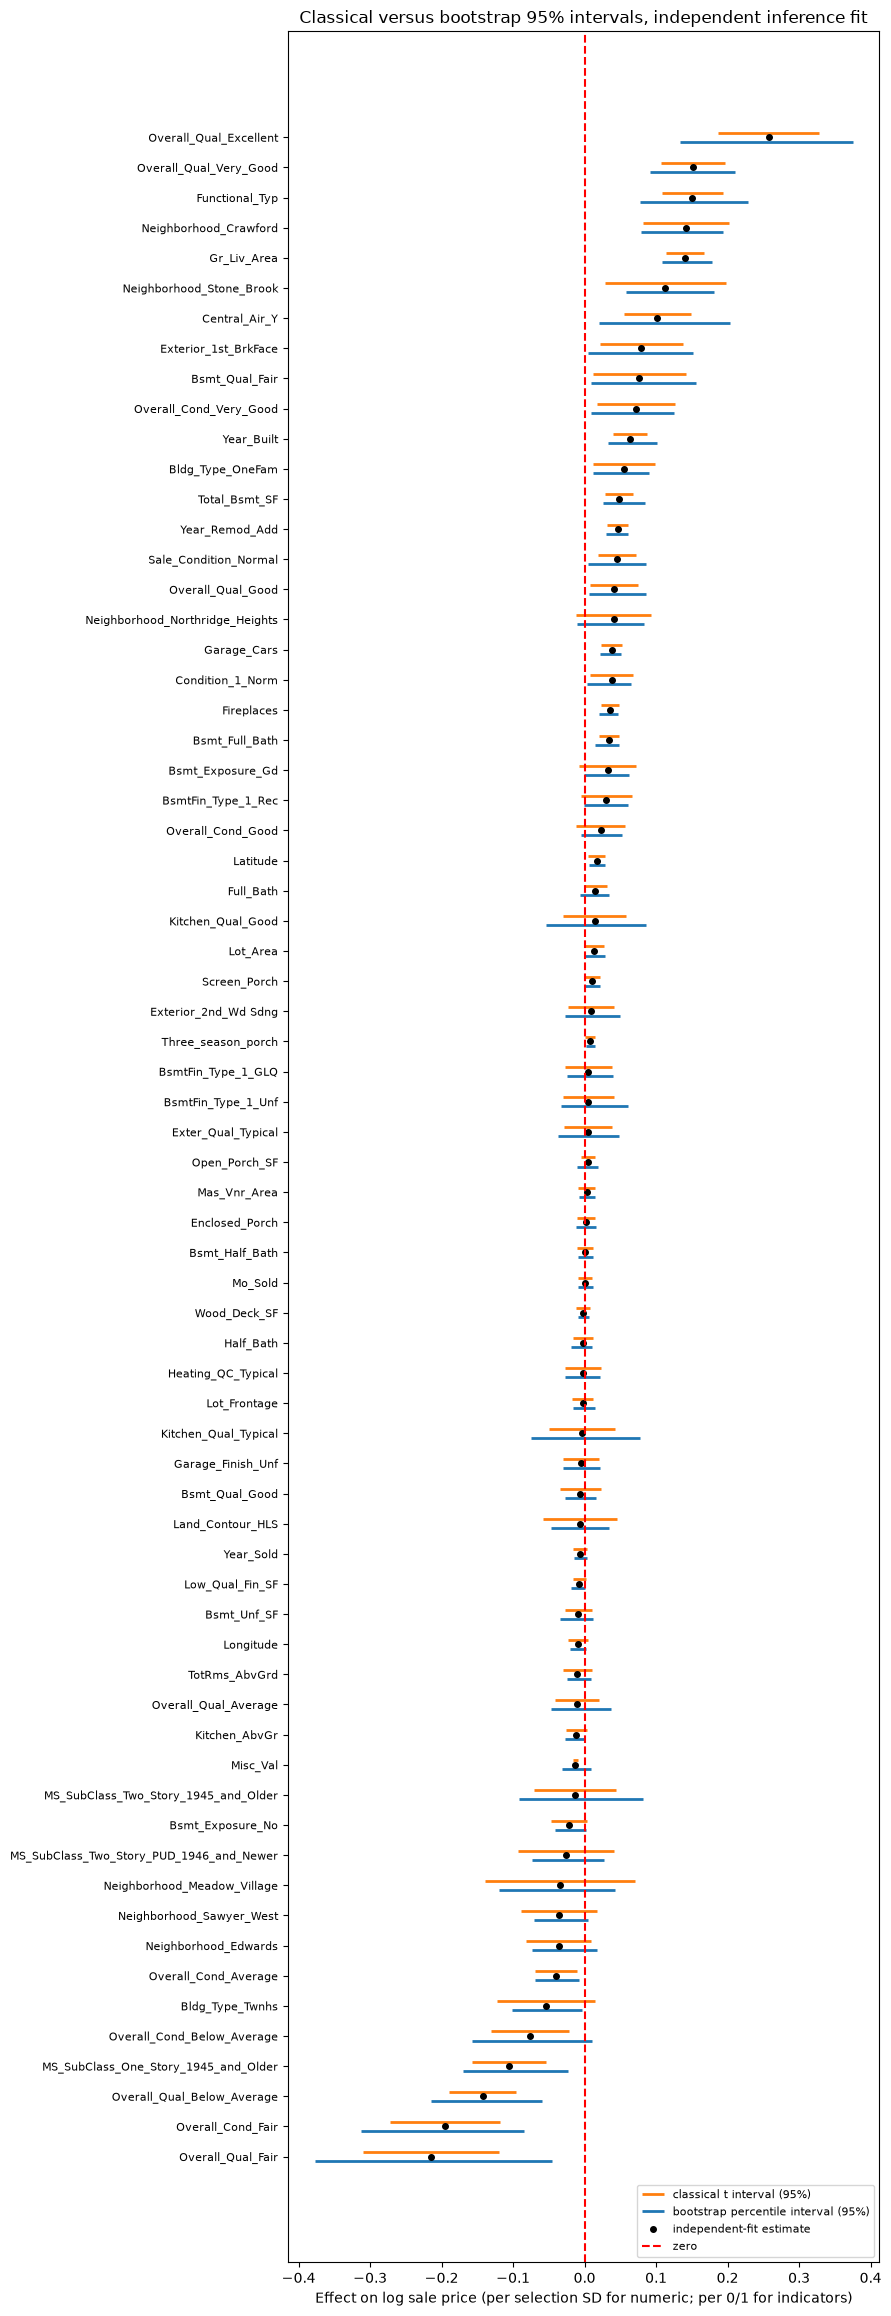

In [39]:
# AC209A Extension 1: classical t-tests for each coefficient in the independent inference fit.
import statsmodels.api as sm

ols_sm = sm.OLS(y_inference, inference_fit["design"]).fit()
rank_design = np.linalg.matrix_rank(inference_fit["design"])
print(f"n = {len(y_inference)}, rank(X) = {rank_design}, residual df = {ols_sm.df_resid:.0f} "
      f"(= n - rank: {len(y_inference) - rank_design})")
ci = ols_sm.conf_int(alpha=0.05)[1:]  # drop the intercept
classical_tests = pd.DataFrame(
    {
        "term": frozen_terms,
        "coefficient": ols_sm.params[1:] * reference_multiplier,
        "se": ols_sm.bse[1:] * reference_multiplier,
        "t": ols_sm.tvalues[1:],
        "p_value": ols_sm.pvalues[1:],
        "classical_lower": ci[:, 0] * reference_multiplier,
        "classical_upper": ci[:, 1] * reference_multiplier,
    }
)
# Align with the Q3.3 bootstrap results (same reference_sd units).
classical_tests["bootstrap_sd"] = coefficient_summary["sd"].to_numpy()
classical_tests["bootstrap_lower"] = coefficient_summary["lower"].to_numpy()
classical_tests["bootstrap_upper"] = coefficient_summary["upper"].to_numpy()
classical_tests["se_ratio (bootstrap/classical)"] = classical_tests["bootstrap_sd"] / classical_tests["se"]
print("Point estimates match Q3.3:", bool(np.allclose(classical_tests["coefficient"], coefficient_summary["coefficient"])))
with pd.option_context("display.max_rows", 200, "display.width", 250):
    display(classical_tests.round(4))
print(f"p < 0.05 for {int((classical_tests.p_value < 0.05).sum())} of {len(classical_tests)} coefficients.")
n_excellent = int(np.count_nonzero(inference_fit["prep"].transform(X_inference)[:, feature_names.index("Overall_Qual_Excellent")]))
print(f"Inference houses with Overall_Qual_Excellent: {n_excellent}")
both_exclude = ((classical_tests.classical_lower > 0) | (classical_tests.classical_upper < 0)) == coefficient_summary["interval_excludes_zero"].to_numpy()
print(f"Classical and bootstrap 95% intervals agree on excluding zero for {int(both_exclude.sum())} of {len(both_exclude)} features.")
print("Features where they disagree:")
display(classical_tests.loc[~both_exclude.to_numpy(), ["term", "coefficient", "p_value", "classical_lower", "classical_upper",
                                                        "bootstrap_lower", "bootstrap_upper", "se_ratio (bootstrap/classical)"]].round(4))
print("Largest bootstrap/classical SE ratios:")
display(classical_tests.nlargest(5, "se_ratio (bootstrap/classical)")[["term", "se", "bootstrap_sd", "se_ratio (bootstrap/classical)"]].round(4))

order = np.argsort(classical_tests["coefficient"].to_numpy())
ypos = np.arange(len(order))
ct = classical_tests.iloc[order]
fig, ax = plt.subplots(figsize=(9, 0.32 * len(order) + 1.5))
ax.hlines(ypos + 0.15, ct.classical_lower, ct.classical_upper, color="tab:orange", lw=2, label="classical t interval (95%)")
ax.hlines(ypos - 0.15, ct.bootstrap_lower, ct.bootstrap_upper, color="tab:blue", lw=2, label="bootstrap percentile interval (95%)")
ax.plot(ct.coefficient, ypos, "o", color="black", ms=4, label="independent-fit estimate")
ax.axvline(0, color="red", ls="--", label="zero")
ax.set_yticks(ypos, ct.term, fontsize=8)
ax.set_xlabel("Effect on log sale price (per selection SD for numeric; per 0/1 for indicators)")
ax.set_title("Classical versus bootstrap 95% intervals, independent inference fit")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()


**Written response — AC209A Extension 1**

Refitting the independent inference model in statsmodels (n = 879, rank 69, ν = 810), with coefficients, SEs and intervals converted to Q3.3's `reference_sd` units (the positive factor leaves t and p unchanged), **30 of 68 coefficients have p < 0.05**. Classical and bootstrap intervals agree on excluding zero for 63 of 68; three disagreements are near the boundary (`Screen_Porch` p = 0.052 and `Lot_Area` p = 0.0499 classically; `Bldg_Type_Twnhs` bootstrap upper bound −0.004) and two are substantive:

- `Misc_Val`: classical p < 0.0001, [−0.017, −0.009], but bootstrap [−0.032, 0.010]; its bootstrap SD is **6.4 times** the classical SE. It is zero for almost every house and large for a few, so the estimate rests on a few high-leverage sales that the classical SE (fixed predictors, constant variance) misses.
- `Overall_Cond_Below_Average`: classical p = 0.006, bootstrap [−0.158, 0.011], SD 1.5 times larger.

**Assumptions and scope.** Classical tests assume a correct linear mean on the log scale, independent constant-variance errors and normality (or large n), with the design chosen without these outcomes (true here). Each p-value tests one coefficient conditional on the other 67 at a 5% rate for that test alone, so about 3 false rejections are expected among 68 tests even if every coefficient were zero; Q3.6's single global test answers a different question. Results describe the independent fit, not the Q3.8 refit.

**Addendum to Q3.7.** The tests reinforce `Gr_Liv_Area` (t = 10.3, p < 0.0001) and `Overall_Qual_Excellent` (t = 7.2, p < 0.0001; classical [0.187, 0.328] against bootstrap [0.134, 0.375], plausibly narrower because the bootstrap better reflects the 38 houses carrying the level). For `Lot_Frontage` (t = −0.33, p = 0.74) they confirm that frequent selection gave no detectable conditional association. Q3.6 showed only that the set matters; these tests show which coefficients carry individual evidence, while `Misc_Val` warns that a decisive p-value can rest on a few unusual houses.


## Q3.8. Final predictive evaluation

**4 points**

The development analyses have informed our modeling choices without using the reserved test houses. Once those choices are fixed, we can refit the predictive procedures on all non-test houses and assess their performance on new observations. This refit uses more data for prediction, but its coefficients do not inherit the intervals or p-values from the independent inference fit.

**Task:** Freeze choices, concatenate selection rows followed by inference rows as all training data, refit preprocessing and the model, and evaluate the tuned lasso and fixed-subset OLS models on test. For final lasso, apply the specified CV tuning rule on all training data; for fixed-subset OLS, retain the frozen features with no penalty. Quantify appropriate performance-score uncertainty.

**Artifacts:** Final predictive comparison reporting test RMSE in log-price units; a scoped uncertainty summary; and one sentence explaining which earlier inference results apply to the refitted model.

**Constraints:** Freeze the model choices before examining test performance. Do not retune or select models using test results. Earlier coefficient intervals and p-values describe the independent inference fit. State whether your performance uncertainty reflects the test sample, repeated model development, or both.

Run this question only after finishing the earlier Ames questions and freezing choices. For the final lasso fit, use `all_train_folds`, `LASSO_ALPHAS`, and the Q2.2 minimum pooled-error rule on all training rows. Test outcomes must not enter any fit, tuning choice, or diagnostic until this evaluation.

Build all-training IDs with `np.concatenate([selection_ids, inference_ids])` and test IDs with `partitions["test"]`. Take each group’s predictors from `ames_x.loc[ids]` and its response from `np.log(raw_ames.loc[ids, "Sale_Price"])`. Preserve this row order when using the supplied folds.


In [40]:
# Fixed final-fit folds assume selection houses followed by inference houses.
all_train_folds = fixed_folds(len(selection_ids) + len(inference_ids), seed=109)


In [41]:
# Q3.8: refit the frozen procedures on all non-test houses and score them once on the test houses.
train_ids = np.concatenate([selection_ids, inference_ids])
test_ids = partitions["test"]
X_train_all = ames_x.loc[train_ids]
y_train_all = np.log(raw_ames.loc[train_ids, "Sale_Price"].to_numpy())
X_test = ames_x.loc[test_ids]
y_test = np.log(raw_ames.loc[test_ids, "Sale_Price"].to_numpy())

# Tuned lasso: same pooled minimum-MSE rule on all training rows.
final_lasso_tuning = tune_penalty("lasso", LASSO_ALPHAS, X_train_all, y_train_all, all_train_folds)
final_prep = clone(shared_preprocessor).fit(X_train_all)
final_lasso = make_penalized("lasso", final_lasso_tuning["alpha"]).fit(final_prep.transform(X_train_all), y_train_all)
lasso_test_pred = final_lasso.predict(final_prep.transform(X_test))
# Fixed-subset OLS: the frozen features, no penalty.
final_ols = checked_ols(shared_preprocessor, X_train_all, y_train_all, frozen_indices, evaluation=X_test)
ols_test_pred = final_ols["prediction"]

final_comparison = pd.DataFrame(
    {
        "alpha": [final_lasso_tuning["alpha"], np.nan],
        "features used": [int((np.abs(final_lasso.coef_) > NONZERO_TOL).sum()), len(frozen_indices)],
        "training CV RMSE": [final_lasso_tuning["cv_rmse"], np.nan],
        "test RMSE": [rmse(y_test, lasso_test_pred), rmse(y_test, ols_test_pred)],
    },
    index=["tuned lasso", "fixed-subset OLS"],
)
display(final_comparison.round(4))

# Uncertainty from the finite test sample: paired bootstrap over test houses (models held fixed).
rng_test = np.random.default_rng(8110)
test_boot = []
for _ in range(5000):
    i = rng_test.integers(0, len(y_test), size=len(y_test))
    r_lasso, r_ols = rmse(y_test[i], lasso_test_pred[i]), rmse(y_test[i], ols_test_pred[i])
    test_boot.append((r_lasso, r_ols, r_ols - r_lasso))
test_boot = np.array(test_boot)
test_uncertainty = pd.DataFrame(
    {"estimate": [final_comparison.loc["tuned lasso", "test RMSE"], final_comparison.loc["fixed-subset OLS", "test RMSE"],
                  final_comparison.loc["fixed-subset OLS", "test RMSE"] - final_comparison.loc["tuned lasso", "test RMSE"]],
     "2.5%": np.percentile(test_boot, 2.5, axis=0), "97.5%": np.percentile(test_boot, 97.5, axis=0)},
    index=["tuned lasso RMSE", "fixed-subset OLS RMSE", "difference (OLS - lasso)"],
)
display(test_uncertainty.round(4))
print(f"Share of test resamples where lasso has the lower RMSE: {np.mean(test_boot[:, 2] > 0):.3f}")

,alpha,features used,training CV RMSE,test RMSE
tuned lasso,0.0005,130,0.1495,0.1219
fixed-subset OLS,NaN,68,NaN,0.1315


,estimate,2.5%,97.5%
tuned lasso RMSE,0.1219,0.1093,0.1350
fixed-subset OLS RMSE,0.1315,0.1197,0.1434
difference (OLS - lasso),0.0096,0.0040,0.0152


Share of test resamples where lasso has the lower RMSE: 0.999


**Written response — Q3.8**

| model (refitted on 2,197 non-test houses) | penalty | features | test RMSE (log price) | 95% bootstrap interval |
|---|---:|---:|---:|---|
| tuned lasso | 5.4×10⁻⁴ | 130 | **0.122** | [0.109, 0.135] |
| fixed-subset OLS (68 frozen features) | — | 68 | 0.131 | [0.120, 0.143] |
| difference (OLS − lasso) | | | 0.0096 | [0.0040, 0.0152] |

Choices were frozen before the test houses were used: the pooled-MSE rule, grid, folds and 68-feature subset. On all training rows the rule chose a smaller penalty than on the selection rows alone (5.4×10⁻⁴ against 1.19×10⁻³), keeping 130 features (training-CV RMSE 0.149). On the 733 test houses the tuned lasso is more accurate (typical error about 13% in price); the paired bootstrap gives the RMSE difference a 95% interval of 0.004 to 0.015, with the lasso ahead in 99.9% of resamples.

**Scope.** The intervals resample the 733 test houses with both models fixed, so they reflect only the finite test sample. They exclude the variability of repeating model development (retuning, reselecting, refitting), which Q3.1–Q3.2 showed is substantial, and so understate the uncertainty of each *procedure*. The Q3.3 and Extension 1 intervals and p-values describe only the independent inference fit, not the refitted models, whose training data include the selection houses that chose the features.

# Part 4. Principal component analysis

## PCA for visualization

The Ames analyses used predictors with familiar meanings. Before modeling high-dimensional spectra, we will use PCA on familiar animal traits so that you can interpret directions and loading arrows using knowledge you already have. The supplied [UCI Zoo dataset](https://archive.ics.uci.edu/dataset/111/zoo) describes 101 animals with 15 yes/no traits and a leg count. Names and seven animal classes are metadata used for annotation, not PCA inputs.


In [42]:
# Supplied taxonomy labels; neither names nor classes enter PCA.
classes = {
    1: "Mammals",
    2: "Birds",
    3: "Reptiles",
    4: "Fish",
    5: "Amphibians",
    6: "Insects",
    7: "Other invertebrates",
}


In [43]:
# Supplied animal data; names and classes are metadata.
zoo = pd.read_csv("data/zoo.csv")
traits = [c for c in zoo if c not in ["animal_name", "class_type"]]


## Q4.1. Construct and interpret an animal biplot

**5 points**

The Ames analysis used predictors to model a response. PCA instead summarizes variation among the predictors themselves, which can help us visualize a dataset with many measurements. Animal traits provide a familiar setting for connecting the positions of observations and the directions of the loading vectors to concrete differences in the recorded features.

**Task:** Use the Zoo trait predictors to fit PCA and plot the first two components. Color points by the supplied animal classes, place animal names near representative points, overlay labeled trait-loading arrows on the same scatter plot, and include each component’s explained-variance percentage in its axis label. Use the arrows to interpret two directions of variation and explain two selected animal comparisons.

**Artifacts:** One readable annotated biplot and focused interpretation.

**Constraints:** Names/classes are metadata, excluded from fitting PCA. Document preprocessing and arrow scaling. Handle identical-profile overlap with readable representative labels. No clustering or required scree plot.

**Output names for the guided checks:** `scores_sd`, the two standardized score columns, and `traits`, the predictor-column list.

`zoo` and `traits` are supplied above. Standardize the 16 trait columns before PCA. For the checked `scores_sd` output, divide each of the first two score columns by its standard deviation (`ddof=0`). Label representative animals where profiles overlap, and explain your labeling choice. Choose two pairs of animals for interpretation; no domain knowledge beyond the named traits is required.

You may multiply all arrow coordinates by one common positive factor to make the overlay readable. Report the factor in the title or caption, and choose axis limits that include every displayed arrow endpoint and its label. Do not scale individual arrows separately: that would change their relative lengths. State whether your arrows show PCA loadings or feature–component correlations; these quantities describe the displayed PCA directions, not importance for predicting a response.


Explained variance: PC1 29.2%, PC2 20.9%, together 50.1%


,PC1,PC2
eggs,-0.432,-0.005
aquatic,-0.205,0.374
feathers,-0.202,-0.193
airborne,-0.195,-0.312
venomous,-0.096,0.003
fins,-0.082,0.455
predator,-0.029,0.253
domestic,0.097,-0.117
legs,0.115,-0.340
tail,0.124,0.161


101 animals share 59 distinct trait profiles.
Shared profiles: [['aardvark', 'bear'], ['boar', 'cheetah', 'leopard', 'lion', 'lynx', 'mongoose', 'polecat', 'puma', 'raccoon', 'wolf'], ['mole', 'opossum'], ['antelope', 'buffalo', 'deer', 'elephant', 'giraffe', 'oryx'], ['hare', 'vole'], ['calf', 'goat', 'pony', 'reindeer'], ['fruitbat', 'vampire'], ['housefly', 'moth'], ['dolphin', 'porpoise'], ['slug', 'worm'], ['flea', 'termite'], ['dogfish', 'pike', 'tuna'], ['bass', 'catfish', 'chub', 'herring', 'piranha'], ['crayfish', 'lobster'], ['haddock', 'seahorse', 'sole'], ['crow', 'hawk'], ['lark', 'pheasant', 'sparrow', 'wren'], ['chicken', 'dove', 'parakeet'], ['gull', 'skimmer', 'skua']]


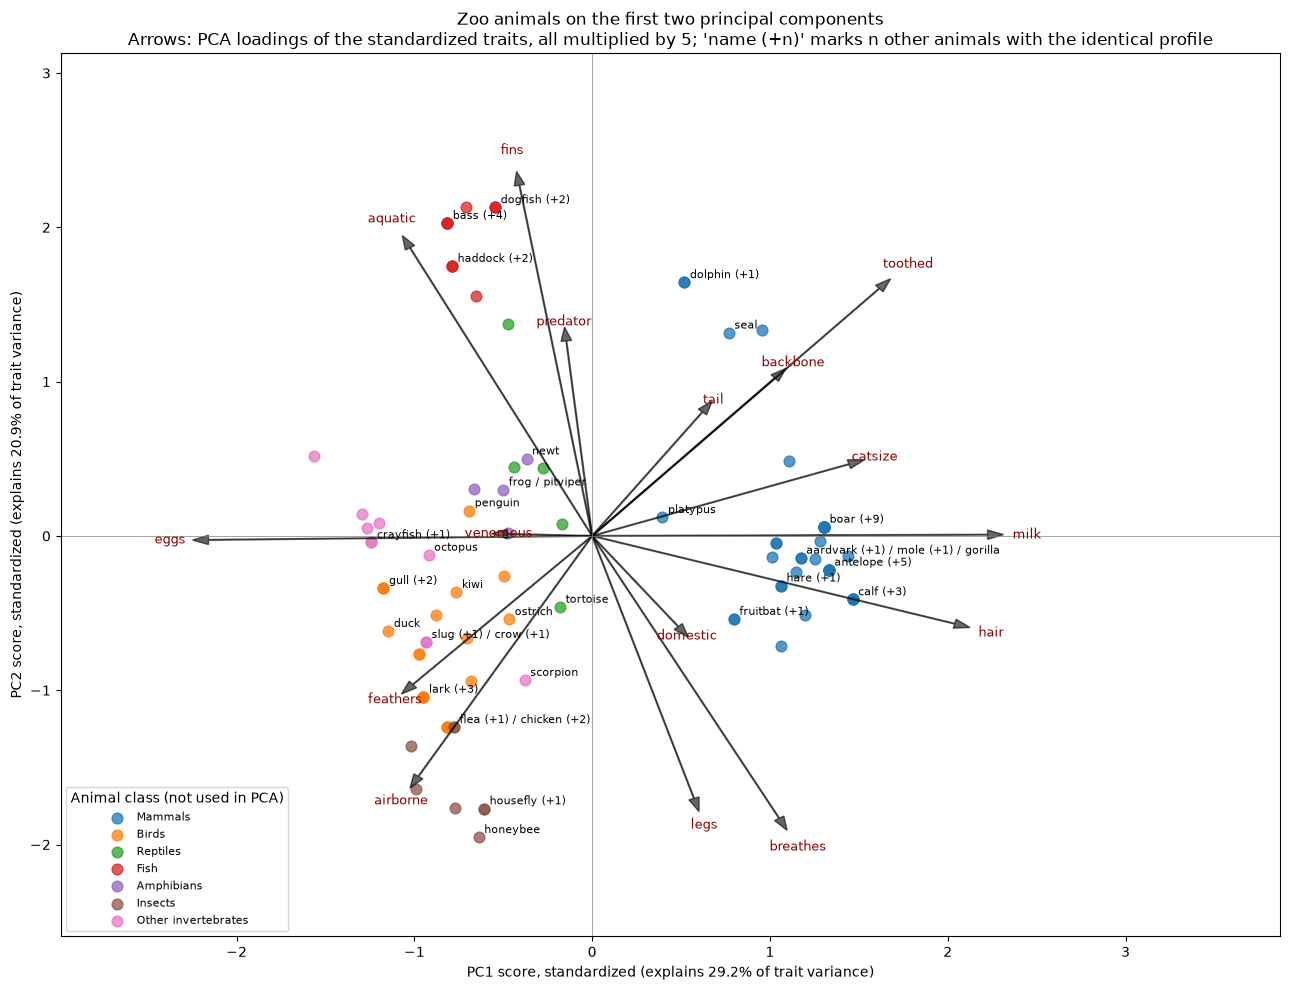

,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,PC1_sd,PC2_sd
animal_name,,,,,,,,,,,,,,,,,,
lion,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1.30,0.06
chicken,0,1,1,0,1,0,0,0,1,1,0,0,2,1,1,0,-0.81,-1.24
bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,-0.81,2.03
housefly,1,0,1,0,1,0,0,0,0,1,0,0,6,0,0,0,-0.61,-1.77
dolphin,0,0,0,1,0,1,1,1,1,1,0,1,0,1,0,1,0.52,1.64
platypus,1,0,1,1,0,1,1,0,1,1,0,0,4,1,0,1,0.40,0.12


In [44]:
# Q4.1: standardized PCA biplot of the 16 animal traits (names/classes are labels only).
zoo_scaler = StandardScaler().fit(zoo[traits])
zoo_z = zoo_scaler.transform(zoo[traits])
zoo_pca = PCA(n_components=2).fit(zoo_z)
zoo_scores = zoo_pca.transform(zoo_z)
scores_sd = zoo_scores / zoo_scores.std(axis=0, ddof=0)
evr = zoo_pca.explained_variance_ratio_
loadings = pd.DataFrame(zoo_pca.components_.T, index=traits, columns=["PC1", "PC2"])
print(f"Explained variance: PC1 {evr[0]:.1%}, PC2 {evr[1]:.1%}, together {evr.sum():.1%}")
display(loadings.round(3).sort_values("PC1"))

# Animals with identical trait profiles land on the same point; label one representative per profile.
profile_groups = zoo.groupby(traits, sort=False).indices
representatives = {}
for rows in profile_groups.values():
    names = zoo.animal_name.iloc[rows].tolist()
    representatives[rows[0]] = names[0] + (f" (+{len(names) - 1})" if len(names) > 1 else "")
print(f"{len(zoo)} animals share {len(profile_groups)} distinct trait profiles.")
print("Shared profiles:", [zoo.animal_name.iloc[r].tolist() for r in profile_groups.values() if len(r) > 1])
# Label every shared profile plus a readable set of distinctive single animals.
extra = ["platypus", "penguin", "octopus", "frog", "scorpion", "tortoise", "honeybee",
         "kiwi", "seal", "duck", "gorilla", "ostrich", "pitviper", "newt"]
label_rows = [r for r in representatives if "(+" in representatives[r]]
label_rows += [zoo.index[zoo.animal_name == n][0] for n in extra if n in set(zoo.animal_name)]

ARROW_SCALE = 5.0
fig, ax = plt.subplots(figsize=(13, 10))
for code, name in classes.items():
    m = zoo["class_type"] == code
    ax.scatter(scores_sd[m, 0], scores_sd[m, 1], s=60, alpha=0.75, label=name)
# Merge labels of profiles that land almost on the same point so the text stays readable.
placed = []  # [x, y, text]
for r in label_rows:
    x, y = scores_sd[r]
    near = [p for p in placed if abs(p[0] - x) < 0.15 and abs(p[1] - y) < 0.15]
    if near:
        near[0][2] += " / " + representatives[r]
    else:
        placed.append([x, y, representatives[r]])
for x, y, text in placed:
    ax.annotate(text, (x, y), xytext=(4, 3), textcoords="offset points", fontsize=8)
for trait, (l1, l2) in loadings.iterrows():
    ax.arrow(0, 0, ARROW_SCALE * l1, ARROW_SCALE * l2, color="black", alpha=0.6, width=0.005, head_width=0.06)
    ax.text(ARROW_SCALE * l1 * 1.1, ARROW_SCALE * l2 * 1.1, trait, color="darkred", fontsize=9, ha="center", va="center")
ends = np.vstack([scores_sd, ARROW_SCALE * 1.2 * loadings.to_numpy()])
ax.set_xlim(ends[:, 0].min() - 0.4, ends[:, 0].max() + 1.2)
ax.set_ylim(ends[:, 1].min() - 0.4, ends[:, 1].max() + 0.4)
ax.axhline(0, color="gray", lw=0.5)
ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel(f"PC1 score, standardized (explains {evr[0]:.1%} of trait variance)")
ax.set_ylabel(f"PC2 score, standardized (explains {evr[1]:.1%} of trait variance)")
ax.set_title(f"Zoo animals on the first two principal components\n"
             f"Arrows: PCA loadings of the standardized traits, all multiplied by {ARROW_SCALE:g}; "
             "'name (+n)' marks n other animals with the identical profile")
ax.legend(title="Animal class (not used in PCA)", fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

def zoo_profile(*names):
    """Trait values and standardized scores for named animals."""
    rows = [zoo.index[zoo.animal_name == n][0] for n in names]
    out = zoo.loc[rows, ["animal_name"] + traits].set_index("animal_name")
    out["PC1_sd"], out["PC2_sd"] = scores_sd[rows, 0], scores_sd[rows, 1]
    return out

display(zoo_profile("lion", "chicken", "bass", "housefly", "dolphin", "platypus").round(2))

In [45]:
grader.check("q4_1")

q4_1 results: All test cases passed!

**Written response — Q4.1**

**Preprocessing and arrows.** We standardized all 16 traits (mean 0, SD 1) so the leg count (0–8) does not dominate the 0/1 traits; names and classes only color and label points. Points are the two PC scores, each divided by its SD. Arrows are the **PCA loadings** of the standardized traits, all multiplied by one factor of 5 (relative lengths preserved). The 101 animals have 59 distinct trait profiles, and identical profiles plot on one point, so we label one representative per shared profile as "name (+n)" (for example "boar (+9)" for ten predator mammals) and merge labels that almost coincide with "/".

**Two directions.** PC1 (29.2% of trait variance) runs from egg-laying animals to mammals: `milk` (+0.45), `hair` (+0.41), `toothed` (+0.32) and `catsize` (+0.29) point right, `eggs` (−0.43) left. PC2 (20.9%) runs from finned water animals at the top (`fins` +0.46, `aquatic` +0.37) to breathing, legged, flying animals at the bottom (`breathes` −0.37, `legs` −0.34, `airborne` −0.31).

**Two comparisons.** *Lion vs chicken:* the lion (with nine other predator mammals) is far right (PC1 ≈ +1.3), the chicken (with dove and parakeet) left (≈ −0.8), matching hair, milk and teeth against feathers and eggs; the chicken is also lower on PC2 (−1.2 against +0.1), mainly because it flies and lacks teeth and predator traits. *Bass vs housefly:* similar PC1 (−0.8, −0.6; both lay eggs and give no milk) but opposite ends of PC2 (+2.0 against −1.8): the bass has fins, lives in water and has teeth; the housefly breathes, has six legs and flies. Loadings describe directions of greatest trait variation, not prediction of a response.

## Q4.2. Explain what the projection leaves out

**3 points**

The animal biplot gives us a two-dimensional view of data described by many traits. A readable plot can nevertheless leave substantial information out, so its apparent similarities and differences need to be interpreted in light of the variance represented by the displayed components.

**Task:** Explain why PCA axes should report explained variance and whether animals close in the projection must be close in full predictor space.

**Artifacts:** Focused written explanation.

**Constraints:** Discuss both visible separation and apparent proximity, and distinguish statements about the plotted coordinates from statements about all 16 traits. No additional scree plot is required.

In [46]:
# Q4.2: compare distances in the 2-D projection with distances over all 16 standardized traits.
from scipy.spatial.distance import pdist, squareform
full_distance = squareform(pdist(zoo_z))
plot_distance = squareform(pdist(zoo_scores))  # unscaled PC scores, same units as zoo_z
iu = np.triu_indices(len(zoo), k=1)
different = full_distance[iu] > 1e-9
print(f"Variance shown by PC1+PC2: {evr.sum():.1%}; left out: {1 - evr.sum():.1%}")
print(f"Correlation of 2-D and 16-D pairwise distances: {np.corrcoef(plot_distance[iu], full_distance[iu])[0, 1]:.3f}")

# Pairs that look close in the plot but differ in many traits.
pairs = pd.DataFrame({"a": zoo.animal_name.to_numpy()[iu[0]], "b": zoo.animal_name.to_numpy()[iu[1]],
                      "plot distance": plot_distance[iu], "16-trait distance": full_distance[iu],
                      "traits that differ": (zoo[traits].to_numpy()[iu[0]] != zoo[traits].to_numpy()[iu[1]]).sum(axis=1)})
close_in_plot = pairs[different & (pairs["plot distance"] < 0.3)].sort_values("16-trait distance", ascending=False)
print("Pairs within 0.3 units in the plot, ranked by full-space distance:")
display(close_in_plot.head(8).round(2))
print(f"Median 16-trait distance over all pairs: {np.median(full_distance[iu]):.2f}")

Variance shown by PC1+PC2: 50.1%; left out: 49.9%
Correlation of 2-D and 16-D pairwise distances: 0.791
Pairs within 0.3 units in the plot, ranked by full-space distance:


,a,b,plot distance,16-trait distance,traits that differ
1121,chicken,termite,0.08,6.06,6
1057,chicken,flea,0.08,6.06,6
2156,flea,parakeet,0.08,6.06,6
1877,dove,termite,0.08,6.06,6
1813,dove,flea,0.08,6.06,6
4134,parakeet,termite,0.08,6.06,6
2306,frog,penguin,0.26,5.87,6
3077,hawk,slug,0.17,5.38,6


Median 16-trait distance over all pairs: 5.85


**Written response — Q4.2**

Axes should report explained variance because it says how much of the data the picture shows: PC1 and PC2 together show 50.1% of the standardized-trait variance, so 49.9%, spread over 14 more directions, is invisible.

**Visible separation.** In unscaled PC units a projection can only shrink distances, so a large separation in the plot is real in 16-trait space. (The plotted scores are divided by SDs above 1, which shrinks the axes but keeps this true.)

**Apparent proximity.** Closeness in the plot does not imply closeness in 16-D, because animals can differ along dropped directions. The chicken/dove/parakeet group and the flea/termite group are 0.08 apart in unscaled PC units yet 6.06 apart across all 16 standardized traits (the median pair distance is 5.85), differing in feathers, airborne, backbone, legs, tail and domestic. Hawk and slug are 0.17 apart in the plot but 5.38 apart in 16-D, and over all pairs the two distances correlate only 0.79. Statements about plotted coordinates are safe; statements about all traits need the omitted variance checked.

## Principal component regression

## PCA for regression: a new dataset

For the final section of the notebook, we switch from animal traits to measurements of cookie dough. The animal example used PCA to visualize relationships among observations. For modeling, PCA offers a related possibility: we can replace many original predictors with a smaller set of principal components and use those components as the inputs to a regression model. This approach is called **principal component regression (PCR)**. We will investigate whether it helps us predict when the original dataset has many more predictors than observations, and how we should decide which components to retain.

The dataset contains near-infrared spectra of cookie-dough samples and their measured sucrose content. Sucrose is sugar; our prediction target is its percentage in each sample. A spectrum consists of measurements taken at different wavelengths of light. Each sample has 700 recorded wavelength measurements, from 1100 through 2498 nm. These measurements are our predictors, and sucrose percentage is the response.

There are many more predictors than samples, making this a useful setting for examining what PCA can contribute to regression. The source provides 40 calibration samples for developing models and 32 separate prediction samples for final evaluation. The supplied loader excludes calibration observation 23, documented as an outlier, leaving 39 development samples. We will use cross-validation within those 39 samples to compare and select models, keeping the prediction batch reserved until Q4.10. See [the fds dataset documentation](https://search.r-project.org/CRAN/refmans/fds/html/Biscuit.html), citing Brown, Fearn, and Vannucci (2001).

The loading cell below creates `cookie_X`, the sample-by-wavelength predictor array; `cookie_y`, the matching sucrose percentages; and `wavelengths`, the wavelength corresponding to each predictor column. It also supplies `cookie_folds` for calibration cross-validation. These are the data used in Q4.3–Q4.9.

Each wavelength is centered using its fitting-sample mean; wavelengths share a measurement scale and are not individually scaled to unit variance. Validation/test observations reuse those fitted means. Names/classes in the preceding animal example were metadata; here sucrose is the response and is excluded from PCA fitting.

In Q4.5–Q4.9, adapt earlier methods where appropriate or justify an alternative. State the question answered, assumptions, evidence, and limitations. Chemical expertise or mechanism explanations are not expected. A valid analysis need not beat the baseline or give a clean original-input interpretation. Null-based significance is optional. Automated checks do not enforce a specific algorithm or selected set.


In [47]:
# Supplied loading and fixed calibration folds; no prediction-batch access.
# The loader omits documented calibration observation 23 (one-based).
cookie_X, cookie_y, wavelengths = load_cookie()
cookie_folds = fixed_folds(len(cookie_y), seed=109)


## Q4.3. Diagnose the original regression and coordinate change

**2 points**

The animal example showed how PCA can summarize predictors for visualization. With the cookie-dough spectra, we now consider whether those coordinates can also help us build a regression model when there are many more measurements than calibration samples. Comparing original-space OLS with OLS using all available principal components helps distinguish a change of coordinates from a reduction in model complexity.

**Task:** Examine original-space OLS training/CV behavior and dimensions/rank. Show that two least-squares fits give the same predictions: one on the centered original spectra, and one on all principal components whose singular values exceed the tolerance below. Use matching minimum-norm numerical conventions.

**Artifacts:** Diagnosis table, prediction-equivalence comparison, and an explanation of what equivalence shows about whether a change to PCA coordinates by itself constrains the fit.

**Constraints:** Describe the observed training and CV errors without assuming that original-space regression must perform poorly. Use matching centering, rank tolerance, and minimum-norm conventions in the equivalence comparison. With more predictors than fitting observations, individual unregularized coefficients need not be uniquely determined.

**Output names for the guided checks:** `equivalence`, a list of floats: the largest absolute prediction difference for the full-calibration fit and for each fold’s held-out predictions.

Use the supplied `cookie_folds` for calibration cross-validation. Use `np.linalg.lstsq(..., rcond=1e-10)` for the original centered design. For each fitting sample, retain only singular values above `largest_singular_value * 1e-10` when forming its PCA regression. Centering 39 rows leaves at most 38 nonzero directions. In this setting the original coefficients are not unique; the supplied least-squares convention returns the solution with the smallest sum of squared coefficients. This comparison is about equivalent predictions under a specified numerical convention.


In [48]:
# Q4.3: original-space least squares versus regression on every nonzero principal component.
def center_fit(x):
    """Return the column means of the fitting spectra."""
    return x.mean(axis=0)


def original_ols(x_fit, y_fit, x_eval):
    """Minimum-norm least squares on centered spectra; intercept = mean response."""
    mean = center_fit(x_fit)
    beta = np.linalg.lstsq(x_fit - mean, y_fit - y_fit.mean(), rcond=1e-10)[0]
    return (x_eval - mean) @ beta + y_fit.mean(), beta


def fit_pca(x_fit, tol=1e-10):
    """Centering and SVD of the fitting spectra; keep singular values above tol * largest."""
    mean = center_fit(x_fit)
    _, s, vt = np.linalg.svd(x_fit - mean, full_matrices=False)
    keep = s > s[0] * tol
    return {"mean": mean, "components": vt[keep], "singular_values": s[keep],
            "share": s[keep] ** 2 / np.sum(s ** 2)}


def pcr_all(x_fit, y_fit, x_eval):
    """Least squares on all retained principal-component scores."""
    pca = fit_pca(x_fit)
    scores = (x_fit - pca["mean"]) @ pca["components"].T
    gamma = np.linalg.lstsq(scores, y_fit - y_fit.mean(), rcond=1e-10)[0]
    return (x_eval - pca["mean"]) @ pca["components"].T @ gamma + y_fit.mean(), pca


centered = cookie_X - cookie_X.mean(axis=0)
full_pred, _ = original_ols(cookie_X, cookie_y, cookie_X)
pcr_full_pred, pca_full_all = pcr_all(cookie_X, cookie_y, cookie_X)
equivalence = [float(np.max(np.abs(full_pred - pcr_full_pred)))]
diagnosis_rows = [{"fit": "all calibration", "fitting rows": len(cookie_y), "predictors": cookie_X.shape[1],
                   "rank (centered)": int(np.linalg.matrix_rank(centered, tol=np.linalg.svd(centered, compute_uv=False)[0] * 1e-10)),
                   "PCs kept": len(pca_full_all["singular_values"]),
                   "train RMSE": rmse(cookie_y, full_pred), "held-out RMSE": np.nan}]
cv_pred = np.empty(len(cookie_y))
for fold, (tr, va) in enumerate(cookie_folds):
    orig_va, _ = original_ols(cookie_X[tr], cookie_y[tr], cookie_X[va])
    orig_tr, _ = original_ols(cookie_X[tr], cookie_y[tr], cookie_X[tr])
    pcr_va, pca_fold = pcr_all(cookie_X[tr], cookie_y[tr], cookie_X[va])
    cv_pred[va] = orig_va
    equivalence.append(float(np.max(np.abs(orig_va - pcr_va))))
    c_tr = cookie_X[tr] - cookie_X[tr].mean(axis=0)
    diagnosis_rows.append({"fit": f"fold {fold}", "fitting rows": len(tr), "predictors": cookie_X.shape[1],
                           "rank (centered)": int(np.linalg.matrix_rank(c_tr, tol=np.linalg.svd(c_tr, compute_uv=False)[0] * 1e-10)),
                           "PCs kept": len(pca_fold["singular_values"]),
                           "train RMSE": rmse(cookie_y[tr], orig_tr), "held-out RMSE": rmse(cookie_y[va], orig_va)})
cookie_diagnosis = pd.DataFrame(diagnosis_rows)
display(cookie_diagnosis)
print(f"Original-space OLS: pooled CV RMSE = {rmse(cookie_y, cv_pred):.3f} sucrose percentage points "
      f"(response SD = {cookie_y.std():.3f}, range {cookie_y.min():.2f}-{cookie_y.max():.2f}%)")
print("Largest |prediction difference| (full fit, then folds 0-4):", [f"{e:.2e}" for e in equivalence])

,fit,fitting rows,predictors,rank (centered),PCs kept,train RMSE,held-out RMSE
0,all calibration,39,700,38,38,4.431773e-14,NaN
1,fold 0,31,700,30,30,1.528416e-13,1.083646
2,fold 1,31,700,30,30,5.531420e-14,0.988737
3,fold 2,31,700,30,30,6.919779e-14,1.499385
4,fold 3,31,700,30,30,3.058490e-14,1.529392
5,fold 4,32,700,31,31,2.977551e-14,1.689041


Original-space OLS: pooled CV RMSE = 1.376 sucrose percentage points (response SD = 3.907, range 9.95-23.11%)
Largest |prediction difference| (full fit, then folds 0-4): ['4.80e-14', '7.78e-13', '4.97e-14', '5.68e-14', '3.20e-14', '7.28e-14']


In [49]:
grader.check("q4_3")

q4_3 results: All test cases passed!

**Written response — Q4.3**

**Diagnosis.** The design has 39 spectra and 700 wavelengths; after centering its rank is 38 (30 or 31 in the CV fitting samples). Least squares fits every training sample exactly (training RMSE about 10⁻¹³) and the coefficients are not unique: infinitely many vectors interpolate, and `lstsq` returns the one with the smallest sum of squares. That minimum-norm fit still predicts held-out samples reasonably (pooled CV RMSE 1.38 sucrose points, folds 0.99–1.69, against a response SD of 3.91), so original-space regression is not hopeless here.

**Equivalence.** Least squares on the centered spectra and on all principal components with singular values above 10⁻¹⁰ × the largest give the same predictions: the largest absolute differences are 4.8×10⁻¹⁴ (full fit) and 3.2×10⁻¹⁴ to 7.8×10⁻¹³ (the five held-out folds), which is rounding error. Keeping every nonzero component only rotates the same column space (scores = XV), leaving residuals and coefficient length unchanged. A change to PCA coordinates therefore does **not** by itself constrain the fit; PCR simplifies the model only when components are dropped.

## Q4.4. Establish the 95%-variance PCR baseline

**3 points**

Using every available principal component does not by itself simplify the fitted regression. Retaining fewer components offers a way to reduce the number of directions used for prediction. A common starting rule is to retain enough components to explain 95% of predictor variance; the scree and cumulative-variance plots let us see what that rule keeps and what it discards.

**Task:** Plot the variance explained by each component and the cumulative explained variance. Find the smallest number of leading components that explains at least 95% on the full calibration data. Evaluate the corresponding PCR procedure using `cookie_folds`, relearning PCA and the 95% component count within each fitting fold.

**Artifacts:** Variance plot, full-calibration component count, CV performance, and an explanation of what information the 95% rule uses and what it ignores.

**Constraints:** Refit centering, PCA, and the 95% component count inside each fitting fold. Do not score models on the prediction batch.

**Output names for the guided checks:** `share`, the explained-variance ratios, and `k95`, the smallest qualifying component count.


Full calibration: k95 = 2 components explain 98.33% of spectral variance


,share,cumulative
component,,
1,0.93521,0.93521
2,0.04807,0.98328
3,0.00728,0.99056
4,0.00437,0.99493
5,0.00278,0.99771
6,0.00095,0.99866
7,0.00063,0.99930
8,0.00018,0.99948
9,0.00011,0.99959


,fold,k95,held-out RMSE
0,0,2,3.205
1,1,2,3.223
2,2,2,4.078
3,3,2,4.269
4,4,2,2.843


95%-variance PCR: pooled CV RMSE = 3.583 sucrose percentage points (predicting the mean gives about 3.907)


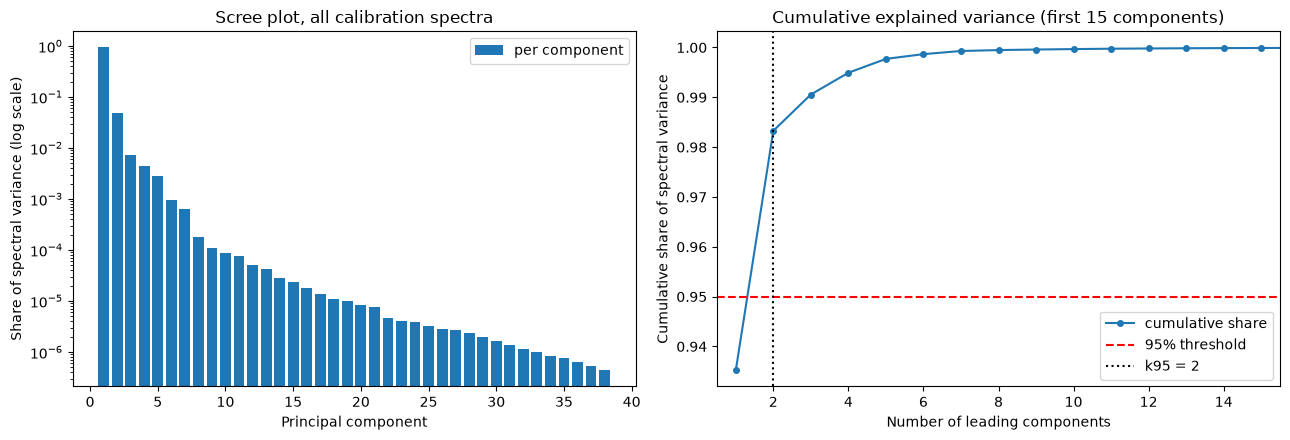

In [50]:
# Q4.4: explained variance and the 95%-variance PCR baseline.
share = pca_full_all["share"]
k95 = int(np.searchsorted(np.cumsum(share), 0.95) + 1)
print(f"Full calibration: k95 = {k95} components explain {np.cumsum(share)[k95 - 1]:.2%} of spectral variance")
display(pd.DataFrame({"share": share[:10], "cumulative": np.cumsum(share)[:10]},
                     index=pd.RangeIndex(1, 11, name="component")).round(5))


def pcr_k95(x_fit, y_fit, x_eval):
    """Relearn centering, PCA and the 95% component count from the fitting rows, then OLS."""
    pca = fit_pca(x_fit)
    k = int(np.searchsorted(np.cumsum(pca["share"]), 0.95) + 1)
    z_fit = (x_fit - pca["mean"]) @ pca["components"][:k].T
    model = LinearRegression().fit(z_fit, y_fit)
    return model.predict((x_eval - pca["mean"]) @ pca["components"][:k].T), k


baseline_pred = np.empty(len(cookie_y))
baseline_rows = []
for fold, (tr, va) in enumerate(cookie_folds):
    baseline_pred[va], k_fold = pcr_k95(cookie_X[tr], cookie_y[tr], cookie_X[va])
    baseline_rows.append({"fold": fold, "k95": k_fold, "held-out RMSE": rmse(cookie_y[va], baseline_pred[va])})
display(pd.DataFrame(baseline_rows).round(3))
baseline_cv_rmse = rmse(cookie_y, baseline_pred)
print(f"95%-variance PCR: pooled CV RMSE = {baseline_cv_rmse:.3f} sucrose percentage points "
      f"(predicting the mean gives about {cookie_y.std():.3f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
comp = np.arange(1, len(share) + 1)
axes[0].bar(comp, share, color="tab:blue", label="per component")
axes[0].set_yscale("log")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Share of spectral variance (log scale)")
axes[0].set_title("Scree plot, all calibration spectra")
axes[0].legend()
axes[1].plot(comp, np.cumsum(share), marker="o", ms=4, label="cumulative share")
axes[1].axhline(0.95, color="red", ls="--", label="95% threshold")
axes[1].axvline(k95, color="black", ls=":", label=f"k95 = {k95}")
axes[1].set_xlim(0.5, 15.5)
axes[1].set_xlabel("Number of leading components")
axes[1].set_ylabel("Cumulative share of spectral variance")
axes[1].set_title("Cumulative explained variance (first 15 components)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [51]:
grader.check("q4_4")

q4_4 results: All test cases passed!

**Written response — Q4.4**

Spectral variance is extremely concentrated: PC1 explains 93.5%, PC2 4.8% and PC3–PC6 together about 1.5%. On the full calibration data **k95 = 2** (98.3%), and every CV fitting fold also chose 2. The resulting PCR predicts poorly: pooled CV RMSE is **3.58** sucrose points (folds 2.84–4.27), barely better than predicting the mean (SD 3.91) and far worse than minimum-norm regression on all components (1.38).

The 95% rule uses only the spectra: it keeps the directions of greatest absorbance variation, presumably overall intensity and baseline differences between doughs, and ignores sucrose entirely. Nothing guarantees that the leading components carry the sucrose signal: using all components cuts CV RMSE from 3.58 to 1.38 (Q4.3), so the useful information also sits in discarded components that each explain under 1% of the variance. A variance threshold describes the predictors; it is not a model-selection criterion for a response.

<!-- BEGIN QUESTION -->

## Q4.5. Select components using predictive evidence

**4 points**

The 95% rule chooses components using the spectra alone, without considering sucrose percentage. Directions that explain substantial variation in the measurements need not be the directions most useful for predicting the response. We can now draw on the earlier modeling work to develop and evaluate a component-selection approach that uses predictive evidence.

**Task:** Propose, justify and implement a predictive component-selection strategy and compare predictions on the same outer held-out observations in `cookie_folds` as the baseline. Any tuning must occur inside each outer fitting sample.

**Artifacts:** Selection rationale, selected component count or set and predictive evidence.

**Constraints:** You may adapt a method used earlier or propose another suitable method. Explain how prediction performance informs your component choice. You may consider components beyond the 95% cutoff. Fit transformations and tune choices using only the relevant fitting data, and compare methods on common held-out observations. A justified method can receive full credit even if it does not improve on the baseline.

**Written response — Q4.5**

**Method.** We select components with the lasso on the **standardized PC scores** of all available components (30–31 per outer fitting sample, 38 on the full calibration). It adapts Q2.2 and can keep a lower-variance component while skipping a leading one, which matters because Q4.4 showed useful information beyond the leading two components. Dividing each score by its fitting-sample SD gives every direction equal footing under the penalty (PC1's raw scores are about 100 times larger than PC10's). Within each outer fitting sample the penalty is tuned over `logspace(0, −4, 41)` by 5-fold inner CV (minimum pooled-MSE rule), refitting centering, PCA and score scaling in every inner fold, so outer held-out samples never influence the transformation, penalty or selection.

**Evidence** (same outer `cookie_folds`):

| procedure | pooled CV RMSE (sucrose %) |
|---|---:|
| original-space min-norm OLS | 1.38 |
| 95%-variance PCR (k = 2) | 3.58 |
| **lasso on standardized PC scores** | **1.10** |

The lasso beats the baseline in every fold (for example 0.71 against 3.21 in fold 0) and has smaller squared error on 35 of 39 held-out samples. Inner CV chose penalties of 0.13–0.20 and kept 12–18 components per fold, always PCs 1–7 except PC4 in fold 4. On all 39 samples the frozen procedure chose α = 0.079 and **20 components**: PCs 1–7, 10, 11, 13, 14, 17, 20, 22, 24, 25, 31, 32, 33 and 36. Prediction performance drives the choice at both levels (the penalty minimizes inner-CV error; a component stays only if it improves the penalized fit to sucrose), at the cost that tiny-variance components, which may be mostly noise, get the same chance as real signal; Q4.6 checks the high-index selections.

,fold,alpha,components selected,selected (1-based),lasso RMSE,95% baseline RMSE
0,0,0.126,18,"[1, 2, 3, 4, 5, 6, 7, 8, 11, 12, 13, 17, 20, 22, 24, 25, 26, 27]",0.710,3.205
1,1,0.200,12,"[1, 2, 3, 4, 5, 6, 7, 10, 13, 19, 22, 26]",0.748,3.223
2,2,0.158,12,"[1, 2, 3, 4, 5, 6, 7, 11, 12, 13, 22, 28]",1.428,4.078
3,3,0.158,13,"[1, 2, 3, 4, 5, 6, 7, 9, 12, 19, 21, 25, 30]",1.204,4.269
4,4,0.126,16,"[1, 2, 3, 5, 6, 7, 9, 10, 12, 13, 14, 16, 22, 25, 27, 30]",1.225,2.843


,pooled CV RMSE,components
original-space OLS,1.376,all (min-norm OLS)
95%-variance PCR,3.583,leading k95 per fold
lasso on PC scores,1.097,lasso-selected per fold


Lasso has smaller squared error on 35 of 39 held-out samples.
All calibration: alpha = 0.07943; 20 components selected (1-based): [1, 2, 3, 4, 5, 6, 7, 10, 11, 13, 14, 17, 20, 22, 24, 25, 31, 32, 33, 36]


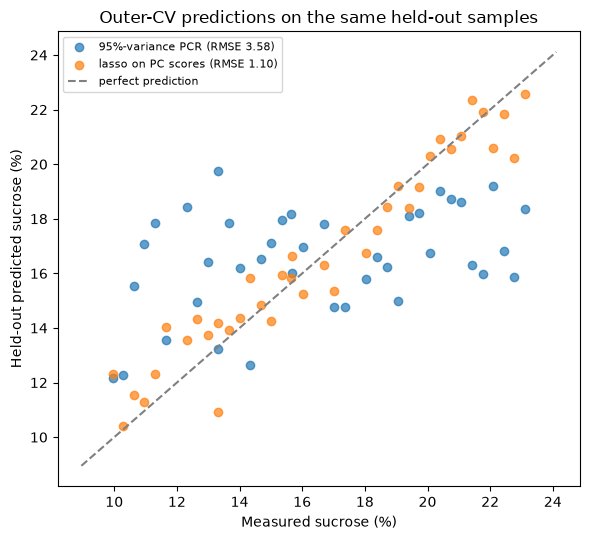

In [52]:
# Q4.5: lasso on standardized PC scores, penalty tuned by inner CV inside each outer fitting sample.
COOKIE_ALPHAS = np.logspace(0, -4, 41)
COOKIE_LASSO = {"max_iter": 200_000, "tol": 1e-8}


def score_transform(pca, scale, x):
    """Project spectra onto fixed components and divide by fixed score SDs."""
    return ((x - pca["mean"]) @ pca["components"].T) / scale


def tune_score_lasso(z, y, folds, alphas=COOKIE_ALPHAS, x=None):
    """Pooled-MSE lasso tuning. If x is given, refit PCA and scaling inside each inner fold."""
    squared = np.zeros(len(alphas))
    for itr, iva in folds:
        if x is not None:
            pca_i = fit_pca(x[itr])
            raw = (x[itr] - pca_i["mean"]) @ pca_i["components"].T
            scale_i = raw.std(axis=0)
            z_tr, z_va = raw / scale_i, score_transform(pca_i, scale_i, x[iva])
        else:
            z_tr, z_va = z[itr], z[iva]
        model = Lasso(alpha=alphas[0], warm_start=True, **COOKIE_LASSO)
        for i, a in enumerate(alphas):
            model.set_params(alpha=a)
            model.fit(z_tr, y[itr])
            squared[i] += np.sum((y[iva] - model.predict(z_va)) ** 2)
    mse = squared / sum(len(iva) for _, iva in folds)
    return float(alphas[int(np.argmin(mse))]), mse


def fit_pcr_lasso(x_fit, y_fit, inner_folds):
    """Full procedure on one fitting sample: PCA, score scaling, inner-CV penalty, lasso refit."""
    pca = fit_pca(x_fit)
    raw = (x_fit - pca["mean"]) @ pca["components"].T
    scale = raw.std(axis=0)
    alpha, mse = tune_score_lasso(None, y_fit, inner_folds, x=x_fit)
    model = Lasso(alpha=alpha, **COOKIE_LASSO).fit(raw / scale, y_fit)
    return {"pca": pca, "scale": scale, "alpha": alpha, "model": model, "mse": mse,
            "selected": np.flatnonzero(np.abs(model.coef_) > 1e-8)}


def predict_pcr_lasso(fit, x):
    """Predict sucrose for spectra x with a fitted PCA-lasso procedure."""
    return fit["model"].predict(score_transform(fit["pca"], fit["scale"], x))


lasso_pred = np.empty(len(cookie_y))
outer_fits = []
outer_rows = []
for fold, (tr, va) in enumerate(cookie_folds):
    fit = fit_pcr_lasso(cookie_X[tr], cookie_y[tr], fixed_folds(len(tr), seed=209))
    outer_fits.append(fit)
    lasso_pred[va] = predict_pcr_lasso(fit, cookie_X[va])
    outer_rows.append({"fold": fold, "alpha": fit["alpha"], "components selected": len(fit["selected"]),
                       "selected (1-based)": (fit["selected"] + 1).tolist(),
                       "lasso RMSE": rmse(cookie_y[va], lasso_pred[va]),
                       "95% baseline RMSE": rmse(cookie_y[va], baseline_pred[va])})
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(outer_rows).round(3))
lasso_cv_rmse = rmse(cookie_y, lasso_pred)
pcr_comparison = pd.DataFrame(
    {"pooled CV RMSE": [rmse(cookie_y, cv_pred), baseline_cv_rmse, lasso_cv_rmse],
     "components": ["all (min-norm OLS)", "leading k95 per fold", "lasso-selected per fold"]},
    index=["original-space OLS", "95%-variance PCR", "lasso on PC scores"],
)
display(pcr_comparison.round(3))
paired = (cookie_y - baseline_pred) ** 2 - (cookie_y - lasso_pred) ** 2
print(f"Lasso has smaller squared error on {int((paired > 0).sum())} of {len(cookie_y)} held-out samples.")

# The frozen procedure refitted on all calibration samples (used in Q4.6-Q4.10).
cookie_final = fit_pcr_lasso(cookie_X, cookie_y, fixed_folds(len(cookie_y), seed=209))
print(f"All calibration: alpha = {cookie_final['alpha']:.4g}; {len(cookie_final['selected'])} components selected "
      f"(1-based): {(cookie_final['selected'] + 1).tolist()}")

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(cookie_y, baseline_pred, label=f"95%-variance PCR (RMSE {baseline_cv_rmse:.2f})", alpha=0.7)
ax.scatter(cookie_y, lasso_pred, label=f"lasso on PC scores (RMSE {lasso_cv_rmse:.2f})", alpha=0.7)
lims = [cookie_y.min() - 1, cookie_y.max() + 1]
ax.plot(lims, lims, color="gray", ls="--", label="perfect prediction")
ax.set_xlabel("Measured sucrose (%)")
ax.set_ylabel("Held-out predicted sucrose (%)")
ax.set_title("Outer-CV predictions on the same held-out samples")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## Q4.6. Assess selection stability

**3 points**

The response-informed procedure selected components using one calibration sample. Before interpreting that choice, we need evidence about whether it is sensitive to changes in the observations used for fitting. A stability assessment appropriate to your chosen method can help establish which selection conclusions are reproducible and which depend strongly on this sample.

**Task:** Choose, justify, and implement a stability assessment appropriate to your component-selection method. You may adapt the earlier analysis or propose an alternative. If you use resampling (e.g., bootstrap), hold the fitted PCA transformation and any score scaling your method uses fixed and repeat the downstream selection or tuning appropriate to your method.

**Artifacts:** Method-appropriate stability plot/table and interpretation.

**Constraints:** When calculating selection frequencies, allow the selected subset to vary across resamples; hold the PCA transformation fixed, not the selection result. Specify what is repeated and what remains fixed.

If your resampling assessment includes CV tuning, use `bootstrap_folds` as in Q3.1 so copies of a calibration sample stay in the same fold. You may use `B_SELECTION` as the supplied resampling count. Methods without discrete selection may assess variation in their chosen model size or predictions instead; explain what your assessment measures.

If you use bootstrap resampling, pass the resampled calibration-row positions `idx` as the `ids` argument to `bootstrap_folds`; these positions identify original samples, including repeated copies.


**Written response — Q4.6**

**Fixed and repeated.** We held the full-calibration PCA fixed (centering, 38 directions, score SDs). In each of 100 bootstrap resamples of the 39 samples we retuned the penalty by 5-fold CV with `bootstrap_folds` (copies of a sample share a fold), refit the lasso and recorded which fixed components are nonzero, letting the set vary.

**Results.** Only the six leading components are reproducible: PC3 and PC5 in 100% of resamples, PC1 99%, PC6 84%, PC2 83%, PC4 80%. Frequencies then fall to 68% (PC10), 60% (PC7, which every Q4.5 outer fold kept, and PC32) and below 60% for the rest. The set size ranges from 3 to 27 (median 17) and the penalty spans three orders of magnitude (10th–90th percentile 2.5×10⁻⁴ to 0.32), so the CV curve on 39 samples is poorly determined. Of the full-calibration model's 20 components, six are stable and fourteen (including PCs 31, 32, 33 and 36, which explain almost no variance) depend strongly on which samples are drawn.

**Conclusion.** "The model relies on PCs 1–6" is reproducible; the higher-order set should not be interpreted. Holding the PCA fixed means these frequencies understate total instability (Extension 2).

Saved fresh bootstrap results to cache.


,component,variance share,selection frequency,selected in full fit
4,5,0.0028,1.00,True
2,3,0.0073,1.00,True
0,1,0.9352,0.99,True
5,6,0.0010,0.84,True
1,2,0.0481,0.83,True
3,4,0.0044,0.80,True
9,10,0.0001,0.68,True
6,7,0.0006,0.60,True
31,32,0.0000,0.60,True
12,13,0.0000,0.59,True


Components selected in at least 80% of resamples: [1, 2, 3, 4, 5, 6]
Selected-set size across resamples: median 17, range 3-27; full fit 20
Bootstrap penalties: median 0.1, 10-90% range 0.000246-0.316; full fit 0.0794


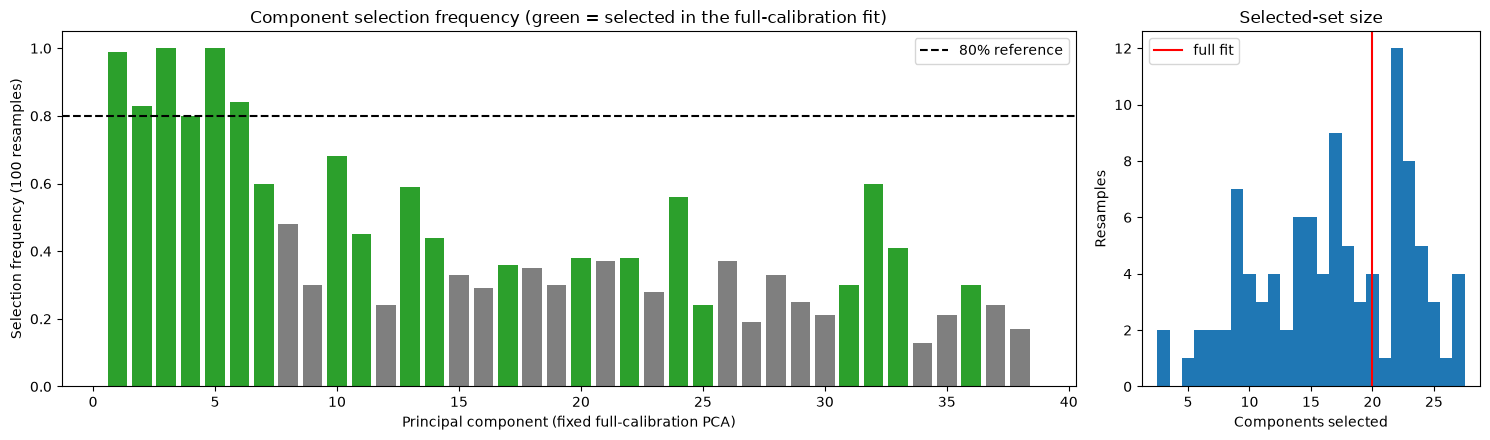

In [53]:
# Q4.6: bootstrap stability of the lasso component selection, PCA and score scaling held fixed.
fixed_pca = cookie_final["pca"]
fixed_scale = cookie_final["scale"]
fixed_scores = score_transform(fixed_pca, fixed_scale, cookie_X)
n_components = fixed_scores.shape[1]


def cookie_selection_bootstrap():
    """Resample calibration rows; retune and refit the lasso on the fixed standardized scores."""
    rng = np.random.default_rng(SELECTION_BOOTSTRAP_SEED)
    n = len(cookie_y)
    alphas = np.empty(B_SELECTION)
    selected = np.zeros((B_SELECTION, n_components), dtype=bool)
    for b in range(B_SELECTION):
        idx = rng.integers(0, n, size=n)
        folds_b = bootstrap_folds(idx, seed=109 + b)  # copies of a sample share a fold
        alpha_b, _ = tune_score_lasso(fixed_scores[idx], cookie_y[idx], folds_b)
        model_b = Lasso(alpha=alpha_b, **COOKIE_LASSO).fit(fixed_scores[idx], cookie_y[idx])
        alphas[b] = alpha_b
        selected[b] = np.abs(model_b.coef_) > 1e-8
    return {"alpha": alphas, "selected": selected}


cookie_cache = cached_bootstrap_results(
    cookie_selection_bootstrap,
    cache_path="cache/q4_6_cookie_selection_bootstrap.npz",
    X=cookie_X,
    y=cookie_y,
    settings={
        "implementation_version": "q4_6-v1",
        "B_SELECTION": B_SELECTION,
        "seed": SELECTION_BOOTSTRAP_SEED,
        "fold_seed_base": 109,
        "COOKIE_ALPHAS": COOKIE_ALPHAS,
        "COOKIE_LASSO": COOKIE_LASSO,
        "fixed_scale": fixed_scale,
        "pca_tol": 1e-10,
    },
    dependencies=[tune_score_lasso, score_transform, fit_pca, center_fit, bootstrap_folds],
    force=REFRESH_BOOTSTRAP_CACHE,
)
component_frequency = cookie_cache["selected"].mean(axis=0)
component_nonzero = cookie_cache["selected"].sum(axis=1)
cookie_stability = pd.DataFrame(
    {"component": np.arange(1, n_components + 1), "variance share": fixed_pca["share"],
     "selection frequency": component_frequency,
     "selected in full fit": np.isin(np.arange(n_components), cookie_final["selected"])}
)
display(cookie_stability[cookie_stability["selection frequency"] > 0].sort_values("selection frequency", ascending=False).round(4).head(25))
print(f"Components selected in at least 80% of resamples: "
      f"{(np.flatnonzero(component_frequency >= 0.8) + 1).tolist()}")
print(f"Selected-set size across resamples: median {np.median(component_nonzero):.0f}, "
      f"range {component_nonzero.min()}-{component_nonzero.max()}; full fit {len(cookie_final['selected'])}")
print(f"Bootstrap penalties: median {np.median(cookie_cache['alpha']):.3g}, "
      f"10-90% range {np.percentile(cookie_cache['alpha'], 10):.3g}-{np.percentile(cookie_cache['alpha'], 90):.3g}; "
      f"full fit {cookie_final['alpha']:.3g}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [3, 1]})
colors_sel = np.where(cookie_stability["selected in full fit"], "tab:green", "tab:gray")
axes[0].bar(cookie_stability.component, component_frequency, color=colors_sel)
axes[0].axhline(0.8, color="black", ls="--", label="80% reference")
axes[0].set_xlabel("Principal component (fixed full-calibration PCA)")
axes[0].set_ylabel(f"Selection frequency ({B_SELECTION} resamples)")
axes[0].set_title("Component selection frequency (green = selected in the full-calibration fit)")
axes[0].legend()
axes[1].hist(component_nonzero, bins=np.arange(component_nonzero.min() - 0.5, component_nonzero.max() + 1.5), color="tab:blue")
axes[1].axvline(len(cookie_final["selected"]), color="red", label="full fit")
axes[1].set_xlabel("Components selected")
axes[1].set_ylabel("Resamples")
axes[1].set_title("Selected-set size")
axes[1].legend()
plt.tight_layout()
plt.show()

<!-- END QUESTION -->

## AC209A Extension 2. Explain the staff’s stability procedure (AC209A only)

**4 points**

The staff deliberately specified a different approach to the bootstrap stability analysis here than in the earlier dataset. What would be problematic about applying the earlier approach directly in this setting? Explain your reasoning, and explain what the specified analysis measures and what it leaves out.

**Artifact:** A short conceptual explanation.

In [54]:
# The required answer is the written explanation below.
# It does not refit PCA or run another bootstrap.


**Written response — AC209A Extension 2**

In Q3.1 every resample could refit preprocessing because an Ames column keeps its identity: `Gr_Liv_Area` is the same feature every time. A principal component does not. It is a direction learned from the rows in that fit, so component j of a refitted PCA is not the same object as component j of the original PCA.

Copying the Q3.1 approach here would break the comparison in three ways. The direction numbered j can rotate when some of the 39 spectra are repeated or dropped. Component signs are arbitrary, so a coefficient on "PC j" cannot be lined up across resamples. A resample of 39 rows repeats spectra, so the centered matrix has fewer than 38 nonzero components and a high-index score often does not exist.

The specified analysis holds the full-calibration PCA and the score scaling fixed, then repeats only the penalty tuning and the lasso. It measures how the selected set changes when the calibration rows change and the coordinates stay put. It does not measure uncertainty in the loadings. With 39 spectra that omitted piece is real, which is why Q4.7 refits centering and PCA inside each resample when the claim is about predictions.


<!-- BEGIN QUESTION -->

## Q4.7. Quantify uncertainty

**3 points**

Selection stability addresses whether the procedure repeatedly retains similar components. It does not establish how precisely their effects, or the resulting predictions, are estimated. An uncertainty assessment helps determine how strongly the data support the claims you intend to make about your chosen model.

**Task:** Choose and implement an uncertainty analysis for a clearly stated claim about coefficients or predictions. You may adapt an earlier method or propose a suitable alternative. Explain why the method answers your question and use its results to qualify the claim.

**Artifacts:** Interval or distribution evidence and interpretation of what it captures.

**Constraints:** State which fitting choices remain fixed and which sources of uncertainty your analysis includes. Intervals from OLS fitted after outcome-based selection on the same observations do not automatically account for that selection.

**Written response — Q4.7**

**Claim.** For a typical calibration spectrum, the frozen procedure's prediction moves by about ±1 sucrose percentage point when the whole procedure is rerun on another calibration sample of the same size.

**Method.** We bootstrapped the entire procedure 200 times. Each resample refits centering, PCA and score scaling, retunes the penalty by grouped CV, reselects components and refits the lasso, then predicts all 39 spectra. The 95% intervals are the 2.5th and 97.5th percentiles. Fixed choices are the penalty grid, 5-fold grouped CV with the minimum pooled-MSE rule, and the lasso on standardized scores. Because selection is repeated in every resample, the intervals include the outcome-based component selection.

**Results.** The median interval width is **2.1** points (range 1.3–5.3; median bootstrap SD 0.55), which is the ±1 in the claim. Widths are larger at the ends of the sucrose range, and the bootstrap means are pulled toward the middle.

**Scope.** Included: sampling variability of the calibration rows through every fitting choice. Not included: measurement noise in a new sucrose reading, so these are not intervals for a future assay. Many resamples still contain the spectrum being predicted, so ±1 describes refits that often saw that spectrum.


,sample,measured,frozen-fit prediction,bootstrap mean,bootstrap sd,lower,upper,width
0,0,13.32,14.220,13.999,0.527,13.320,15.065,1.745
1,1,15.65,15.617,15.754,0.362,15.095,16.469,1.374
2,2,19.06,18.548,18.309,0.565,17.169,19.060,1.891
3,3,19.40,19.286,18.865,0.565,17.624,19.535,1.912
4,4,15.35,15.024,15.571,0.747,14.375,17.562,3.187
5,5,12.31,12.488,13.034,0.666,12.307,14.735,2.428
6,6,9.95,10.735,11.234,1.335,9.951,14.632,4.681
7,7,22.77,22.159,21.375,1.018,19.366,22.769,3.403
8,8,20.75,20.526,20.728,0.502,19.872,22.085,2.212
9,9,15.69,15.723,15.621,0.460,14.762,16.563,1.801


95% procedure-bootstrap interval width: median 2.08, range 1.27-5.31 percentage points
Bootstrap SD of a fitted prediction: median 0.55 points
Components selected across procedure resamples: median 16, range 6-26


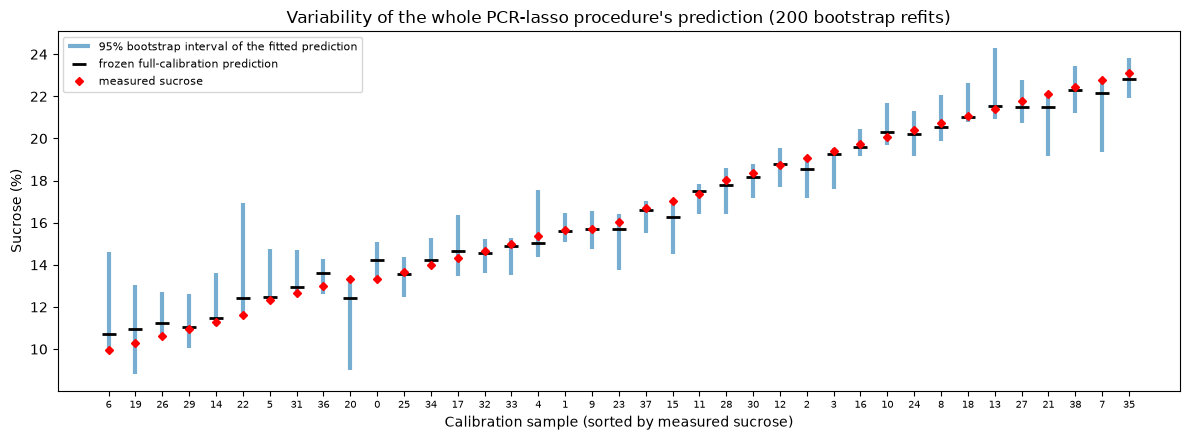

In [55]:
# Q4.7: claim about predictions. Bootstrap the whole procedure (centering, PCA, scaling, tuning, lasso).
B_PROCEDURE = 200
rng_proc = np.random.default_rng(7109)
procedure_preds = np.empty((B_PROCEDURE, len(cookie_y)))
procedure_sizes = np.empty(B_PROCEDURE, dtype=int)
for b in range(B_PROCEDURE):
    idx = rng_proc.integers(0, len(cookie_y), size=len(cookie_y))
    fit_b = fit_pcr_lasso(cookie_X[idx], cookie_y[idx], bootstrap_folds(idx, seed=109 + b))
    procedure_preds[b] = predict_pcr_lasso(fit_b, cookie_X)
    procedure_sizes[b] = len(fit_b["selected"])

final_cal_pred = predict_pcr_lasso(cookie_final, cookie_X)
prediction_uncertainty = pd.DataFrame(
    {"sample": np.arange(len(cookie_y)), "measured": cookie_y, "frozen-fit prediction": final_cal_pred,
     "bootstrap mean": procedure_preds.mean(axis=0), "bootstrap sd": procedure_preds.std(axis=0, ddof=1),
     "lower": np.percentile(procedure_preds, 2.5, axis=0), "upper": np.percentile(procedure_preds, 97.5, axis=0)}
)
prediction_uncertainty["width"] = prediction_uncertainty.upper - prediction_uncertainty.lower
display(prediction_uncertainty.round(3).head(10))
print(f"95% procedure-bootstrap interval width: median {prediction_uncertainty.width.median():.2f}, "
      f"range {prediction_uncertainty.width.min():.2f}-{prediction_uncertainty.width.max():.2f} percentage points")
print(f"Bootstrap SD of a fitted prediction: median {prediction_uncertainty['bootstrap sd'].median():.2f} points")
print(f"Components selected across procedure resamples: median {np.median(procedure_sizes):.0f}, "
      f"range {procedure_sizes.min()}-{procedure_sizes.max()}")

order = np.argsort(cookie_y)
fig, ax = plt.subplots(figsize=(12, 4.5))
xs = np.arange(len(order))
pu = prediction_uncertainty.iloc[order]
ax.vlines(xs, pu.lower, pu.upper, color="tab:blue", lw=3, alpha=0.6, label="95% bootstrap interval of the fitted prediction")
ax.plot(xs, pu["frozen-fit prediction"], "_", color="black", ms=10, mew=2, label="frozen full-calibration prediction")
ax.plot(xs, pu.measured, "D", color="red", ms=4, label="measured sucrose")
ax.set_xticks(xs, pu["sample"], fontsize=7)
ax.set_xlabel("Calibration sample (sorted by measured sucrose)")
ax.set_ylabel("Sucrose (%)")
ax.set_title(f"Variability of the whole PCR-lasso procedure's prediction ({B_PROCEDURE} bootstrap refits)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## Q4.8. Assess original-measurement importance

**3 points**

Our models use principal components, but the original observations are measurements at particular wavelengths. To connect predictive performance back to those measurements, we need an importance analysis in the original input space. Nearby wavelengths can carry overlapping information, and perturbing them can produce unrealistic spectra, so the assessment also needs to explain the limits of what its results support.

**Task:** Choose, justify, and implement an importance analysis for original wavelengths or meaningful wavelength groups. You may adapt an earlier method or propose an alternative. If you use permutation importance, perturb held-out original measurements and pass them through the fitted preprocessing and model without refitting.

**Artifacts:** Importance/variability evidence and limitations.

**Constraints:** Correlated spectra can make perturbations unrealistic and rankings unstable. A large loading indicates that a wavelength contributes strongly to a component’s score. Its predictive role also depends on how the regression uses that component.

**Written response — Q4.8**

**Method.** We measured held-out permutation importance for **20 contiguous bands of 35 wavelengths** (70 nm each), not single wavelengths: neighbors are almost perfectly correlated, so shuffling one creates spikes no real spectrum has. For each outer fold we kept the Q4.5 fit fixed, swapped a whole band between that fold's held-out samples, passed the altered spectra through the fitted transformation and model, and recorded the increase in pooled held-out MSE over all 39 samples (30 repeats per band).

**Results.** Baseline held-out MSE is 1.20. The ranking, not the bar height, is the result: the top bands are 1870–1938, 2080–2148, 1800–1868 and 2010–2078 nm, all inside 1800–2150 nm. Bands near 1520–1660 and 1940–2008 nm come next, and bands below 1300 nm or above 2220 nm rank at the bottom. The implied coefficient curve oscillates between neighboring wavelengths and does not follow this order.

**Limitations.** Swapping a band splices absorbance levels from different doughs, so the MSE increase is not an error the model would make on a real spectrum. With 7–8 held-out samples per fold, few distinct permutations exist, and adjacent bands share information, so neighboring ranks are unstable. A large loading only means a wavelength contributes strongly to a component's score; its predictive role depends on how the regression uses that component. Wavelength-level attribution is unsupported. The band ranking is what these data support.


,rank,mean,std
band (nm),,,
1870-1938,1,83.766280,18.280820
2080-2148,2,75.827370,16.103919
1800-1868,3,68.317220,17.504674
2010-2078,4,44.218267,6.475275
1590-1658,5,29.801177,5.091855
1940-2008,6,28.496875,5.896908
1520-1588,7,27.593205,8.547175
1730-1798,8,18.124988,3.371948
2150-2218,9,15.887589,5.759392


Baseline pooled held-out MSE: 1.203 (sucrose percentage points squared)
Only the rank is interpreted. The MSE increase comes from splicing unreal spectra.


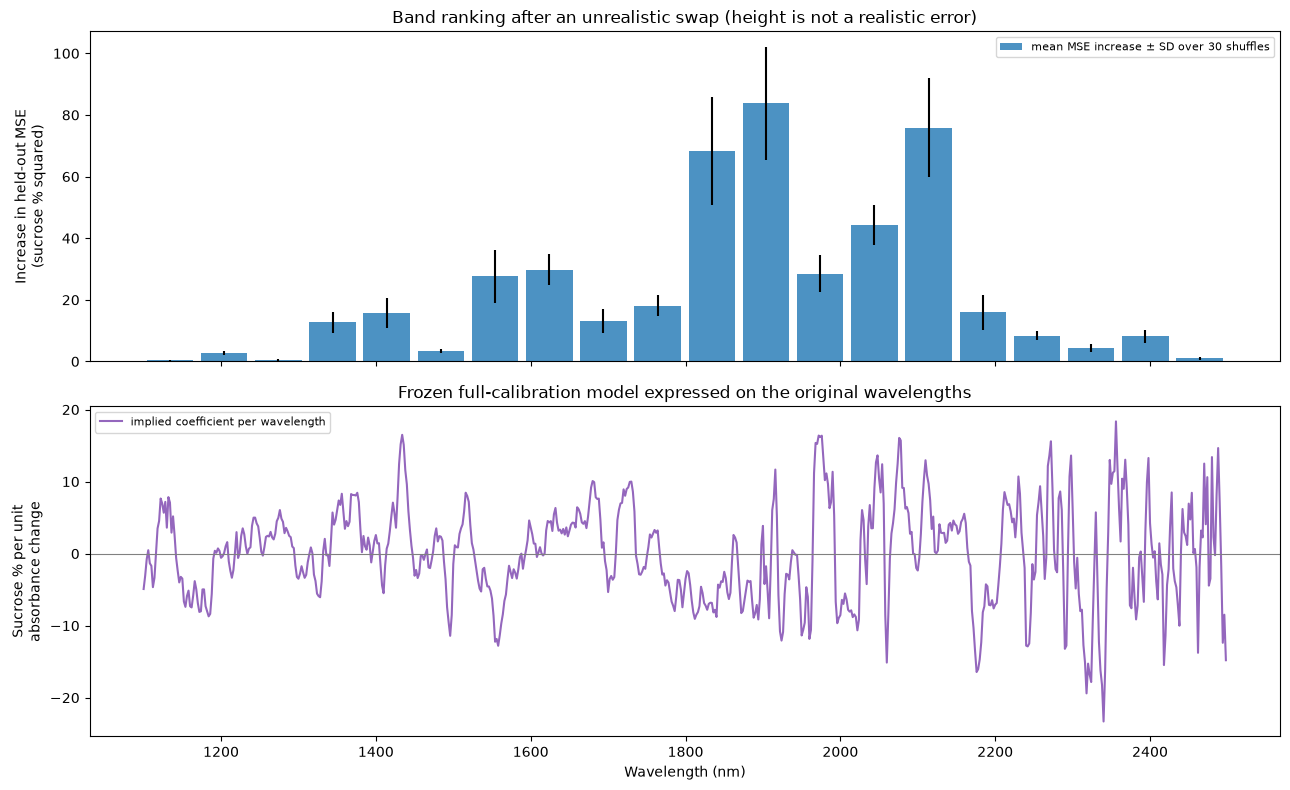

In [56]:
# Q4.8: held-out permutation importance of contiguous wavelength bands.
BAND_WIDTH = 35  # 35 wavelengths x 2 nm = 70 nm per band, 20 bands
band_edges = np.arange(0, len(wavelengths) + 1, BAND_WIDTH)
bands = [np.arange(a, b) for a, b in zip(band_edges[:-1], band_edges[1:])]
band_labels = [f"{wavelengths[b[0]]:.0f}-{wavelengths[b[-1]]:.0f}" for b in bands]
rng_band = np.random.default_rng(9109)

base_sq = np.sum((cookie_y - lasso_pred) ** 2)
band_rows = []
for r in range(N_SHUFFLES):
    for band, label in zip(bands, band_labels):
        perturbed_pred = np.empty(len(cookie_y))
        for fit, (tr, va) in zip(outer_fits, cookie_folds):
            x_va = cookie_X[va].copy()
            # Swap the whole band between held-out samples; the outer-fold fit is not refitted.
            x_va[:, band] = x_va[rng_band.permutation(len(va))][:, band]
            perturbed_pred[va] = predict_pcr_lasso(fit, x_va)
        band_rows.append({"band (nm)": label, "replicate": r,
                          "degradation": (np.sum((cookie_y - perturbed_pred) ** 2) - base_sq) / len(cookie_y)})
band_repeats = pd.DataFrame(band_rows)
band_importance = band_repeats.groupby("band (nm)", sort=False)["degradation"].agg(["mean", "std"])
band_importance.insert(0, "rank", band_importance["mean"].rank(ascending=False).astype(int))
display(band_importance.sort_values("rank"))
print(f"Baseline pooled held-out MSE: {base_sq / len(cookie_y):.3f} (sucrose percentage points squared)")
print("Only the rank is interpreted. The MSE increase comes from splicing unreal spectra.")

# Wavelength coefficient profile implied by the frozen full-calibration fit.
wavelength_coef = cookie_final["pca"]["components"].T @ (cookie_final["model"].coef_ / cookie_final["scale"])

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
centers = [wavelengths[b].mean() for b in bands]
axes[0].bar(centers, band_importance["mean"], width=60, yerr=band_importance["std"], color="tab:blue",
            alpha=0.8, label=f"mean MSE increase ± SD over {N_SHUFFLES} shuffles")
axes[0].set_ylabel("Increase in held-out MSE\n(sucrose % squared)")
axes[0].set_title("Band ranking after an unrealistic swap (height is not a realistic error)")
axes[0].legend(fontsize=8)
axes[1].plot(wavelengths, wavelength_coef, color="tab:purple", label="implied coefficient per wavelength")
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set_xlabel("Wavelength (nm)")
axes[1].set_ylabel("Sucrose % per unit\nabsorbance change")
axes[1].set_title("Frozen full-calibration model expressed on the original wavelengths")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## Q4.9. Interpret and synthesize

**2 points**

The stability, uncertainty, and importance analyses provide evidence for interpreting the fitted model. That interpretation is less direct than in the Ames example because each component combines many original measurements. Connecting the retained components to their loadings lets us explore useful wavelength contrasts while recognizing when the data do not support a clear attribution or a chemical explanation.

**Task:** Plot loadings for components relevant to your model and relate them to the stability, uncertainty, and importance evidence from Q4.6–Q4.8. Explain which wavelength-region patterns the evidence supports and which interpretations it cannot justify.

**Artifacts:** Justified loading plots and concise synthesis.

**Constraints:** No chemical mechanisms required. Limited interpretability is a valid conclusion. Null-based significance is optional, not a prerequisite for descriptive loading interpretation.

**Written response — Q4.9**

We plotted the loadings of the six components selected in at least 80% of fixed-PCA resamples (Q4.6), ordered by full-fit coefficient, with the three most important Q4.8 bands shaded.

- **PC3** (frequency 1.00, coefficient +2.46 per score SD, the largest): a trough near 1880–1990 nm against a peak near 2080 nm.
- **PC5** (1.00, +1.69): negative at 1700–1760 and 2300–2400 nm, positive near 1590 nm, 2080 nm and above 2450 nm.
- **PC1** (0.99, −1.61): positive at every wavelength, so it tracks overall absorbance.
- **PC4** (0.80, +0.86): a step from negative below about 1900 nm to positive at 1930–2150 nm. **PC2** (0.83, −0.74) and **PC6** (0.84, +0.64): weaker terms with broad tilts toward the long-wavelength end.

**Supported:** an overall-absorbance term plus contrasts around 1800–2150 nm: PC2–PC4 change sign within about 1840–2230 nm, PC3 and PC5 are selected in every resample (Q4.6), and shuffling bands there hurts held-out predictions most (Q4.8). **Not supported:** single-wavelength or narrow-peak attribution (the implied coefficient curve oscillates); the exact ranking and size of band importances (Q4.8 includes unstable higher-order components); interpreting the 14 less stable components; reading a loading's sign alone (component signs are arbitrary, only loading × coefficient matters); chemical mechanisms.

,selection frequency,variance share,full-fit coefficient (per score SD)
component,,,
1,0.99,0.9352,-1.6055
2,0.83,0.0481,-0.7373
3,1.00,0.0073,2.4615
4,0.80,0.0044,0.8561
5,1.00,0.0028,1.6868
6,0.84,0.0010,0.6448


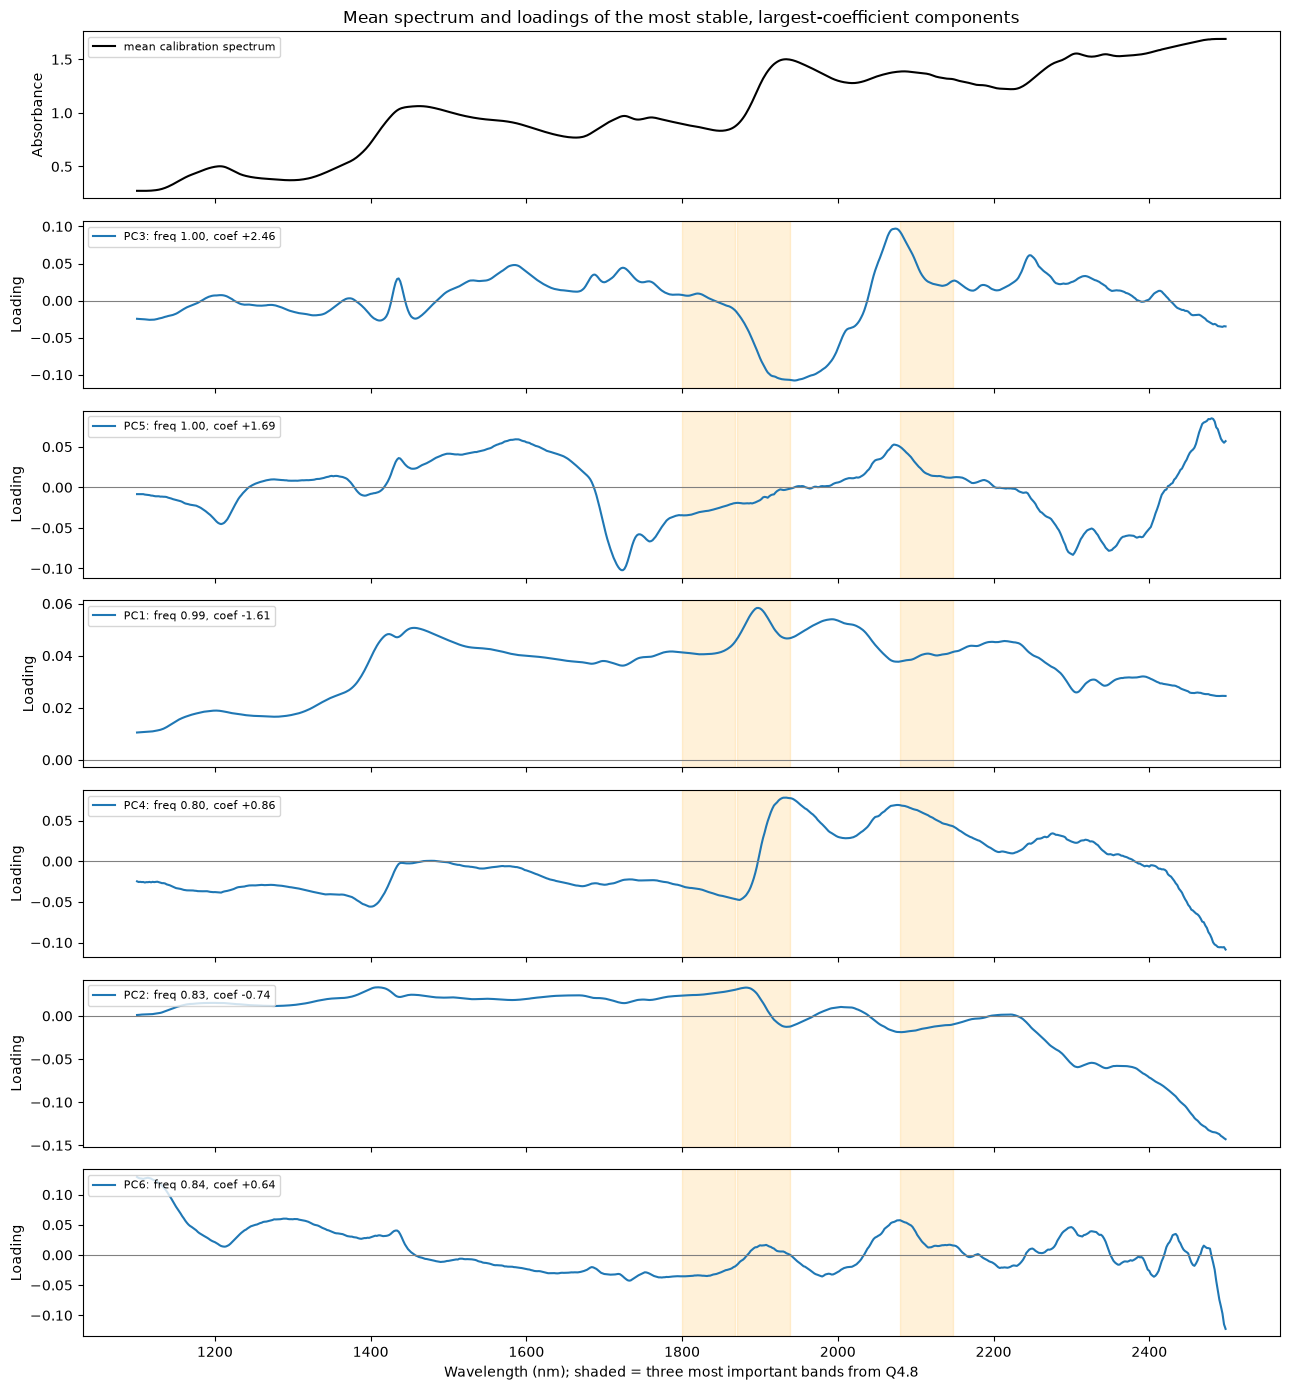

In [57]:
# Q4.9: loadings of the components the model relies on, alongside the Q4.6-Q4.8 evidence.
stable_components = np.flatnonzero(component_frequency >= 0.8)
coef_by_component = pd.Series(cookie_final["model"].coef_, index=np.arange(1, n_components + 1))
display(pd.DataFrame({
    "selection frequency": component_frequency[stable_components],
    "variance share": fixed_pca["share"][stable_components],
    "full-fit coefficient (per score SD)": coef_by_component.iloc[stable_components].to_numpy(),
}, index=pd.Index(stable_components + 1, name="component")).round(4))

show = stable_components[np.argsort(-np.abs(cookie_final["model"].coef_[stable_components]))][:6]
fig, axes = plt.subplots(len(show) + 1, 1, figsize=(13, 2.0 * (len(show) + 1)), sharex=True)
axes[0].plot(wavelengths, cookie_X.mean(axis=0), color="black", label="mean calibration spectrum")
axes[0].set_ylabel("Absorbance")
axes[0].set_title("Mean spectrum and loadings of the most stable, largest-coefficient components")
axes[0].legend(fontsize=8, loc="upper left")
for ax, j in zip(axes[1:], show):
    ax.plot(wavelengths, fixed_pca["components"][j], color="tab:blue",
            label=f"PC{j + 1}: freq {component_frequency[j]:.2f}, coef {cookie_final['model'].coef_[j]:+.2f}")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_ylabel("Loading")
    ax.legend(fontsize=8, loc="upper left")
    for (lo, hi), m in zip([(wavelengths[b[0]], wavelengths[b[-1]]) for b in bands], band_importance["mean"]):
        if m >= band_importance["mean"].nlargest(3).min():
            ax.axvspan(lo, hi, color="orange", alpha=0.15)
axes[-1].set_xlabel("Wavelength (nm); shaded = three most important bands from Q4.8")
plt.tight_layout()
plt.show()

<!-- END QUESTION -->

## Q4.10. Perform final PCR evaluation

**2 points**

All choices about preprocessing, component selection, and fitting have now been made using the calibration data. The separate prediction batch lets us assess how the frozen procedure performs on additional samples. Comparing the final models here completes the predictive evaluation without using this batch to revise their design.

**Task:** Freeze your chosen procedure, refit it on all calibration data, and evaluate it on the separate prediction batch. Compare it with the 95%-variance PCR baseline, refitted on all calibration data. Quantify uncertainty in the performance comparison and state what that uncertainty measures.

**Artifacts:** Final comparison and uncertainty summary.

**Constraints:** Do not revise model choices after examining the prediction batch. Distinguish uncertainty due to the finite evaluation sample from uncertainty due to developing and fitting the model. Because the staff previously explored this batch when designing the exercise, treat this evaluation as an instructional comparison rather than new confirmatory evidence.

Run this question only after all calibration analyses are finished. Call `load_cookie_test()` here, not before this question.


In [58]:
# Q4.10: final evaluation on the separate prediction batch (first and only use).
cookie_X_test, cookie_y_test = load_cookie_test()
final_lasso_test = predict_pcr_lasso(cookie_final, cookie_X_test)  # frozen in Q4.5, refitted on all calibration
final_baseline_test, k_final = pcr_k95(cookie_X, cookie_y, cookie_X_test)
cookie_test_rmse = pd.Series({f"95%-variance PCR (k = {k_final})": rmse(cookie_y_test, final_baseline_test),
                              "lasso on PC scores": rmse(cookie_y_test, final_lasso_test)}, name="test RMSE (sucrose %)")
display(cookie_test_rmse.round(3).to_frame())
print(f"Predicting the calibration mean gives RMSE {rmse(cookie_y_test, cookie_y.mean()):.2f}")

rng_test = np.random.default_rng(10109)
boot_rows = []
for _ in range(5000):
    i = rng_test.integers(0, len(cookie_y_test), size=len(cookie_y_test))
    r_base = rmse(cookie_y_test[i], final_baseline_test[i])
    r_lasso = rmse(cookie_y_test[i], final_lasso_test[i])
    boot_rows.append((r_base, r_lasso, r_base - r_lasso))
boot = np.array(boot_rows)
cookie_test_uncertainty = pd.DataFrame(
    np.percentile(boot, [2.5, 97.5], axis=0).T, columns=["2.5%", "97.5%"],
    index=["95%-variance PCR RMSE", "lasso RMSE", "difference (baseline - lasso)"])
display(cookie_test_uncertainty.round(3))
print(f"Lasso has smaller squared error on {int(np.sum((cookie_y_test - final_lasso_test) ** 2 < (cookie_y_test - final_baseline_test) ** 2))} "
      f"of {len(cookie_y_test)} prediction-batch samples; share of resamples where lasso wins: {np.mean(boot[:, 2] > 0):.3f}")

,test RMSE (sucrose %)
95%-variance PCR (k = 2),4.556
lasso on PC scores,0.992


Predicting the calibration mean gives RMSE 3.90


,2.5%,97.5%
95%-variance PCR RMSE,3.616,5.467
lasso RMSE,0.670,1.346
difference (baseline - lasso),2.575,4.601


Lasso has smaller squared error on 31 of 32 prediction-batch samples; share of resamples where lasso wins: 1.000


**Written response — Q4.10**

We froze the procedure before first calling `load_cookie_test()`: centering, PCA, score standardization and the lasso (5-fold-tuned α = 0.079, 20 components), plus the 95%-variance baseline (k = 2), both refitted on all 39 calibration samples. On the 32 prediction-batch samples:

| model | test RMSE (sucrose %) | 95% bootstrap interval |
|---|---:|---|
| 95%-variance PCR (k = 2) | 4.56 | [3.62, 5.47] |
| lasso on standardized PC scores | **0.99** | [0.67, 1.35] |
| difference (baseline − lasso) | 3.56 | [2.58, 4.60] |

The response-informed procedure is far more accurate: smaller squared error on 31 of 32 samples and ahead in every bootstrap resample. Its test RMSE (0.99) is close to its outer-CV estimate (1.10); the baseline's (4.56) is worse than its CV estimate (3.58) and than predicting the calibration mean (3.90).

**What the uncertainty measures.** The intervals resample the 32 prediction samples with both fitted models fixed, so they capture only the finite evaluation sample, not variability from fitting on a different calibration sample (about ±1 point, Q4.7; unstable higher-order components, Q4.6) or from future batches. Staff explored this batch while designing the exercise, so this is an instructional comparison, not new confirmatory evidence.

## Wrap-up

Both prediction problems, Ames and cookie dough, have now been evaluated after their modeling choices were fixed. Briefly describe one conclusion that depended on distinguishing stability, uncertainty, importance, or significance, and one limitation that remains. You do not need to repeat the earlier syntheses.

<div class="alert alert-info" style="color: #4a4a4a; background-color: #fbe8ff; border-color: #eed4db; border-width: 1px; border-radius: 3px; padding: 10px;">

* How many hours did you spend on this assignment? Store an int or float in `hours_spent_on_hw`. If you worked in a group, report the average per person.
* Briefly describe how you used AI assistance and how you checked its contributions.
* (Optional) Which aspect of the assignment did you find most challenging?

</div>


In [59]:
# Report your hours here. Replace None with an int or float.
hours_spent_on_hw = 7

In [60]:
print("Notebook runtime, seconds:", round(time.time() - notebook_start, 1))


Notebook runtime, seconds: 669.4


**Written response — Wrap-up**

**One conclusion that depended on the distinctions.** In Ames, `Lot_Frontage` was selected in 91% of retuned bootstrap resamples, so it looked stable. In the independent inference sample its coefficient is −0.003 with an interval spanning zero (classical p = 0.74), and shuffling it leaves held-out error unchanged. Selection stability, coefficient evidence and predictive importance answer different questions, and only the separate analyses showed that "selected often" is not "important" or "associated with price". Similarly, the global permutation p-value (0.005) shows that the feature set matters as a whole, not which features.

**One remaining limitation.** All Ames conclusions rest on one fixed split, on neighborhood-median frontage imputation that assumes missingness is close to MAR (Q1.2 showed it clusters by neighborhood and lot type, and MNAR cannot be ruled out), and on independent houses. For the cookie data only 39 calibration spectra were available and the stability analysis held the PCA basis fixed, so uncertainty in the component directions is only partly reflected and everything beyond PCs 1–6 remains uninterpretable.

**AI use.** We used AI (Codex and Claude) only for brainstorming and code-reviewing. All code pieces and written responses were drafted by us. We checked AI contributions by running the test cases and reviewing every line of code.